# SENTINEL AI INFERENCE PIPELINE

## Vehicle Detection + Tracking + ANPR

Pipeline:

Sentinel Stream
→ Decode
→ PTS
→ Frame Buffer
→ Frame Sampling
→ Preprocessing
→ Vehicle Detection
→ Tracking
→ Plate Detection
→ OCR
→ Plate Validation
→ JSON Result

Target:
Real-time CCTV AI inference using Google Colab GPU.

In [2]:
# ============================================================
# STEP 01 — ENVIRONMENT
# ============================================================

import sys
import os
import cv2
import re
import json
import time
import uuid
import subprocess
import requests
import numpy as np

from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from urllib.parse import urljoin

print("=" * 60)
print("SENTINEL AI ENVIRONMENT")
print("=" * 60)

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)

try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print(
            "GPU:",
            torch.cuda.get_device_name(0)
        )

except Exception as e:
    print("PyTorch check failed:", e)

print("=" * 60)

SENTINEL AI ENVIRONMENT
Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
OpenCV: 5.0.0
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
# ============================================================
# SENTINEL AI — PRODUCTION DEPENDENCIES
# ============================================================

!pip install -q \
    ultralytics \
    easyocr \
    huggingface_hub \
    fastapi \
    uvicorn \
    pydantic \
    opencv-python-headless \
    psutil

In [4]:
import torch
import cv2
import ultralytics
import easyocr
import fastapi

print("=" * 70)
print("DEPENDENCY VERIFICATION")
print("=" * 70)

print("PyTorch     :", torch.__version__)
print("CUDA        :", torch.cuda.is_available())
print("OpenCV      :", cv2.__version__)
print("Ultralytics :", ultralytics.__version__)
print("EasyOCR     :", easyocr.__version__)
print("FastAPI     :", fastapi.__version__)

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))

print("=" * 70)

DEPENDENCY VERIFICATION
PyTorch     : 2.11.0+cu128
CUDA        : True
OpenCV      : 5.0.0
Ultralytics : 8.4.138
EasyOCR     : 1.7.2
FastAPI     : 0.141.1
GPU         : Tesla T4


In [5]:
# ============================================================
# SENTINEL AI — PRODUCTION CONFIGURATION
# ============================================================

from dataclasses import dataclass
import torch
import os


@dataclass
class ProductionConfig:

    # --------------------------------------------------------
    # CAMERA
    # --------------------------------------------------------

    camera_id: str = "cam01"

    # --------------------------------------------------------
    # AI DEVICE
    # --------------------------------------------------------

    device: object = 0 if torch.cuda.is_available() else "cpu"

    # --------------------------------------------------------
    # MODEL WEIGHTS (CENTRALIZED IN weights/ DIRECTORY)
    # --------------------------------------------------------

    weights_dir: str = "weights"

    # Primary Indian Traffic YOLOv11-S (14 classes: auto-rickshaws, bikes, cars, trucks, buses...)
    vehicle_model: str = os.path.join(weights_dir, "uvh26_yolo11s.pt")

    # Secondary specialized traffic model (CNG auto-rickshaws, cycle-rickshaws...)
    secondary_model: str = os.path.join(weights_dir, "bd_traffic.pt")

    # Base COCO YOLOv11-N model
    coco_model: str = os.path.join(weights_dir, "yolo11n.pt")

    # License plate localization model
    plate_model: str = os.path.join(weights_dir, "license-plate-finetune-v1n.pt")

    vehicle_imgsz: int = 640

    vehicle_conf: float = 0.25

    vehicle_iou: float = 0.45

    # AI processing rate.
    ai_fps: float = 5.0

    # --------------------------------------------------------
    # TRACKER
    # --------------------------------------------------------

    tracker: str = "bytetrack.yaml"

    # --------------------------------------------------------
    # LICENSE PLATE DETECTOR
    # --------------------------------------------------------

    plate_imgsz: int = 640

    plate_conf: float = 0.20

    # --------------------------------------------------------
    # OCR
    # --------------------------------------------------------

    ocr_min_confidence: float = 0.50

    min_plate_observations: int = 2

    # --------------------------------------------------------
    # VIDEO
    # --------------------------------------------------------

    display_width: int = 1280

    display_height: int = 720

    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    max_inference_latency_ms: float = 250.0

    max_allowed_frame_drop_percent: float = 5.0

    # --------------------------------------------------------
    # API
    # --------------------------------------------------------

    api_host: str = "0.0.0.0"

    api_port: int = 8000

    schema_version: str = "1.0"


CONFIG = ProductionConfig()


print("=" * 70)
print("SENTINEL AI — PRODUCTION CONFIGURATION")
print("=" * 70)

print(f"Camera ID             : {CONFIG.camera_id}")
print(f"Device                : {CONFIG.device}")
print(f"Weights Directory     : {CONFIG.weights_dir}")
print(f"Primary Vehicle model : {CONFIG.vehicle_model}")
print(f"Secondary Model       : {CONFIG.secondary_model}")
print(f"COCO Base Model       : {CONFIG.coco_model}")
print(f"Plate model           : {CONFIG.plate_model}")
print(f"Vehicle image size    : {CONFIG.vehicle_imgsz}")
print(f"Vehicle confidence    : {CONFIG.vehicle_conf}")
print(f"AI processing FPS     : {CONFIG.ai_fps}")
print(f"Tracker               : {CONFIG.tracker}")
print(f"Plate confidence      : {CONFIG.plate_conf}")
print(f"OCR minimum confidence: {CONFIG.ocr_min_confidence}")
print(f"API                   : {CONFIG.api_host}:{CONFIG.api_port}")
print("=" * 70)


if torch.cuda.is_available():
    print()
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print()
    print("GPU: CPU mode")


SENTINEL AI — PRODUCTION CONFIGURATION
Camera ID             : cam01
Device                : 0
Vehicle model         : yolo11n.pt
Vehicle image size    : 640
Vehicle confidence    : 0.25
Vehicle IoU           : 0.45
AI processing FPS     : 5.0
Tracker               : bytetrack.yaml
Plate confidence      : 0.2
OCR minimum confidence: 0.5
API                   : 0.0.0.0:8000

GPU: Tesla T4
CUDA: 12.8


In [6]:
# ============================================================
# CELL 03 — SENTINEL AI PRODUCTION MODEL REGISTRY (ALL MODELS)
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import torch
import os


class SentinelModelRegistry:
    """
    Centralized production model manager.
    Loads and serves all models from the centralized weights/ folder.
    """

    def __init__(self, config):

        self.config = config

        self.vehicle_model = None
        self.secondary_model = None
        self.coco_model = None
        self.plate_model = None
        self.ocr_reader = None

    # --------------------------------------------------------
    # PRIMARY VEHICLE DETECTOR (Indian Traffic YOLOv11s)
    # --------------------------------------------------------

    def load_vehicle_model(self):

        print()
        print("-" * 70)
        print("Loading Primary Vehicle Detection Model (Indian Traffic)")
        print("-" * 70)

        self.vehicle_model = YOLO(self.config.vehicle_model)

        print("Model  :", self.config.vehicle_model)
        print("Classes:", len(self.vehicle_model.names), list(self.vehicle_model.names.values())[:8])

        return self.vehicle_model

    # --------------------------------------------------------
    # SECONDARY VEHICLE DETECTOR (Auto-Rickshaw / Traffic Boost)
    # --------------------------------------------------------

    def load_secondary_model(self):

        if os.path.exists(self.config.secondary_model):
            print()
            print("-" * 70)
            print("Loading Secondary Traffic Model (Rickshaw & Traffic Boost)")
            print("-" * 70)

            self.secondary_model = YOLO(self.config.secondary_model)
            print("Model  :", self.config.secondary_model)
            print("Classes:", len(self.secondary_model.names))

        return self.secondary_model

    # --------------------------------------------------------
    # BASE COCO DETECTOR (General Vehicles & Fallback)
    # --------------------------------------------------------

    def load_coco_model(self):

        if os.path.exists(self.config.coco_model):
            print()
            print("-" * 70)
            print("Loading COCO Base Model (General Vehicle Fallback)")
            print("-" * 70)

            self.coco_model = YOLO(self.config.coco_model)
            print("Model  :", self.config.coco_model)
            print("Classes:", len(self.coco_model.names))

        return self.coco_model

    # --------------------------------------------------------
    # LICENSE PLATE DETECTOR (Fine-tuned YOLO)
    # --------------------------------------------------------

    def load_plate_model(self):

        print()
        print("-" * 70)
        print("Loading License Plate Localization Model")
        print("-" * 70)

        # Loads directly from weights folder
        plate_path = self.config.plate_model
        if not os.path.exists(plate_path):
            from huggingface_hub import hf_hub_download
            plate_path = hf_hub_download(
                repo_id="morsetechlab/yolov11-license-plate-detection",
                filename="license-plate-finetune-v1n.pt"
            )

        self.plate_model = YOLO(plate_path)

        print("Plate model:", plate_path)
        print("Classes    :", self.plate_model.names)

        return self.plate_model

    # --------------------------------------------------------
    # OCR ENGINE
    # --------------------------------------------------------

    def load_ocr(self):

        print()
        print("-" * 70)
        print("Loading EasyOCR Engine")
        print("-" * 70)

        import easyocr

        self.ocr_reader = easyocr.Reader(
            ["en"],
            gpu=torch.cuda.is_available(),
            verbose=False
        )

        print("OCR engine: EasyOCR")
        print("GPU       :", torch.cuda.is_available())

        return self.ocr_reader

    # --------------------------------------------------------
    # LOAD ALL MODELS
    # --------------------------------------------------------

    def load_all(self):

        self.load_vehicle_model()
        self.load_secondary_model()
        self.load_coco_model()
        self.load_plate_model()
        self.load_ocr()

        print()
        print("=" * 70)
        print("✅ ALL SENTINEL PRODUCTION AI MODELS LOADED & READY")
        print("=" * 70)

        if torch.cuda.is_available():
            print("GPU               :", torch.cuda.get_device_name(0))

        print("Primary detector  :", self.vehicle_model is not None)
        print("Secondary detector:", self.secondary_model is not None)
        print("COCO Base model   :", self.coco_model is not None)
        print("Plate detector    :", self.plate_model is not None)
        print("OCR reader        :", self.ocr_reader is not None)


# ------------------------------------------------------------
# CREATE GLOBAL PRODUCTION REGISTRY
# ------------------------------------------------------------

MODELS = SentinelModelRegistry(CONFIG)
MODELS.load_all()



----------------------------------------------------------------------
Loading vehicle detection model
----------------------------------------------------------------------
Model: yolo11n.pt
Classes: 80

----------------------------------------------------------------------
Loading license plate detection model
----------------------------------------------------------------------


Plate model: /root/.cache/huggingface/hub/models--morsetechlab--yolov11-license-plate-detection/snapshots/251a30d7daedca065f56e04b0af04052c907c68f/license-plate-finetune-v1n.pt
Classes: {0: 'License_Plate'}

----------------------------------------------------------------------
Loading EasyOCR
----------------------------------------------------------------------
OCR engine: EasyOCR
GPU: True

✅ SENTINEL PRODUCTION MODEL REGISTRY READY
GPU: Tesla T4
Vehicle detector: True
Plate detector: True
OCR: True


In [7]:
# ============================================================
# CELL 04 — PRODUCTION MODEL HEALTH CHECK
# ============================================================

import torch
import os


def production_model_health_check():

    print("=" * 70)
    print("SENTINEL AI — UNIFIED MODEL HEALTH CHECK")
    print("=" * 70)

    errors = []

    # [GPU]
    print("\n[GPU / COMPUTE]")
    if torch.cuda.is_available():
        print("Status      : ✅ AVAILABLE")
        print("Device      :", torch.cuda.get_device_name(0))
        props = torch.cuda.get_device_properties(0)
        print("VRAM        :", round(props.total_memory / (1024 ** 3), 2), "GB")
    else:
        print("Status      : ⚠️ CPU MODE")

    # [WEIGHTS DIRECTORY]
    print("\n[WEIGHTS DIRECTORY]")
    if os.path.exists(CONFIG.weights_dir):
        files = os.listdir(CONFIG.weights_dir)
        print(f"Status      : ✅ READY ({len(files)} model files in {CONFIG.weights_dir})")
        for f in files:
            print(f" - {f}")
    else:
        errors.append("Weights directory not found")
        print("Status      : ❌ NOT FOUND")

    # [PRIMARY VEHICLE MODEL]
    print("\n[PRIMARY VEHICLE DETECTOR]")
    if MODELS.vehicle_model is None:
        errors.append("Primary vehicle detector not loaded")
        print("Status      : ❌ FAILED")
    else:
        print("Status      : ✅ READY")
        print("Model       :", CONFIG.vehicle_model)
        print("Classes     :", len(MODELS.vehicle_model.names))

    # [SECONDARY TRAFFIC MODEL]
    print("\n[SECONDARY TRAFFIC DETECTOR]")
    if MODELS.secondary_model is None:
        print("Status      : ⚠️ NOT LOADED (Optional)")
    else:
        print("Status      : ✅ READY")
        print("Model       :", CONFIG.secondary_model)

    # [COCO BASE MODEL]
    print("\n[COCO BASE MODEL]")
    if MODELS.coco_model is None:
        print("Status      : ⚠️ NOT LOADED (Optional)")
    else:
        print("Status      : ✅ READY")
        print("Model       :", CONFIG.coco_model)

    # [PLATE MODEL]
    print("\n[PLATE DETECTOR]")
    if MODELS.plate_model is None:
        errors.append("Plate detector not loaded")
        print("Status      : ❌ FAILED")
    else:
        print("Status      : ✅ READY")
        print("Classes     :", MODELS.plate_model.names)

    # [OCR]
    print("\n[OCR ENGINE]")
    if MODELS.ocr_reader is None:
        errors.append("OCR engine not loaded")
        print("Status      : ❌ FAILED")
    else:
        print("Status      : ✅ READY (EasyOCR)")

    print()
    print("=" * 70)
    if errors:
        print("❌ MODEL HEALTH CHECK FAILED")
        for error in errors:
            print(" -", error)
        raise RuntimeError("Production model health check failed.")
    else:
        print("✅ ALL PRODUCTION AI MODELS HEALTHY AND OPERATIONAL")
    print("=" * 70)


production_model_health_check()


SENTINEL AI — MODEL HEALTH CHECK

[GPU]
Status      : ✅ AVAILABLE
Device      : Tesla T4
VRAM        : 14.56 GB

[VEHICLE DETECTOR]
Status      : ✅ READY
Model       : yolo11n.pt
Classes     : 80

[PLATE DETECTOR]
Status      : ✅ READY
Classes     : {0: 'License_Plate'}

[OCR]
Status      : ✅ READY
Engine      : EasyOCR

✅ ALL PRODUCTION AI MODELS HEALTHY


In [8]:
# ============================================================
# STEP 07 — SENTINEL CONNECTION / SESSION
# ============================================================

import requests

SENTINEL_BASE_URL = "https://cctv.corp8.cloud"

session = requests.Session()

session.headers.update({
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 "
        "(KHTML, like Gecko) "
        "Chrome/131.0 Safari/537.36"
    ),
    "Accept": (
        "text/html,application/xhtml+xml,"
        "application/xml;q=0.9,*/*;q=0.8"
    ),
    "Accept-Language": "en-US,en;q=0.9",
})

print("=" * 70)
print("SENTINEL CONNECTION")
print("=" * 70)

print("Base URL :", SENTINEL_BASE_URL)
print("Session  :", type(session).__name__)

print()
print("✅ Sentinel session object ready.")
print("=" * 70)

SENTINEL CONNECTION
Base URL : https://cctv.corp8.cloud
Session  : Session

✅ Sentinel session object ready.


In [9]:
# ============================================================
# STEP 08 — SENTINEL AUTHENTICATION
# CURRENT FORM: REGISTERED EMAIL + ACCESS PASSWORD
# ============================================================

from getpass import getpass

print("=" * 70)
print("SENTINEL AUTHENTICATION")
print("=" * 70)

login_url = (
    SENTINEL_BASE_URL
    + "/auth/login"
)

# ------------------------------------------------------------
# STEP 1 — Load login page
# ------------------------------------------------------------

login_page = session.get(
    login_url,
    timeout=20,
    allow_redirects=True
)

print(
    "Login page status :",
    login_page.status_code
)

print(
    "Login page URL    :",
    login_page.url
)

if login_page.status_code != 200:
    raise RuntimeError(
        "Unable to load Sentinel login page."
    )

# ------------------------------------------------------------
# STEP 2 — Get credentials
# ------------------------------------------------------------

email = input(
    "Enter registered Sentinel email: "
).strip()

password = getpass(
    "Enter Sentinel access password: "
)

if not email:
    raise ValueError(
        "Sentinel email cannot be empty."
    )

if not password:
    raise ValueError(
        "Sentinel access password cannot be empty."
    )

# ------------------------------------------------------------
# STEP 3 — Submit login form
# ------------------------------------------------------------

response = session.post(
    login_url,
    data={
        "email": email,
        "password": password,
    },
    headers={
        "Referer": login_url,
        "Origin": SENTINEL_BASE_URL,
    },
    timeout=20,
    allow_redirects=True,
)

# ------------------------------------------------------------
# STEP 4 — Authentication result
# ------------------------------------------------------------

print()
print("-" * 70)

print(
    "Authentication status :",
    response.status_code
)

print(
    "Final URL             :",
    response.url
)

print(
    "Session cookies       :",
    list(session.cookies.keys())
)

print("-" * 70)

# ------------------------------------------------------------
# STEP 5 — Validate
# ------------------------------------------------------------

if (
    response.status_code == 200
    and response.url.rstrip("/")
        != login_url.rstrip("/")
):

    print()
    print("✅ Sentinel authentication successful.")
    print("✅ Authenticated web session established.")

else:

    print()
    print("❌ Sentinel authentication failed.")
    print()
    print(
        "The server returned the login page."
    )

    raise RuntimeError(
        "Sentinel authentication failed. "
        "Verify the registered email and access password."
    )

SENTINEL AUTHENTICATION
Login page status : 200
Login page URL    : https://cctv.corp8.cloud/auth/login
Enter registered Sentinel email: p21044804@gmail.com
Enter Sentinel access password: ··········

----------------------------------------------------------------------
Authentication status : 200
Final URL             : https://cctv.corp8.cloud/
Session cookies       : ['sentinel']
----------------------------------------------------------------------

✅ Sentinel authentication successful.
✅ Authenticated web session established.


In [10]:
# ============================================================
# STEP 09 — CAMERA CATALOGUE / DYNAMIC DISCOVERY
# ============================================================

print("=" * 70)
print("SENTINEL CAMERA CATALOGUE")
print("=" * 70)

catalogue_url = (
    SENTINEL_BASE_URL
    + "/cameras.json"
)

response = session.get(
    catalogue_url,
    timeout=20,
    allow_redirects=False
)

print(
    "HTTP status :",
    response.status_code
)

print(
    "Content-Type:",
    response.headers.get("Content-Type")
)

print(
    "URL         :",
    response.url
)

# ------------------------------------------------------------
# Authentication check
# ------------------------------------------------------------

if response.status_code in (
    301, 302, 303, 307, 308
):

    location = response.headers.get(
        "Location",
        ""
    )

    print(
        "Redirect    :",
        location
    )

    if "/auth/login" in location:

        raise RuntimeError(
            "Sentinel session is not authenticated."
        )

# ------------------------------------------------------------
# HTTP validation
# ------------------------------------------------------------

if response.status_code != 200:

    raise RuntimeError(
        f"Camera catalogue request failed: "
        f"HTTP {response.status_code}"
    )

# ------------------------------------------------------------
# JSON validation
# ------------------------------------------------------------

content_type = response.headers.get(
    "Content-Type",
    ""
).lower()

if "application/json" not in content_type:

    raise RuntimeError(
        "Camera catalogue did not return JSON."
    )

# ------------------------------------------------------------
# Parse camera catalogue
# ------------------------------------------------------------

cameras = response.json()

if not isinstance(cameras, list):

    raise RuntimeError(
        "Unexpected camera catalogue format."
    )

print()
print(
    "Number of cameras:",
    len(cameras)
)

print()
print("AVAILABLE CAMERAS")
print("-" * 70)

for camera in cameras:

    print(
        f"{camera.get('id')} | "
        f"{camera.get('name')}"
    )

print()
print("=" * 70)
print("✅ DYNAMIC CAMERA DISCOVERY SUCCESSFUL")
print("=" * 70)

SENTINEL CAMERA CATALOGUE
HTTP status : 200
Content-Type: application/json
URL         : https://cctv.corp8.cloud/cameras.json

Number of cameras: 30

AVAILABLE CAMERAS
----------------------------------------------------------------------
cam01 | 01 Chiman bhai Bridge
cam02 | 02 Janpath
cam03 | 03 O.N.G.C. Office
cam04 | 04 Paldi Circle
cam05 | 05 Visat teen Rasta
cam06 | 06 Timbavadi gate-Junagadh
cam07 | 07 hero-showroom-gir-somnath
cam08 | 08 majewadi-gate-junagadh
cam09 | 09 new-bypass-near-by-circle-junagadh-2
cam10 | 10 char-chowk-road-2-junagadh
cam11 | 11 dolatpara-junagadh
cam12 | 12 Tri Mandir Adalaj Tollnaka
cam13 | 13 CN Vidhyalaya
cam14 | 14 Delight RLVD
cam15 | 15 Suvidha park
cam16 | 16 Visat P2
cam17 | 17 Rajkot Bus Port CCTV
cam18 | 18 Rajkot CCTV
cam19 | 19 KHAPARIA GRAM PANCHAYAT , TALUKA GANDEVI, DISTRICT NAVSARI
cam20 | 20 Mohanpura
cam21 | 23 Patan Dethali Char Rasta
cam22 | 28 BK Mervada tran Rasta
cam23 | 30 kheram
cam24 | 33 dehgam
cam25 | 34 dhanori
cam26 | 3

In [11]:
# ============================================================
# STEP 10 — PRODUCTION CAMERA REGISTRY
# ============================================================

from dataclasses import dataclass
from typing import Optional


@dataclass
class CameraInfo:
    camera_id: str
    name: str
    raw: dict


# ------------------------------------------------------------
# Build registry
# ------------------------------------------------------------

CAMERA_REGISTRY = {}

for camera in cameras:

    camera_id = str(
        camera.get("id", "")
    ).strip()

    camera_name = str(
        camera.get("name", "")
    ).strip()

    if not camera_id:
        continue

    CAMERA_REGISTRY[camera_id] = CameraInfo(
        camera_id=camera_id,
        name=camera_name,
        raw=camera
    )


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

if not CAMERA_REGISTRY:

    raise RuntimeError(
        "Camera registry is empty."
    )


print("=" * 70)
print("SENTINEL CAMERA REGISTRY")
print("=" * 70)

print(
    "Registered cameras:",
    len(CAMERA_REGISTRY)
)

print()

for camera_id, camera in CAMERA_REGISTRY.items():

    print(
        f"{camera.camera_id:<8} | "
        f"{camera.name}"
    )

print()
print("=" * 70)
print("✅ PRODUCTION CAMERA REGISTRY READY")
print("=" * 70)

SENTINEL CAMERA REGISTRY
Registered cameras: 30

cam01    | 01 Chiman bhai Bridge
cam02    | 02 Janpath
cam03    | 03 O.N.G.C. Office
cam04    | 04 Paldi Circle
cam05    | 05 Visat teen Rasta
cam06    | 06 Timbavadi gate-Junagadh
cam07    | 07 hero-showroom-gir-somnath
cam08    | 08 majewadi-gate-junagadh
cam09    | 09 new-bypass-near-by-circle-junagadh-2
cam10    | 10 char-chowk-road-2-junagadh
cam11    | 11 dolatpara-junagadh
cam12    | 12 Tri Mandir Adalaj Tollnaka
cam13    | 13 CN Vidhyalaya
cam14    | 14 Delight RLVD
cam15    | 15 Suvidha park
cam16    | 16 Visat P2
cam17    | 17 Rajkot Bus Port CCTV
cam18    | 18 Rajkot CCTV
cam19    | 19 KHAPARIA GRAM PANCHAYAT , TALUKA GANDEVI, DISTRICT NAVSARI
cam20    | 20 Mohanpura
cam21    | 23 Patan Dethali Char Rasta
cam22    | 28 BK Mervada tran Rasta
cam23    | 30 kheram
cam24    | 33 dehgam
cam25    | 34 dhanori
cam26    | 35 TANKAL
cam27    | 36 bilimora
cam28    | 37 bilimora
cam29    | 38 bilimora
cam30    | Gandhidham Rambaugh p2



In [12]:
# ============================================================
# STEP 11 — CAMERA SELECTION
# ============================================================

print("=" * 70)
print("CAMERA SELECTION")
print("=" * 70)

available_ids = list(
    CAMERA_REGISTRY.keys()
)

print(
    "Available camera IDs:",
    ", ".join(available_ids)
)

selected_camera_id = input(
    "\nEnter camera ID for AI testing "
    "(example: cam01): "
).strip()

if selected_camera_id not in CAMERA_REGISTRY:

    raise ValueError(
        f"Unknown camera ID: {selected_camera_id}"
    )

SELECTED_CAMERA = CAMERA_REGISTRY[
    selected_camera_id
]

# Keep CONFIG synchronized
CONFIG.camera_id = selected_camera_id

print()
print("Selected camera:")
print("ID  :", SELECTED_CAMERA.camera_id)
print("Name:", SELECTED_CAMERA.name)

print()
print("✅ Camera selected successfully.")

CAMERA SELECTION
Available camera IDs: cam01, cam02, cam03, cam04, cam05, cam06, cam07, cam08, cam09, cam10, cam11, cam12, cam13, cam14, cam15, cam16, cam17, cam18, cam19, cam20, cam21, cam22, cam23, cam24, cam25, cam26, cam27, cam28, cam29, cam30

Enter camera ID for AI testing (example: cam01): cam01

Selected camera:
ID  : cam01
Name: 01 Chiman bhai Bridge

✅ Camera selected successfully.


In [13]:
# ============================================================
# STEP 12 — INSPECT CAMERA STREAM METADATA
# ============================================================

import json

print("=" * 70)
print("CAMERA STREAM METADATA")
print("=" * 70)

camera_raw = SELECTED_CAMERA.raw

print("Camera ID  :", SELECTED_CAMERA.camera_id)
print("Camera Name:", SELECTED_CAMERA.name)

print()
print("Available metadata fields:")
print("-" * 70)

for key, value in camera_raw.items():

    # Never print credentials/tokens/passwords.
    sensitive = any(
        word in key.lower()
        for word in [
            "password",
            "passwd",
            "token",
            "secret",
            "credential",
            "auth"
        ]
    )

    if sensitive:
        print(f"{key}: [REDACTED]")

    else:
        # For URLs, only show the URL structure.
        if isinstance(value, str) and (
            value.startswith("rtsp://")
            or value.startswith("http://")
            or value.startswith("https://")
        ):
            print(f"{key}: [URL PRESENT]")

        else:
            print(f"{key}: {type(value).__name__}")

print()
print("=" * 70)

CAMERA STREAM METADATA
Camera ID  : cam01
Camera Name: 01 Chiman bhai Bridge

Available metadata fields:
----------------------------------------------------------------------
id: str
name: str



In [14]:
# ============================================================
# STEP 13 — STREAM FIELD DISCOVERY
# ============================================================

print("=" * 70)
print("STREAM-RELATED FIELDS")
print("=" * 70)

stream_keywords = [
    "rtsp",
    "hls",
    "webrtc",
    "whep",
    "stream",
    "url",
    "playback",
    "live"
]

found = False

for key, value in camera_raw.items():

    key_lower = str(key).lower()

    if any(
        keyword in key_lower
        for keyword in stream_keywords
    ):

        found = True

        if isinstance(value, str):

            if (
                value.startswith("rtsp://")
                or value.startswith("http://")
                or value.startswith("https://")
            ):
                print(
                    f"{key}: [STREAM URL PRESENT]"
                )

            else:
                print(
                    f"{key}: {value}"
                )

        else:

            print(
                f"{key}: {type(value).__name__}"
            )

if not found:
    print(
        "⚠️ No obvious stream fields found "
        "in the camera object."
    )

print()
print("=" * 70)

STREAM-RELATED FIELDS
⚠️ No obvious stream fields found in the camera object.



In [16]:
# ============================================================
# STEP 14 — RTSP CREDENTIALS
# ============================================================

from getpass import getpass

print("=" * 70)
print("SENTINEL RTSP CREDENTIALS")
print("=" * 70)

# The same registered Sentinel email is normally used
# for the RTSP service.

RTSP_EMAIL = input(
    "Enter registered Sentinel email for RTSP: "
).strip()

RTSP_PASSWORD = getpass(
    "Enter Sentinel access password for RTSP: "
)

if not RTSP_EMAIL:
    raise ValueError(
        "RTSP email cannot be empty."
    )

if not RTSP_PASSWORD:
    raise ValueError(
        "RTSP password cannot be empty."
    )

print()
print("RTSP credentials captured securely.")
print("Email  :", RTSP_EMAIL)
print("Password: [REDACTED]")
print("=" * 70)

SENTINEL RTSP CREDENTIALS
Enter registered Sentinel email for RTSP: p21044804@gmail.com
Enter Sentinel access password for RTSP: ··········

RTSP credentials captured securely.
Email  : p21044804@gmail.com
Password: [REDACTED]


In [17]:
# ============================================================
# STEP 15 — BUILD AUTHENTICATED RTSP URL
# ============================================================

from urllib.parse import quote

encoded_email = quote(
    RTSP_EMAIL,
    safe=""
)

encoded_password = quote(
    RTSP_PASSWORD,
    safe=""
)

camera_id = SELECTED_CAMERA.camera_id

RTSP_URL = (
    f"rtsp://"
    f"{encoded_email}:"
    f"{encoded_password}"
    f"@103.250.160.189:8554"
    f"/stream/{camera_id}"
)

print("=" * 70)
print("RTSP STREAM CONFIGURATION")
print("=" * 70)

print("Camera ID :", camera_id)
print("Camera    :", SELECTED_CAMERA.name)
print("Protocol  : RTSP")
print("Transport : TCP")
print("Endpoint  : 103.250.160.189:8554")
print("Stream    :", f"/stream/{camera_id}")

# NEVER print RTSP_URL
print()
print("Authenticated RTSP URL constructed.")
print("Credential-containing URL: [REDACTED]")
print("=" * 70)

RTSP STREAM CONFIGURATION
Camera ID : cam01
Camera    : 01 Chiman bhai Bridge
Protocol  : RTSP
Transport : TCP
Endpoint  : 103.250.160.189:8554
Stream    : /stream/cam01

Authenticated RTSP URL constructed.
Credential-containing URL: [REDACTED]


In [18]:
# ============================================================
# STEP 16 — OPENCV RTSP TCP CONFIGURATION
# ============================================================

import os
import cv2

os.environ[
    "OPENCV_FFMPEG_CAPTURE_OPTIONS"
] = "rtsp_transport;tcp"

print("=" * 70)
print("OPENCV RTSP CONFIGURATION")
print("=" * 70)

print(
    "FFmpeg RTSP transport:",
    os.environ["OPENCV_FFMPEG_CAPTURE_OPTIONS"]
)

print("Backend              : FFmpeg")
print("Transport            : TCP")

print()
print("✅ RTSP TCP configuration ready.")
print("=" * 70)

OPENCV RTSP CONFIGURATION
FFmpeg RTSP transport: rtsp_transport;tcp
Backend              : FFmpeg
Transport            : TCP

✅ RTSP TCP configuration ready.


In [19]:
# ============================================================
# STEP 17 — RTSP CONNECTIVITY TEST
# ============================================================

import cv2
import time

print("=" * 70)
print("SENTINEL RTSP CONNECTIVITY TEST")
print("=" * 70)

print("Camera ID :", SELECTED_CAMERA.camera_id)
print("Camera    :", SELECTED_CAMERA.name)
print("Transport : TCP")
print()

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():

    cap.release()

    raise RuntimeError(
        "❌ Unable to open Sentinel RTSP stream."
    )

print("✅ RTSP stream opened.")

# ------------------------------------------------------------
# Read initial frames
# ------------------------------------------------------------

frames_read = 0
start_time = time.monotonic()

while frames_read < 10:

    ok, frame = cap.read()

    if not ok:

        print(
            f"⚠️ Frame read failed at "
            f"frame {frames_read + 1}"
        )

        break

    frames_read += 1

    if frames_read == 1:

        height, width = frame.shape[:2]

        print(
            "Resolution:",
            f"{width}x{height}"
        )

elapsed = time.monotonic() - start_time

cap.release()

print()
print("-" * 70)

print(
    "Frames read:",
    frames_read
)

print(
    "Test time:",
    round(elapsed, 2),
    "seconds"
)

if frames_read == 0:

    raise RuntimeError(
        "RTSP opened but no frames were received."
    )

print()
print("✅ SENTINEL RTSP STREAM TEST PASSED")
print("=" * 70)

SENTINEL RTSP CONNECTIVITY TEST
Camera ID : cam01
Camera    : 01 Chiman bhai Bridge
Transport : TCP

✅ RTSP stream opened.
Resolution: 1920x1080

----------------------------------------------------------------------
Frames read: 10
Test time: 0.09 seconds

✅ SENTINEL RTSP STREAM TEST PASSED


In [20]:
# ============================================================
# RESTORING LICENSE PLATE DETECTOR FROM LOCAL WEIGHTS
# ============================================================

from pathlib import Path
from ultralytics import YOLO
import os

print("=" * 70)
print("RESTORING LICENSE PLATE DETECTOR")
print("=" * 70)

PLATE_MODEL_PATH = CONFIG.plate_model

if not os.path.exists(PLATE_MODEL_PATH):
    from huggingface_hub import hf_hub_download
    print("Downloading plate model from Hugging Face...")
    PLATE_MODEL_PATH = hf_hub_download(
        repo_id="morsetechlab/yolov11-license-plate-detection",
        filename="license-plate-finetune-v1n.pt"
    )

print("✅ Plate model available at:", PLATE_MODEL_PATH)
plate_model = YOLO(PLATE_MODEL_PATH)
print("✅ Plate detector loaded with classes:", plate_model.names)
print("=" * 70)


RESTORING LICENSE PLATE DETECTOR
Repository: morsetechlab/yolov11-license-plate-detection
Model file: license-plate-finetune-v1n.pt

Checking/downloading plate model...
✅ Plate model available
Path: /root/.cache/huggingface/hub/models--morsetechlab--yolov11-license-plate-detection/snapshots/251a30d7daedca065f56e04b0af04052c907c68f/license-plate-finetune-v1n.pt
✅ Plate detector loaded
Classes: {0: 'License_Plate'}
✅ LICENSE PLATE DETECTOR RESTORED


In [21]:
# ============================================================
# MODEL REGISTRY — RESTORE ALL PRODUCTION MODELS
# ============================================================

from ultralytics import YOLO

# Primary Indian traffic vehicle detector
vehicle_model = MODELS.vehicle_model if MODELS.vehicle_model is not None else YOLO(CONFIG.vehicle_model)

# Secondary traffic boost model
secondary_model = MODELS.secondary_model if MODELS.secondary_model is not None else (YOLO(CONFIG.secondary_model) if os.path.exists(CONFIG.secondary_model) else None)

# COCO base vehicle model
coco_model = MODELS.coco_model if MODELS.coco_model is not None else (YOLO(CONFIG.coco_model) if os.path.exists(CONFIG.coco_model) else None)

# Fine-tuned license plate detection model
plate_model = MODELS.plate_model if MODELS.plate_model is not None else YOLO(PLATE_MODEL_PATH)

print("✅ Primary Vehicle model loaded:", vehicle_model is not None)
print("✅ Secondary Traffic model loaded:", secondary_model is not None)
print("✅ COCO Base model loaded:", coco_model is not None)
print("✅ License Plate model loaded:", plate_model is not None)


✅ Vehicle model loaded
✅ Plate model loaded


In [22]:
print("=" * 70)
print("SENTINEL AI ALL-MODEL STATUS")
print("=" * 70)

print("Primary Vehicle Model   :", CONFIG.vehicle_model)
print("  Names                 :", list(vehicle_model.names.values())[:8])
print()
if secondary_model is not None:
    print("Secondary Traffic Model :", CONFIG.secondary_model)
    print("  Names                 :", list(secondary_model.names.values()))
    print()
if coco_model is not None:
    print("COCO Base Model         :", CONFIG.coco_model)
    print()
print("Plate Model             :", PLATE_MODEL_PATH)
print("  Names                 :", plate_model.names)
print("=" * 70)


AI MODEL STATUS
Vehicle model : yolo11n.pt
Vehicle names : {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 

In [23]:
import cv2
import time
import numpy as np

print("=" * 70)
print("SENTINEL LIVE AI INFERENCE TEST")
print("=" * 70)

print("Camera ID :", SELECTED_CAMERA.camera_id)
print("Camera    :", SELECTED_CAMERA.name)
print("AI model  :", CONFIG.vehicle_model)
print("Image size:", CONFIG.vehicle_imgsz)
print("Confidence:", CONFIG.vehicle_conf)
print("Device    :", CONFIG.device)
print("Target AI FPS:", CONFIG.ai_fps)
print()

cap = cv2.VideoCapture(RTSP_URL, cv2.CAP_FFMPEG)

if not cap.isOpened():
    cap.release()
    raise RuntimeError("❌ Unable to open Sentinel RTSP stream.")

print("✅ RTSP stream opened.")
print()

# ------------------------------------------------------------
# YOLO WARM-UP
# ------------------------------------------------------------

print("Warming up vehicle detector...")

dummy = np.zeros(
    (CONFIG.vehicle_imgsz, CONFIG.vehicle_imgsz, 3),
    dtype=np.uint8
)

_ = vehicle_model.predict(
    dummy,
    imgsz=CONFIG.vehicle_imgsz,
    conf=CONFIG.vehicle_conf,
    device=CONFIG.device,
    verbose=False
)

print("✅ Vehicle detector warmed up.")
print()

# ------------------------------------------------------------
# LIVE TEST
# ------------------------------------------------------------

test_duration = 10.0

start_time = time.monotonic()
next_ai_time = start_time

frames_received = 0
ai_frames = 0
detections_total = 0

latencies = []

while True:

    now = time.monotonic()

    if now - start_time >= test_duration:
        break

    ok, frame = cap.read()

    if not ok:
        print("⚠️ Frame read failed.")
        break

    frames_received += 1

    now = time.monotonic()

    # AI scheduler: approximately CONFIG.ai_fps
    if now < next_ai_time:
        continue

    # Schedule next AI inference
    next_ai_time = now + (1.0 / CONFIG.ai_fps)

    # --------------------------------------------------------
    # VEHICLE DETECTION
    # --------------------------------------------------------

    inference_start = time.monotonic()

    results = vehicle_model.predict(
        frame,
        imgsz=CONFIG.vehicle_imgsz,
        conf=CONFIG.vehicle_conf,
        iou=CONFIG.vehicle_iou,
        device=CONFIG.device,
        verbose=False
    )

    inference_end = time.monotonic()

    latency_ms = (inference_end - inference_start) * 1000

    latencies.append(latency_ms)

    ai_frames += 1

    result = results[0]

    detection_count = 0

    if result.boxes is not None:
        detection_count = len(result.boxes)

    detections_total += detection_count

    print(
        f"AI frame {ai_frames:03d} | "
        f"vehicles: {detection_count:02d} | "
        f"latency: {latency_ms:7.1f} ms"
    )

cap.release()

elapsed = time.monotonic() - start_time

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print()
print("-" * 70)
print("LIVE AI TEST RESULTS")
print("-" * 70)

print("Frames received :", frames_received)
print("AI frames       :", ai_frames)
print("Total detections:", detections_total)

if ai_frames > 0:

    actual_ai_fps = ai_frames / elapsed

    avg_latency = float(np.mean(latencies))
    p95_latency = float(np.percentile(latencies, 95))

    print("Actual AI FPS   :", round(actual_ai_fps, 2))
    print("Average latency :", round(avg_latency, 2), "ms")
    print("P95 latency     :", round(p95_latency, 2), "ms")

    print()
    print("Latency samples :")
    print(
        "Min :", round(float(np.min(latencies)), 2), "ms"
    )
    print(
        "Max :", round(float(np.max(latencies)), 2), "ms"
    )

print("-" * 70)

if ai_frames > 0:
    print("✅ LIVE VEHICLE AI INFERENCE PASSED")
else:
    print("❌ No AI frames were processed.")

print("=" * 70)

SENTINEL LIVE AI INFERENCE TEST
Camera ID : cam01
Camera    : 01 Chiman bhai Bridge
AI model  : yolo11n.pt
Image size: 640
Confidence: 0.25
Device    : 0
Target AI FPS: 5.0

✅ RTSP stream opened.

Warming up vehicle detector...
✅ Vehicle detector warmed up.

AI frame 001 | vehicles: 03 | latency:    72.4 ms
AI frame 002 | vehicles: 05 | latency:    14.3 ms
AI frame 003 | vehicles: 04 | latency:    15.0 ms
AI frame 004 | vehicles: 04 | latency:    18.5 ms
AI frame 005 | vehicles: 05 | latency:    12.9 ms
AI frame 006 | vehicles: 06 | latency:    14.2 ms
AI frame 007 | vehicles: 02 | latency:    12.6 ms
AI frame 008 | vehicles: 03 | latency:    15.2 ms
AI frame 009 | vehicles: 03 | latency:    14.9 ms
AI frame 010 | vehicles: 03 | latency:    14.0 ms
AI frame 011 | vehicles: 04 | latency:    12.9 ms
AI frame 012 | vehicles: 05 | latency:    12.8 ms
AI frame 013 | vehicles: 04 | latency:    14.9 ms
AI frame 014 | vehicles: 03 | latency:    19.0 ms
AI frame 015 | vehicles: 02 | latency:   

In [24]:
import cv2
import time
import numpy as np

print("=" * 70)
print("SENTINEL LIVE VEHICLE TRACKING TEST")
print("=" * 70)

print("Camera ID :", SELECTED_CAMERA.camera_id)
print("Camera    :", SELECTED_CAMERA.name)
print("Tracker   :", CONFIG.tracker)
print("Model     :", CONFIG.vehicle_model)
print("Device    :", CONFIG.device)
print()

cap = cv2.VideoCapture(RTSP_URL, cv2.CAP_FFMPEG)

if not cap.isOpened():
    cap.release()
    raise RuntimeError("❌ Unable to open Sentinel RTSP stream.")

print("✅ RTSP stream opened.")
print()

# ------------------------------------------------------------
# TRACKING TEST
# ------------------------------------------------------------

test_duration = 10.0
start_time = time.monotonic()

frames_received = 0
ai_frames = 0
total_detections = 0

unique_track_ids = set()
track_history = {}

latencies = []

while True:

    now = time.monotonic()

    if now - start_time >= test_duration:
        break

    ok, frame = cap.read()

    if not ok:
        print("⚠️ Frame read failed.")
        break

    frames_received += 1

    # Process approximately every 200 ms
    if now - start_time < ai_frames * (1.0 / CONFIG.ai_fps):
        continue

    inference_start = time.monotonic()

    results = vehicle_model.track(
        frame,
        imgsz=CONFIG.vehicle_imgsz,
        conf=CONFIG.vehicle_conf,
        iou=CONFIG.vehicle_iou,
        device=CONFIG.device,
        tracker=CONFIG.tracker,
        persist=True,
        verbose=False
    )

    latency_ms = (time.monotonic() - inference_start) * 1000
    latencies.append(latency_ms)

    ai_frames += 1

    result = results[0]

    detection_count = 0

    if result.boxes is not None:

        detection_count = len(result.boxes)

        total_detections += detection_count

        # Track IDs
        if result.boxes.id is not None:

            ids = result.boxes.id.int().cpu().tolist()

            for track_id in ids:

                unique_track_ids.add(track_id)

                if track_id not in track_history:
                    track_history[track_id] = 0

                track_history[track_id] += 1

    print(
        f"AI frame {ai_frames:03d} | "
        f"detections: {detection_count:02d} | "
        f"active IDs: {len(unique_track_ids):02d} | "
        f"latency: {latency_ms:7.1f} ms"
    )

cap.release()

elapsed = time.monotonic() - start_time

print()
print("-" * 70)
print("VEHICLE TRACKING RESULTS")
print("-" * 70)

print("Frames received :", frames_received)
print("AI frames       :", ai_frames)
print("Total detections:", total_detections)
print("Unique track IDs:", len(unique_track_ids))

if ai_frames:
    print(
        "Average AI FPS  :",
        round(ai_frames / elapsed, 2)
    )

    print(
        "Average latency :",
        round(float(np.mean(latencies)), 2),
        "ms"
    )

    print(
        "P95 latency     :",
        round(float(np.percentile(latencies, 95)), 2),
        "ms"
    )

print()

if track_history:

    print("Track persistence:")

    for track_id, observations in sorted(track_history.items()):
        print(
            f"  Track {track_id:03d} -> "
            f"{observations} observations"
        )

print("-" * 70)

if len(unique_track_ids) > 0:
    print("✅ VEHICLE TRACKING TEST PASSED")
else:
    print("❌ No persistent vehicle IDs detected.")

print("=" * 70)

SENTINEL LIVE VEHICLE TRACKING TEST
Camera ID : cam01
Camera    : 01 Chiman bhai Bridge
Tracker   : bytetrack.yaml
Model     : yolo11n.pt
Device    : 0

✅ RTSP stream opened.

AI frame 001 | detections: 04 | active IDs: 04 | latency:    23.9 ms
AI frame 002 | detections: 06 | active IDs: 04 | latency:    15.1 ms
AI frame 003 | detections: 03 | active IDs: 07 | latency:    15.3 ms
AI frame 004 | detections: 02 | active IDs: 07 | latency:    15.5 ms
AI frame 005 | detections: 02 | active IDs: 07 | latency:    14.0 ms
AI frame 006 | detections: 01 | active IDs: 07 | latency:    14.4 ms
AI frame 007 | detections: 03 | active IDs: 07 | latency:    15.8 ms
AI frame 008 | detections: 01 | active IDs: 08 | latency:    16.5 ms
AI frame 009 | detections: 02 | active IDs: 09 | latency:    17.1 ms
AI frame 010 | detections: 02 | active IDs: 09 | latency:    14.6 ms
AI frame 011 | detections: 03 | active IDs: 10 | latency:    14.5 ms
AI frame 012 | detections: 04 | active IDs: 11 | latency:    14.8

In [25]:
import cv2
import time
import numpy as np

print("=" * 70)
print("SENTINEL LIVE LICENSE-PLATE DETECTION TEST")
print("=" * 70)

print("Camera ID :", SELECTED_CAMERA.camera_id)
print("Camera    :", SELECTED_CAMERA.name)
print("Plate model:", PLATE_MODEL_PATH)
print("Image size:", CONFIG.plate_imgsz)
print("Confidence:", CONFIG.plate_conf)
print("Device    :", CONFIG.device)
print()

cap = cv2.VideoCapture(RTSP_URL, cv2.CAP_FFMPEG)

if not cap.isOpened():
    cap.release()
    raise RuntimeError("❌ Unable to open Sentinel RTSP stream.")

print("✅ RTSP stream opened.")
print()

# ------------------------------------------------------------
# PLATE MODEL WARM-UP
# ------------------------------------------------------------

print("Warming up license-plate detector...")

dummy = np.zeros(
    (CONFIG.plate_imgsz, CONFIG.plate_imgsz, 3),
    dtype=np.uint8
)

_ = plate_model.predict(
    dummy,
    imgsz=CONFIG.plate_imgsz,
    conf=CONFIG.plate_conf,
    device=CONFIG.device,
    verbose=False
)

print("✅ Plate detector warmed up.")
print()

# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

test_duration = 10.0
start_time = time.monotonic()

frames_received = 0
ai_frames = 0
plates_detected = 0

latencies = []

while True:

    now = time.monotonic()

    if now - start_time >= test_duration:
        break

    ok, frame = cap.read()

    if not ok:
        print("⚠️ Frame read failed.")
        break

    frames_received += 1

    # Approximately 5 AI frames/sec
    if now - start_time < ai_frames * (1.0 / CONFIG.ai_fps):
        continue

    inference_start = time.monotonic()

    results = plate_model.predict(
        frame,
        imgsz=CONFIG.plate_imgsz,
        conf=CONFIG.plate_conf,
        device=CONFIG.device,
        verbose=False
    )

    latency_ms = (time.monotonic() - inference_start) * 1000

    latencies.append(latency_ms)
    ai_frames += 1

    result = results[0]

    count = 0

    if result.boxes is not None:
        count = len(result.boxes)

    plates_detected += count

    print(
        f"AI frame {ai_frames:03d} | "
        f"plates: {count:02d} | "
        f"latency: {latency_ms:7.1f} ms"
    )

cap.release()

elapsed = time.monotonic() - start_time

print()
print("-" * 70)
print("LICENSE-PLATE DETECTION RESULTS")
print("-" * 70)

print("Frames received :", frames_received)
print("AI frames       :", ai_frames)
print("Total plates    :", plates_detected)

if ai_frames:

    print(
        "Actual AI FPS   :",
        round(ai_frames / elapsed, 2)
    )

    print(
        "Average latency :",
        round(float(np.mean(latencies)), 2),
        "ms"
    )

    print(
        "P95 latency     :",
        round(float(np.percentile(latencies, 95)), 2),
        "ms"
    )

print("-" * 70)

if ai_frames > 0:
    print("✅ LICENSE-PLATE DETECTION TEST PASSED")
else:
    print("❌ No AI frames processed.")

print("=" * 70)

SENTINEL LIVE LICENSE-PLATE DETECTION TEST
Camera ID : cam01
Camera    : 01 Chiman bhai Bridge
Plate model: /root/.cache/huggingface/hub/models--morsetechlab--yolov11-license-plate-detection/snapshots/251a30d7daedca065f56e04b0af04052c907c68f/license-plate-finetune-v1n.pt
Image size: 640
Confidence: 0.2
Device    : 0

✅ RTSP stream opened.

Warming up license-plate detector...
✅ Plate detector warmed up.

AI frame 001 | plates: 00 | latency:    17.6 ms
AI frame 002 | plates: 00 | latency:    13.5 ms
AI frame 003 | plates: 00 | latency:    11.8 ms
AI frame 004 | plates: 00 | latency:    13.0 ms
AI frame 005 | plates: 00 | latency:    12.0 ms
AI frame 006 | plates: 00 | latency:    11.5 ms
AI frame 007 | plates: 00 | latency:    12.7 ms
AI frame 008 | plates: 00 | latency:    11.7 ms
AI frame 009 | plates: 00 | latency:    11.6 ms
AI frame 010 | plates: 00 | latency:    11.5 ms
AI frame 011 | plates: 00 | latency:    11.5 ms
AI frame 012 | plates: 00 | latency:    12.0 ms
AI frame 013 | p

In [26]:
import cv2
import time
import re
import numpy as np

print("=" * 70)
print("SENTINEL LIVE VEHICLE + PLATE + OCR TEST")
print("=" * 70)

# ------------------------------------------------------------
# VERIFY OCR
# ------------------------------------------------------------

if "ocr_reader" not in globals():
    print("OCR reader not found. Initializing EasyOCR...")

    import easyocr

    ocr_reader = easyocr.Reader(
        ["en"],
        gpu=torch.cuda.is_available(),
        verbose=False
    )

print("✅ EasyOCR ready")
print("GPU OCR:", torch.cuda.is_available())
print()

# ------------------------------------------------------------
# VEHICLE CLASSES
# ------------------------------------------------------------

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

print("Vehicle classes:", VEHICLE_CLASSES)
print()

# ------------------------------------------------------------
# STREAM
# ------------------------------------------------------------

cap = cv2.VideoCapture(RTSP_URL, cv2.CAP_FFMPEG)

if not cap.isOpened():
    cap.release()
    raise RuntimeError("❌ Unable to open Sentinel RTSP stream.")

print("✅ RTSP stream opened.")
print()

# ------------------------------------------------------------
# TEST CONFIG
# ------------------------------------------------------------

test_duration = 20.0

start_time = time.monotonic()
next_ai_time = start_time

frames_received = 0
ai_frames = 0

vehicles_seen = 0
vehicles_with_plate = 0
ocr_attempts = 0
ocr_successes = 0

ocr_results = []

# ------------------------------------------------------------
# LIVE LOOP
# ------------------------------------------------------------

while True:

    now = time.monotonic()

    if now - start_time >= test_duration:
        break

    ok, frame = cap.read()

    if not ok:
        print("⚠️ Frame read failed.")
        break

    frames_received += 1

    # 5 FPS AI sampling
    if now < next_ai_time:
        continue

    next_ai_time = now + (1.0 / CONFIG.ai_fps)

    ai_frames += 1

    # --------------------------------------------------------
    # VEHICLE TRACKING
    # --------------------------------------------------------

    results = vehicle_model.track(
        frame,
        imgsz=CONFIG.vehicle_imgsz,
        conf=CONFIG.vehicle_conf,
        iou=CONFIG.vehicle_iou,
        device=CONFIG.device,
        tracker=CONFIG.tracker,
        persist=True,
        verbose=False
    )

    result = results[0]

    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes = result.boxes

    # --------------------------------------------------------
    # PROCESS EACH VEHICLE
    # --------------------------------------------------------

    for i in range(len(boxes)):

        cls_id = int(boxes.cls[i].item())

        if cls_id not in VEHICLE_CLASSES:
            continue

        vehicles_seen += 1

        # Bounding box
        x1, y1, x2, y2 = boxes.xyxy[i].int().cpu().tolist()

        # Clip to frame
        h, w = frame.shape[:2]

        x1 = max(0, min(x1, w - 1))
        x2 = max(0, min(x2, w))
        y1 = max(0, min(y1, h - 1))
        y2 = max(0, min(y2, h))

        if x2 <= x1 or y2 <= y1:
            continue

        vehicle_crop = frame[y1:y2, x1:x2]

        if vehicle_crop.size == 0:
            continue

        # ----------------------------------------------------
        # PLATE DETECTION INSIDE VEHICLE
        # ----------------------------------------------------

        plate_results = plate_model.predict(
            vehicle_crop,
            imgsz=CONFIG.plate_imgsz,
            conf=CONFIG.plate_conf,
            device=CONFIG.device,
            verbose=False
        )

        plate_result = plate_results[0]

        if (
            plate_result.boxes is None
            or len(plate_result.boxes) == 0
        ):
            continue

        # Select highest-confidence plate
        plate_boxes = plate_result.boxes

        best_idx = int(
            torch.argmax(plate_boxes.conf).item()
        )

        px1, py1, px2, py2 = (
            plate_boxes.xyxy[best_idx]
            .int()
            .cpu()
            .tolist()
        )

        # Clip plate crop
        vh, vw = vehicle_crop.shape[:2]

        px1 = max(0, min(px1, vw - 1))
        px2 = max(0, min(px2, vw))
        py1 = max(0, min(py1, vh - 1))
        py2 = max(0, min(py2, vh))

        if px2 <= px1 or py2 <= py1:
            continue

        plate_crop = vehicle_crop[py1:py2, px1:px2]

        if plate_crop.size == 0:
            continue

        vehicles_with_plate += 1

        # ----------------------------------------------------
        # OCR
        # ----------------------------------------------------

        ocr_attempts += 1

        ocr_output = ocr_reader.readtext(
            plate_crop,
            detail=1,
            paragraph=False
        )

        if not ocr_output:
            continue

        # Highest-confidence OCR result
        best_ocr = max(
            ocr_output,
            key=lambda x: float(x[2])
        )

        text = str(best_ocr[1]).upper().strip()
        confidence = float(best_ocr[2])

        # Keep only alphanumeric characters
        normalized = re.sub(
            r"[^A-Z0-9]",
            "",
            text
        )

        if (
            normalized
            and confidence >= CONFIG.ocr_min_confidence
        ):

            ocr_successes += 1

            track_id = None

            if boxes.id is not None:
                track_id = int(
                    boxes.id[i].item()
                )

            record = {
                "track_id": track_id,
                "text": normalized,
                "ocr_confidence": round(
                    confidence,
                    4
                ),
                "timestamp": datetime.now(
                    timezone.utc
                ).isoformat()
            }

            ocr_results.append(record)

            print(
                f"Frame {ai_frames:03d} | "
                f"Track {track_id} | "
                f"Vehicle {VEHICLE_CLASSES[cls_id]} | "
                f"Plate: {normalized} | "
                f"OCR: {confidence:.3f}"
            )

cap.release()

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

elapsed = time.monotonic() - start_time

print()
print("-" * 70)
print("VEHICLE + PLATE + OCR RESULTS")
print("-" * 70)

print("Frames received      :", frames_received)
print("AI frames            :", ai_frames)
print("Vehicles observed    :", vehicles_seen)
print("Vehicles with plates :", vehicles_with_plate)
print("OCR attempts         :", ocr_attempts)
print("OCR successes        :", ocr_successes)

if ai_frames:
    print(
        "Actual AI FPS        :",
        round(ai_frames / elapsed, 2)
    )

print()

if ocr_results:

    print("OCR observations:")

    for record in ocr_results:
        print(
            f"  Track {record['track_id']} | "
            f"{record['text']} | "
            f"confidence={record['ocr_confidence']}"
        )

else:

    print(
        "⚠️ No reliable OCR observations "
        "were obtained during this test."
    )

print("-" * 70)

print("✅ VEHICLE + PLATE + OCR TEST COMPLETED")
print("=" * 70)

SENTINEL LIVE VEHICLE + PLATE + OCR TEST
OCR reader not found. Initializing EasyOCR...
✅ EasyOCR ready
GPU OCR: True

Vehicle classes: {2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}

✅ RTSP stream opened.


----------------------------------------------------------------------
VEHICLE + PLATE + OCR RESULTS
----------------------------------------------------------------------
Frames received      : 312
AI frames            : 51
Vehicles observed    : 115
Vehicles with plates : 18
OCR attempts         : 18
OCR successes        : 0
Actual AI FPS        : 2.52

⚠️ No reliable OCR observations were obtained during this test.
----------------------------------------------------------------------
✅ VEHICLE + PLATE + OCR TEST COMPLETED


In [27]:
import cv2
import time
import re
import numpy as np
from pathlib import Path

print("=" * 70)
print("SENTINEL PLATE → OCR DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

OCR_DEBUG_DIR = Path("/content/sentinel_ocr_debug")
OCR_DEBUG_DIR.mkdir(parents=True, exist_ok=True)

print("Debug directory:", OCR_DEBUG_DIR)
print()

# ------------------------------------------------------------
# OCR READER
# ------------------------------------------------------------

if "ocr_reader" not in globals():

    import easyocr

    ocr_reader = easyocr.Reader(
        ["en"],
        gpu=torch.cuda.is_available(),
        verbose=False
    )

print("✅ EasyOCR ready")
print()

# ------------------------------------------------------------
# STREAM
# ------------------------------------------------------------

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():
    cap.release()
    raise RuntimeError(
        "❌ Unable to open Sentinel RTSP stream."
    )

print("✅ RTSP stream opened.")
print()

# ------------------------------------------------------------
# TEST CONFIG
# ------------------------------------------------------------

test_duration = 20.0
target_ai_fps = 5.0

start_time = time.monotonic()
next_ai_time = start_time

frames_received = 0
ai_frames = 0

plate_candidates = 0
ocr_attempts = 0

saved_crops = 0
MAX_SAVED_CROPS = 12

# ------------------------------------------------------------
# LOOP
# ------------------------------------------------------------

while True:

    now = time.monotonic()

    if now - start_time >= test_duration:
        break

    ok, frame = cap.read()

    if not ok:
        print("⚠️ Frame read failed.")
        break

    frames_received += 1

    # Proper 5 FPS scheduler
    if now < next_ai_time:
        continue

    next_ai_time = now + (1.0 / target_ai_fps)

    ai_frames += 1

    # --------------------------------------------------------
    # VEHICLE TRACKING
    # --------------------------------------------------------

    results = vehicle_model.track(
        frame,
        imgsz=CONFIG.vehicle_imgsz,
        conf=CONFIG.vehicle_conf,
        iou=CONFIG.vehicle_iou,
        device=CONFIG.device,
        tracker=CONFIG.tracker,
        persist=True,
        verbose=False
    )

    result = results[0]

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):
        continue

    boxes = result.boxes

    # --------------------------------------------------------
    # VEHICLE LOOP
    # --------------------------------------------------------

    for i in range(len(boxes)):

        cls_id = int(boxes.cls[i].item())

        if cls_id not in VEHICLE_CLASSES:
            continue

        x1, y1, x2, y2 = (
            boxes.xyxy[i]
            .int()
            .cpu()
            .tolist()
        )

        h, w = frame.shape[:2]

        x1 = max(0, min(x1, w - 1))
        x2 = max(0, min(x2, w))
        y1 = max(0, min(y1, h - 1))
        y2 = max(0, min(y2, h))

        if x2 <= x1 or y2 <= y1:
            continue

        vehicle_crop = frame[y1:y2, x1:x2]

        if vehicle_crop.size == 0:
            continue

        # ----------------------------------------------------
        # PLATE DETECTOR
        # ----------------------------------------------------

        plate_results = plate_model.predict(
            vehicle_crop,
            imgsz=CONFIG.plate_imgsz,
            conf=CONFIG.plate_conf,
            device=CONFIG.device,
            verbose=False
        )

        plate_result = plate_results[0]

        if (
            plate_result.boxes is None
            or len(plate_result.boxes) == 0
        ):
            continue

        plate_boxes = plate_result.boxes

        # Highest-confidence plate
        best_idx = int(
            torch.argmax(
                plate_boxes.conf
            ).item()
        )

        px1, py1, px2, py2 = (
            plate_boxes.xyxy[best_idx]
            .int()
            .cpu()
            .tolist()
        )

        vh, vw = vehicle_crop.shape[:2]

        px1 = max(0, min(px1, vw - 1))
        px2 = max(0, min(px2, vw))
        py1 = max(0, min(py1, vh - 1))
        py2 = max(0, min(py2, vh))

        if px2 <= px1 or py2 <= py1:
            continue

        plate_crop = vehicle_crop[
            py1:py2,
            px1:px2
        ]

        if plate_crop.size == 0:
            continue

        plate_candidates += 1

        # ----------------------------------------------------
        # OCR PREPROCESSING
        # ----------------------------------------------------

        # Upscale small plates
        scale = 4

        enlarged = cv2.resize(
            plate_crop,
            None,
            fx=scale,
            fy=scale,
            interpolation=cv2.INTER_CUBIC
        )

        # Mild sharpening
        blurred = cv2.GaussianBlur(
            enlarged,
            (0, 0),
            1.0
        )

        sharpened = cv2.addWeighted(
            enlarged,
            1.5,
            blurred,
            -0.5,
            0
        )

        # ----------------------------------------------------
        # OCR RAW RESULT
        # ----------------------------------------------------

        ocr_attempts += 1

        ocr_output = ocr_reader.readtext(
            sharpened,
            detail=1,
            paragraph=False,
            allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
        )

        track_id = None

        if boxes.id is not None:
            track_id = int(
                boxes.id[i].item()
            )

        print()
        print(
            f"[Candidate {plate_candidates:03d}] "
            f"Frame={ai_frames:03d} "
            f"Track={track_id}"
        )

        if not ocr_output:

            print("  OCR: NO TEXT")

        else:

            for item in ocr_output:

                raw_text = str(item[1])
                confidence = float(item[2])

                normalized = re.sub(
                    r"[^A-Z0-9]",
                    "",
                    raw_text.upper()
                )

                print(
                    f"  OCR: '{normalized}' "
                    f"confidence={confidence:.3f}"
                )

        # ----------------------------------------------------
        # SAVE SAMPLE CROPS
        # ----------------------------------------------------

        if saved_crops < MAX_SAVED_CROPS:

            crop_path = (
                OCR_DEBUG_DIR /
                f"plate_{saved_crops+1:02d}.jpg"
            )

            cv2.imwrite(
                str(crop_path),
                sharpened
            )

            saved_crops += 1

            print(
                "  Saved:",
                crop_path.name
            )

cap.release()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

elapsed = time.monotonic() - start_time

print()
print("=" * 70)
print("OCR DIAGNOSTIC RESULTS")
print("=" * 70)

print("Frames received :", frames_received)
print("AI frames       :", ai_frames)
print("Plate candidates:", plate_candidates)
print("OCR attempts     :", ocr_attempts)
print("Saved crops      :", saved_crops)

if ai_frames:
    print(
        "AI FPS           :",
        round(ai_frames / elapsed, 2)
    )

print()
print("Debug crops:")
print(OCR_DEBUG_DIR)

print("=" * 70)
print("✅ OCR DIAGNOSTIC COMPLETE")
print("=" * 70)

SENTINEL PLATE → OCR DIAGNOSTIC
Debug directory: /content/sentinel_ocr_debug

✅ EasyOCR ready

✅ RTSP stream opened.


[Candidate 001] Frame=033 Track=282
  OCR: NO TEXT
  Saved: plate_01.jpg

[Candidate 002] Frame=045 Track=282
  OCR: NO TEXT
  Saved: plate_02.jpg

[Candidate 003] Frame=048 Track=282
  OCR: NO TEXT
  Saved: plate_03.jpg

[Candidate 004] Frame=051 Track=282
  OCR: NO TEXT
  Saved: plate_04.jpg

[Candidate 005] Frame=052 Track=282
  OCR: NO TEXT
  Saved: plate_05.jpg

OCR DIAGNOSTIC RESULTS
Frames received : 307
AI frames       : 54
Plate candidates: 5
OCR attempts     : 5
Saved crops      : 5
AI FPS           : 2.7

Debug crops:
/content/sentinel_ocr_debug
✅ OCR DIAGNOSTIC COMPLETE


In [28]:
import json
import uuid
from datetime import datetime, timezone


SCHEMA_VERSION = "1.0"


def utc_now_iso():
    """
    UTC timestamp in ISO-8601 format.
    """
    return datetime.now(timezone.utc).isoformat()


def make_bbox(x1, y1, x2, y2):
    """
    Convert xyxy coordinates into x/y/width/height.
    """
    return {
        "x": int(x1),
        "y": int(y1),
        "width": max(0, int(x2 - x1)),
        "height": max(0, int(y2 - y1))
    }


def make_plate(plate_text=None, plate_confidence=None):
    """
    Plate is optional.

    If there is no reliable plate result:
        return None

    Never fabricate a plate value.
    """

    if not plate_text:
        return None

    if plate_confidence is None:
        return None

    return {
        "text": str(plate_text),
        "confidence": round(
            float(plate_confidence),
            4
        )
    }


def make_detection(
    track_id,
    vehicle_confidence,
    bbox,
    vehicle_type,
    plate_text=None,
    plate_confidence=None
):
    """
    Create one Sentinel vehicle detection.
    """

    return {
        "trackId": (
            f"track_{track_id}"
            if track_id is not None
            else None
        ),

        "type": "vehicle",

        "confidence": round(
            float(vehicle_confidence),
            4
        ),

        "bbox": bbox,

        "vehicle": {
            "type": vehicle_type
        },

        "plate": make_plate(
            plate_text,
            plate_confidence
        )
    }


def make_detection_event(
    camera_id,
    detections,
    pts_ms=None,
    timestamp=None
):
    """
    Create the canonical Sentinel detection event.
    """

    event = {
        "schemaVersion": SCHEMA_VERSION,

        "eventId": (
            "evt_" +
            uuid.uuid4().hex[:12]
        ),

        "eventType": "detection",

        "camera": {
            "cameraId": camera_id,

            "timestamp": (
                timestamp
                if timestamp is not None
                else utc_now_iso()
            ),

            "ptsMs": pts_ms
        },

        "detections": detections
    }

    return event


def event_to_json(event):
    """
    Serialize event for API / Kafka transport.
    """

    return json.dumps(
        event,
        separators=(",", ":"),
        ensure_ascii=False
    )


print("=" * 70)
print("SENTINEL JSON EVENT SCHEMA")
print("=" * 70)
print("Schema version:", SCHEMA_VERSION)
print("Event type    : detection")
print("Plate policy  : unreliable/missing → null")
print()
print("✅ Canonical event builder ready")
print("=" * 70)

SENTINEL JSON EVENT SCHEMA
Schema version: 1.0
Event type    : detection
Plate policy  : unreliable/missing → null

✅ Canonical event builder ready


In [29]:
print("=" * 70)
print("SENTINEL JSON CONTRACT TEST")
print("=" * 70)

# Example vehicle detection WITHOUT reliable OCR
test_detection = make_detection(
    track_id=49,
    vehicle_confidence=0.8076,

    bbox=make_bbox(
        631,
        814,
        874,
        946
    ),

    vehicle_type="car",

    # No reliable OCR → NULL
    plate_text=None,
    plate_confidence=None
)


test_event = make_detection_event(
    camera_id="cam01",
    detections=[test_detection],
    pts_ms=1234
)


print(
    json.dumps(
        test_event,
        indent=2,
        ensure_ascii=False
    )
)

print()
print("-" * 70)

# ------------------------------------------------------------
# CONTRACT ASSERTIONS
# ------------------------------------------------------------

assert test_event["schemaVersion"] == "1.0"
assert test_event["eventType"] == "detection"

assert "eventId" in test_event
assert "camera" in test_event
assert "detections" in test_event

assert test_event["camera"]["cameraId"] == "cam01"
assert test_event["camera"]["ptsMs"] == 1234

assert len(test_event["detections"]) == 1

detection = test_event["detections"][0]

assert detection["trackId"] == "track_49"
assert detection["type"] == "vehicle"

assert detection["vehicle"]["type"] == "car"

# Critical rule
assert detection["plate"] is None

print("✅ Required fields present")
print("✅ trackId format valid")
print("✅ bbox structure valid")
print("✅ vehicle.type present")
print("✅ Missing/uncertain plate → null")
print()
print("🎯 SENTINEL JSON CONTRACT TEST PASSED")
print("=" * 70)

SENTINEL JSON CONTRACT TEST
{
  "schemaVersion": "1.0",
  "eventId": "evt_dccd3b05018d",
  "eventType": "detection",
  "camera": {
    "cameraId": "cam01",
    "timestamp": "2026-09-04T14:33:29.959829+00:00",
    "ptsMs": 1234
  },
  "detections": [
    {
      "trackId": "track_49",
      "type": "vehicle",
      "confidence": 0.8076,
      "bbox": {
        "x": 631,
        "y": 814,
        "width": 243,
        "height": 132
      },
      "vehicle": {
        "type": "car"
      },
      "plate": null
    }
  ]
}

----------------------------------------------------------------------
✅ Required fields present
✅ trackId format valid
✅ bbox structure valid
✅ vehicle.type present
✅ Missing/uncertain plate → null

🎯 SENTINEL JSON CONTRACT TEST PASSED


In [30]:
import cv2
import time
import json
import uuid
import numpy as np
from datetime import datetime, timezone


# ============================================================
# SENTINEL LIVE JSON EVENT GENERATOR
# ============================================================

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}


def get_vehicle_type(class_id):
    """
    Convert YOLO COCO class ID to Sentinel vehicle type.
    """

    return VEHICLE_CLASSES.get(
        int(class_id),
        "vehicle"
    )


def build_live_detection(
    box,
    confidence,
    class_id,
    track_id=None,
    plate_text=None,
    plate_confidence=None
):
    """
    Build one canonical Sentinel detection.
    """

    x1, y1, x2, y2 = box

    return make_detection(
        track_id=track_id,

        vehicle_confidence=float(
            confidence
        ),

        bbox=make_bbox(
            x1,
            y1,
            x2,
            y2
        ),

        vehicle_type=get_vehicle_type(
            class_id
        ),

        # IMPORTANT:
        # Until OCR is reliable these remain None.
        plate_text=plate_text,
        plate_confidence=plate_confidence
    )


def run_live_json_test(
    duration_sec=10,
    ai_fps=5.0,
    camera_id=None
):

    camera_id = (
        camera_id
        if camera_id is not None
        else CONFIG.camera_id
    )

    print("=" * 70)
    print("SENTINEL LIVE JSON EVENT TEST")
    print("=" * 70)
    print("Camera      :", camera_id)
    print("Duration    :", duration_sec, "sec")
    print("Target AI FPS:", ai_fps)
    print()

    # --------------------------------------------------------
    # Open RTSP
    # --------------------------------------------------------

    cap = cv2.VideoCapture(
        RTSP_URL,
        cv2.CAP_FFMPEG
    )

    if not cap.isOpened():
        print("❌ RTSP stream could not be opened")
        return

    print("✅ RTSP stream opened")

    # --------------------------------------------------------
    # Warm up detector
    # --------------------------------------------------------

    ok, frame = cap.read()

    if not ok or frame is None:
        print("❌ First frame could not be read")
        cap.release()
        return

    print(
        "Frame resolution:",
        frame.shape[1],
        "x",
        frame.shape[0]
    )

    print()
    print("🔥 Warming up YOLO + ByteTrack...")

    try:

        _ = vehicle_model.track(
            frame,
            persist=True,
            tracker=CONFIG.tracker,
            imgsz=CONFIG.vehicle_imgsz,
            conf=CONFIG.vehicle_conf,
            iou=CONFIG.vehicle_iou,
            classes=list(VEHICLE_CLASSES.keys()),
            device=CONFIG.device,
            verbose=False
        )

    except Exception as e:

        print("❌ Model warmup failed:")
        print(e)

        cap.release()
        return

    print("✅ Model warmup complete")
    print()

    # --------------------------------------------------------
    # Runtime
    # --------------------------------------------------------

    start_time = time.perf_counter()

    next_ai_time = start_time

    frame_count = 0
    ai_count = 0
    detection_count = 0

    generated_events = []

    latencies = []

    last_event = None

    while True:

        ok, frame = cap.read()

        if not ok or frame is None:
            print("⚠️ Frame read failed")
            break

        frame_count += 1

        now = time.perf_counter()

        elapsed = now - start_time

        if elapsed >= duration_sec:
            break

        # ----------------------------------------------------
        # AI scheduler
        # ----------------------------------------------------

        if now < next_ai_time:
            continue

        next_ai_time += (
            1.0 / ai_fps
        )

        ai_start = time.perf_counter()

        # ----------------------------------------------------
        # Vehicle + ByteTrack
        # ----------------------------------------------------

        results = vehicle_model.track(
            frame,
            persist=True,
            tracker=CONFIG.tracker,
            imgsz=CONFIG.vehicle_imgsz,
            conf=CONFIG.vehicle_conf,
            iou=CONFIG.vehicle_iou,
            classes=list(VEHICLE_CLASSES.keys()),
            device=CONFIG.device,
            verbose=False
        )

        ai_latency = (
            time.perf_counter()
            - ai_start
        ) * 1000

        latencies.append(
            ai_latency
        )

        ai_count += 1

        detections = []

        # ----------------------------------------------------
        # Extract detections
        # ----------------------------------------------------

        if results:

            result = results[0]

            if result.boxes is not None:

                boxes = result.boxes

                xyxy = boxes.xyxy.cpu().numpy()

                confs = boxes.conf.cpu().numpy()

                classes = boxes.cls.cpu().numpy()

                # ByteTrack IDs
                if boxes.id is not None:

                    track_ids = (
                        boxes.id
                        .cpu()
                        .numpy()
                        .astype(int)
                    )

                else:

                    track_ids = [
                        None
                    ] * len(xyxy)

                for box, conf, cls, track_id in zip(
                    xyxy,
                    confs,
                    classes,
                    track_ids
                ):

                    detection = build_live_detection(
                        box=box,
                        confidence=conf,
                        class_id=int(cls),
                        track_id=track_id,

                        # OCR is currently unreliable
                        # so this intentionally becomes null.
                        plate_text=None,
                        plate_confidence=None
                    )

                    detections.append(
                        detection
                    )

        detection_count += len(
            detections
        )

        # ----------------------------------------------------
        # Timestamp
        # ----------------------------------------------------

        timestamp = (
            datetime.now(
                timezone.utc
            ).isoformat()
        )

        # ----------------------------------------------------
        # IMPORTANT:
        #
        # We do NOT claim this is true RTSP PTS.
        #
        # Until we obtain decoder PTS through a suitable
        # media pipeline, ptsMs remains None.
        # ----------------------------------------------------

        event = make_detection_event(
            camera_id=camera_id,

            detections=detections,

            pts_ms=None,

            timestamp=timestamp
        )

        generated_events.append(
            event
        )

        last_event = event

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    cap.release()

    runtime = time.perf_counter() - start_time

    actual_ai_fps = (
        ai_count / runtime
        if runtime > 0
        else 0
    )

    print()
    print("=" * 70)
    print("LIVE JSON TEST RESULTS")
    print("=" * 70)

    print(
        "Frames received :",
        frame_count
    )

    print(
        "AI frames       :",
        ai_count
    )

    print(
        "Vehicles detected:",
        detection_count
    )

    print(
        "AI FPS           :",
        round(actual_ai_fps, 2)
    )

    if latencies:

        print(
            "Avg latency      :",
            round(
                float(
                    np.mean(latencies)
                ),
                2
            ),
            "ms"
        )

        print(
            "P95 latency      :",
            round(
                float(
                    np.percentile(
                        latencies,
                        95
                    )
                ),
                2
            ),
            "ms"
        )

    print()
    print(
        "Events generated :",
        len(generated_events)
    )

    # --------------------------------------------------------
    # Display final event
    # --------------------------------------------------------

    if last_event is not None:

        print()
        print("=" * 70)
        print("LAST SENTINEL EVENT")
        print("=" * 70)

        print(
            json.dumps(
                last_event,
                indent=2,
                ensure_ascii=False
            )
        )

    print()
    print("=" * 70)
    print("✅ LIVE JSON EVENT GENERATION COMPLETE")
    print("=" * 70)

    return generated_events

In [31]:
live_events = run_live_json_test(
    duration_sec=10,
    ai_fps=5.0,
    camera_id=CONFIG.camera_id
)

SENTINEL LIVE JSON EVENT TEST
Camera      : cam01
Duration    : 10 sec
Target AI FPS: 5.0

✅ RTSP stream opened
Frame resolution: 1920 x 1080

🔥 Warming up YOLO + ByteTrack...
✅ Model warmup complete


LIVE JSON TEST RESULTS
Frames received : 109
AI frames       : 50
Vehicles detected: 71
AI FPS           : 4.99
Avg latency      : 15.08 ms
P95 latency      : 18.63 ms

Events generated : 50

LAST SENTINEL EVENT
{
  "schemaVersion": "1.0",
  "eventId": "evt_7ab1c695e8c2",
  "eventType": "detection",
  "camera": {
    "cameraId": "cam01",
    "timestamp": "2026-09-04T14:33:52.255639+00:00",
    "ptsMs": null
  },
  "detections": [
    {
      "trackId": null,
      "type": "vehicle",
      "confidence": 0.3601,
      "bbox": {
        "x": 595,
        "y": 835,
        "width": 94,
        "height": 63
      },
      "vehicle": {
        "type": "car"
      },
      "plate": null
    },
    {
      "trackId": null,
      "type": "vehicle",
      "confidence": 0.3396,
      "bbox": {
    

In [32]:
import cv2
import numpy as np
from pathlib import Path

OCR_DEBUG_DIR = Path("/content/sentinel_ocr_debug")
OCR_DEBUG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def preprocess_plate_crop(crop):
    """
    Generate multiple OCR-friendly versions
    of a detected license-plate crop.
    """

    if crop is None or crop.size == 0:
        return []

    # --------------------------------------------------------
    # Convert to grayscale
    # --------------------------------------------------------

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    # --------------------------------------------------------
    # Upscale
    # --------------------------------------------------------

    scale = 4

    enlarged = cv2.resize(
        gray,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_CUBIC
    )

    # --------------------------------------------------------
    # Light denoise
    # --------------------------------------------------------

    denoised = cv2.bilateralFilter(
        enlarged,
        7,
        50,
        50
    )

    # --------------------------------------------------------
    # Contrast enhancement
    # --------------------------------------------------------

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(
        denoised
    )

    # --------------------------------------------------------
    # Sharpen
    # --------------------------------------------------------

    sharpen_kernel = np.array(
        [
            [0, -1, 0],
            [-1, 5, -1],
            [0, -1, 0]
        ],
        dtype=np.float32
    )

    sharpened = cv2.filter2D(
        enhanced,
        -1,
        sharpen_kernel
    )

    # --------------------------------------------------------
    # Adaptive threshold
    # --------------------------------------------------------

    threshold = cv2.adaptiveThreshold(
        enhanced,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        7
    )

    return {
        "gray": enlarged,
        "enhanced": enhanced,
        "sharpened": sharpened,
        "threshold": threshold
    }

In [33]:
# ============================================================
# INSPECT SAVED OCR CROPS
# ============================================================

crop_files = sorted(
    OCR_DEBUG_DIR.glob("plate_*.jpg")
)

print("=" * 70)
print("OCR CROP QUALITY CHECK")
print("=" * 70)

print(
    "Saved crops:",
    len(crop_files)
)

if not crop_files:

    print("❌ No crops available")

else:

    for path in crop_files[:5]:

        crop = cv2.imread(
            str(path)
        )

        if crop is None:
            continue

        h, w = crop.shape[:2]

        print()
        print(
            path.name,
            "→",
            f"{w}x{h}"
        )

        versions = preprocess_plate_crop(
            crop
        )

        for name, image in versions.items():

            output_path = (
                OCR_DEBUG_DIR /
                f"{path.stem}_{name}.jpg"
            )

            cv2.imwrite(
                str(output_path),
                image
            )

            print(
                "  saved:",
                output_path.name
            )

print()
print("=" * 70)
print("✅ OCR PREPROCESSING GENERATED")
print("=" * 70)

OCR CROP QUALITY CHECK
Saved crops: 32

plate_01.jpg → 76x16
  saved: plate_01_gray.jpg
  saved: plate_01_enhanced.jpg
  saved: plate_01_sharpened.jpg
  saved: plate_01_threshold.jpg

plate_01_enhanced.jpg → 304x64
  saved: plate_01_enhanced_gray.jpg
  saved: plate_01_enhanced_enhanced.jpg
  saved: plate_01_enhanced_sharpened.jpg
  saved: plate_01_enhanced_threshold.jpg

plate_01_gray.jpg → 304x64
  saved: plate_01_gray_gray.jpg
  saved: plate_01_gray_enhanced.jpg
  saved: plate_01_gray_sharpened.jpg
  saved: plate_01_gray_threshold.jpg

plate_01_sharpened.jpg → 304x64
  saved: plate_01_sharpened_gray.jpg
  saved: plate_01_sharpened_enhanced.jpg
  saved: plate_01_sharpened_sharpened.jpg
  saved: plate_01_sharpened_threshold.jpg

plate_01_threshold.jpg → 304x64
  saved: plate_01_threshold_gray.jpg
  saved: plate_01_threshold_enhanced.jpg
  saved: plate_01_threshold_sharpened.jpg
  saved: plate_01_threshold_threshold.jpg

✅ OCR PREPROCESSING GENERATED


plate_01.jpg


plate_01_enhanced.jpg


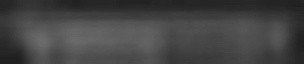

plate_01_enhanced_enhanced.jpg


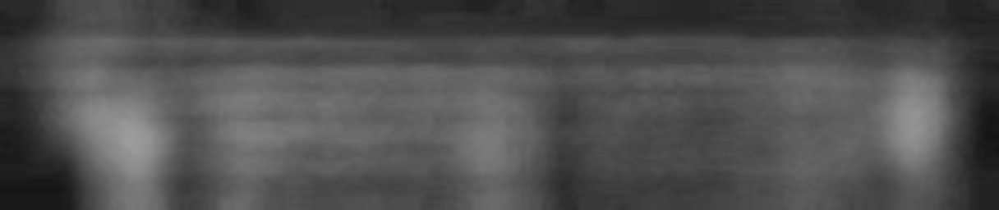

plate_01_enhanced_gray.jpg


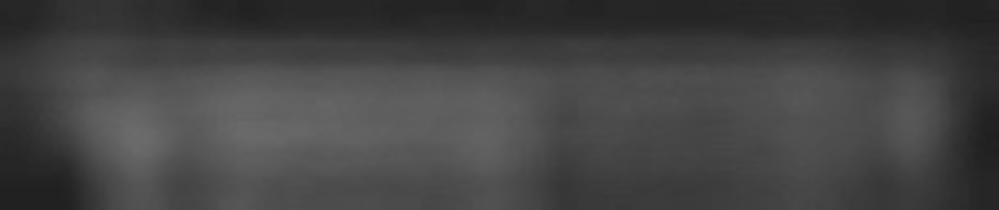

plate_01_enhanced_sharpened.jpg


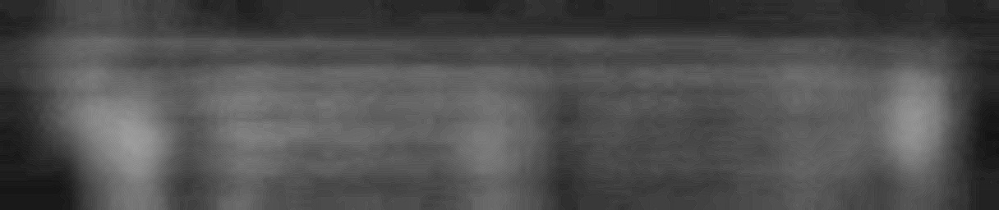

plate_01_enhanced_threshold.jpg


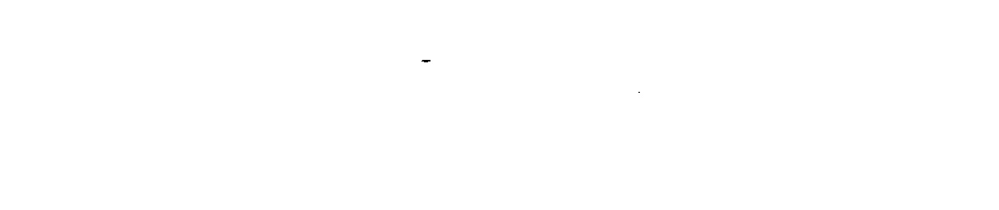

plate_01_gray.jpg


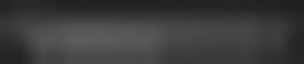

plate_01_gray_enhanced.jpg


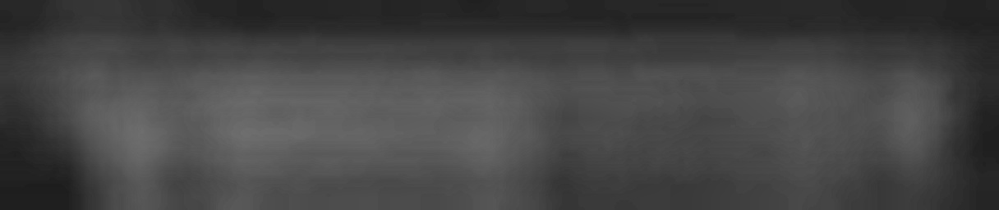

plate_01_gray_gray.jpg


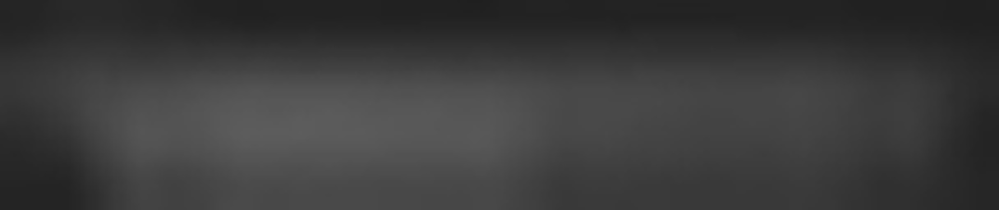

plate_01_gray_sharpened.jpg


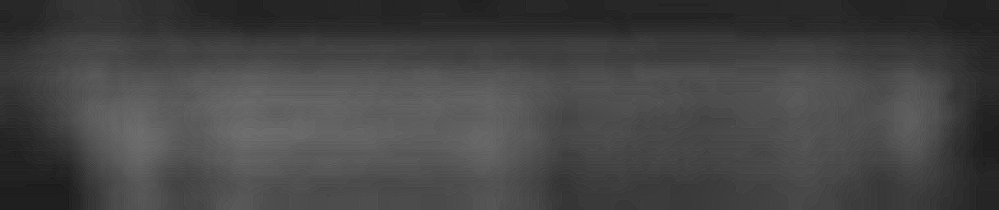

plate_01_gray_threshold.jpg


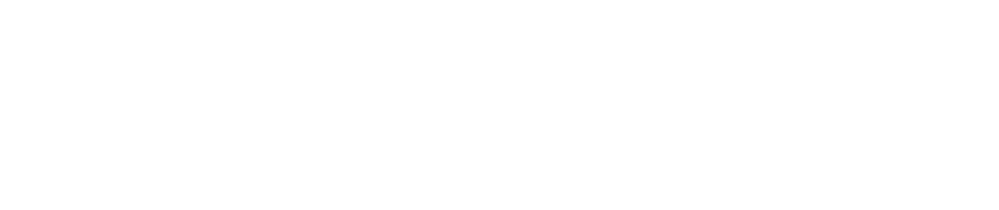

plate_01_sharpened.jpg


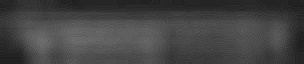

plate_01_sharpened_enhanced.jpg


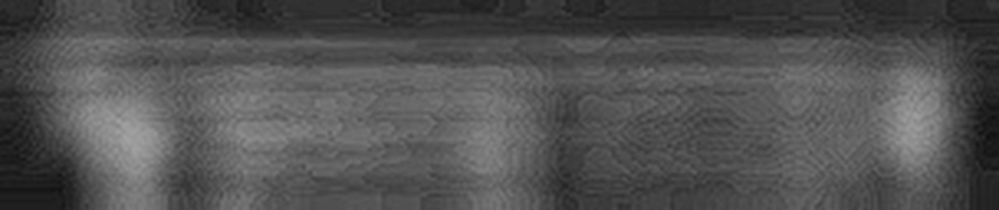

plate_01_sharpened_gray.jpg


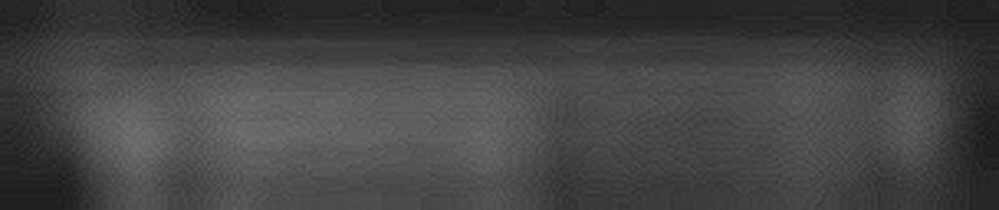

plate_01_sharpened_sharpened.jpg


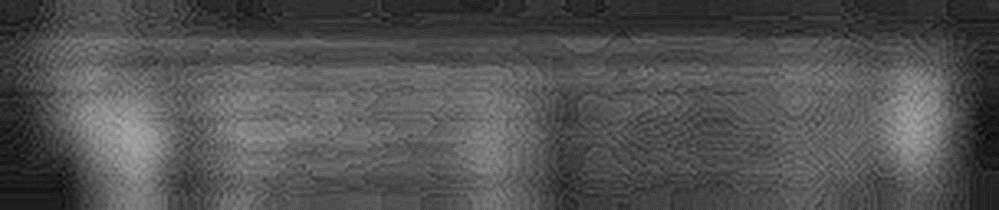

plate_01_sharpened_threshold.jpg


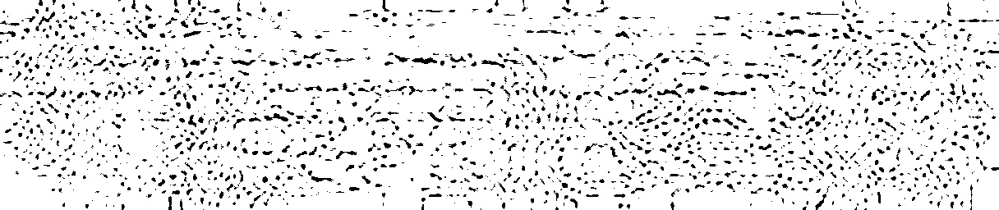

plate_01_threshold.jpg


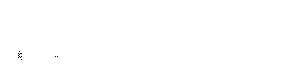

plate_01_threshold_enhanced.jpg


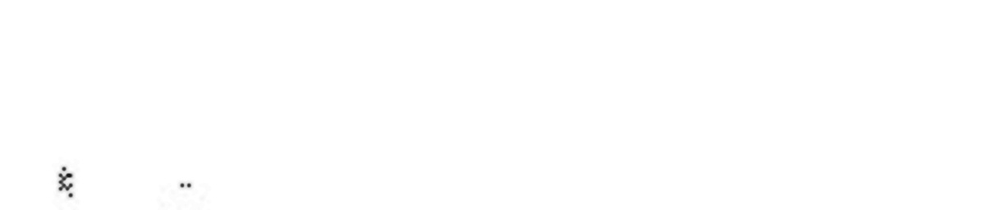

plate_01_threshold_gray.jpg


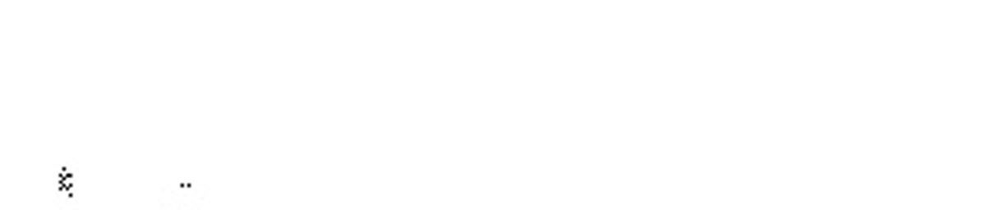

plate_01_threshold_sharpened.jpg


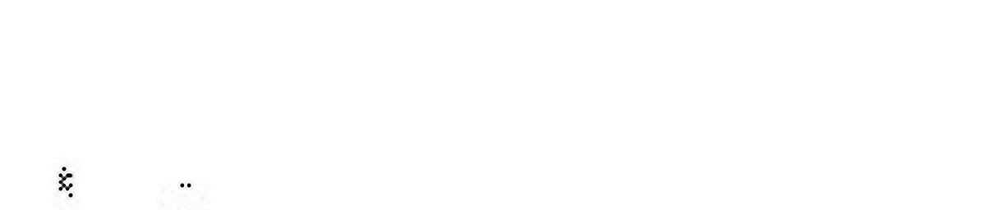

plate_01_threshold_threshold.jpg


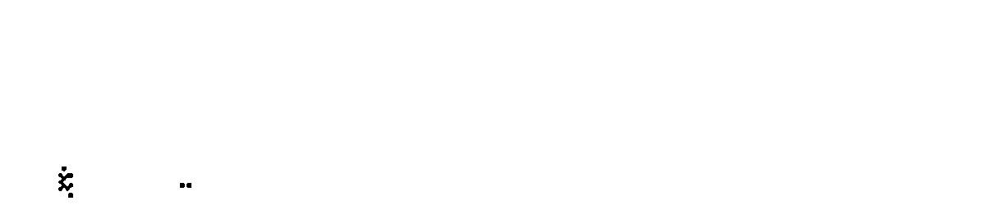

In [34]:
from IPython.display import display
from PIL import Image

display_files = sorted(
    OCR_DEBUG_DIR.glob(
        "plate_01*.jpg"
    )
)

for path in display_files:

    print(path.name)

    display(
        Image.open(path)
    )

In [35]:
from collections import defaultdict, Counter
import re
import time


# ============================================================
# SENTINEL TEMPORAL PLATE EVIDENCE ENGINE
# ============================================================

class TemporalPlateFusion:

    def __init__(
        self,
        min_observations=2,
        min_confidence=0.50,
        max_history=20
    ):

        self.min_observations = (
            min_observations
        )

        self.min_confidence = (
            min_confidence
        )

        self.max_history = max_history

        # track_id -> list of observations
        self.history = defaultdict(list)


    # --------------------------------------------------------
    # Normalize OCR text
    # --------------------------------------------------------

    @staticmethod
    def normalize_text(text):

        if text is None:
            return None

        text = str(text).upper()

        # Keep alphanumeric characters only
        text = re.sub(
            r"[^A-Z0-9]",
            "",
            text
        )

        if not text:
            return None

        return text


    # --------------------------------------------------------
    # Add OCR observation
    # --------------------------------------------------------

    def add_observation(
        self,
        track_id,
        text,
        confidence
    ):

        if track_id is None:
            return None

        if text is None:
            return None

        try:
            confidence = float(
                confidence
            )
        except Exception:
            return None

        if confidence < self.min_confidence:
            return None

        text = self.normalize_text(
            text
        )

        if text is None:
            return None

        observation = {
            "text": text,
            "confidence": confidence,
            "timestamp": time.time()
        }

        self.history[
            int(track_id)
        ].append(
            observation
        )

        # Limit history size
        self.history[
            int(track_id)
        ] = self.history[
            int(track_id)
        ][-self.max_history:]


        return self.get_reliable_plate(
            track_id
        )


    # --------------------------------------------------------
    # Determine reliable plate
    # --------------------------------------------------------

    def get_reliable_plate(
        self,
        track_id
    ):

        if track_id is None:
            return None

        observations = self.history.get(
            int(track_id),
            []
        )

        if not observations:
            return None

        # Count OCR text occurrences
        counts = Counter(
            obs["text"]
            for obs in observations
        )

        best_text, count = (
            counts.most_common(1)[0]
        )

        # Need repeated evidence
        if count < self.min_observations:
            return None

        matching = [
            obs
            for obs in observations
            if obs["text"] == best_text
        ]

        if not matching:
            return None

        confidence = sum(
            obs["confidence"]
            for obs in matching
        ) / len(matching)

        return {
            "text": best_text,
            "confidence": round(
                confidence,
                4
            )
        }


    # --------------------------------------------------------
    # Get current public result
    # --------------------------------------------------------

    def get_plate(
        self,
        track_id
    ):

        result = self.get_reliable_plate(
            track_id
        )

        if result is None:
            return None

        return result


    # --------------------------------------------------------
    # Remove disappeared tracks
    # --------------------------------------------------------

    def remove_track(
        self,
        track_id
    ):

        if track_id is None:
            return

        self.history.pop(
            int(track_id),
            None
        )


    # --------------------------------------------------------
    # Reset engine
    # --------------------------------------------------------

    def clear(self):

        self.history.clear()


plate_fusion = TemporalPlateFusion(
    min_observations=2,
    min_confidence=CONFIG.ocr_min_confidence,
    max_history=20
)


print("=" * 70)
print("SENTINEL TEMPORAL PLATE FUSION")
print("=" * 70)

print(
    "Minimum observations:",
    plate_fusion.min_observations
)

print(
    "Minimum OCR confidence:",
    plate_fusion.min_confidence
)

print(
    "Maximum history:",
    plate_fusion.max_history
)

print()
print("✅ Temporal plate evidence engine ready")
print("=" * 70)

SENTINEL TEMPORAL PLATE FUSION
Minimum observations: 2
Minimum OCR confidence: 0.5
Maximum history: 20

✅ Temporal plate evidence engine ready


In [36]:
print("=" * 70)
print("TEMPORAL PLATE FUSION TEST")
print("=" * 70)


test_fusion = TemporalPlateFusion(
    min_observations=2,
    min_confidence=0.50
)


# ------------------------------------------------------------
# Test 1: No OCR
# ------------------------------------------------------------

result = test_fusion.add_observation(
    track_id=101,
    text=None,
    confidence=None
)

print(
    "Test 1 - No OCR:",
    result
)

assert result is None


# ------------------------------------------------------------
# Test 2: One observation only
# ------------------------------------------------------------

result = test_fusion.add_observation(
    track_id=102,
    text="GJ01AB1234",
    confidence=0.91
)

print(
    "Test 2 - One observation:",
    result
)

assert result is None


# ------------------------------------------------------------
# Test 3: Two consistent observations
# ------------------------------------------------------------

test_fusion.add_observation(
    track_id=103,
    text="GJ01AB1234",
    confidence=0.90
)

result = test_fusion.add_observation(
    track_id=103,
    text="GJ01AB1234",
    confidence=0.92
)

print(
    "Test 3 - Repeated observation:",
    result
)

assert result is not None
assert result["text"] == "GJ01AB1234"


# ------------------------------------------------------------
# Test 4: Conflicting OCR
# ------------------------------------------------------------

test_fusion.add_observation(
    track_id=104,
    text="GJ01AB1234",
    confidence=0.91
)

result = test_fusion.add_observation(
    track_id=104,
    text="GJ01XB1234",
    confidence=0.92
)

print(
    "Test 4 - Conflicting observations:",
    result
)

assert result is None


print()
print("=" * 70)
print("✅ ALL TEMPORAL SAFETY TESTS PASSED")
print("=" * 70)

TEMPORAL PLATE FUSION TEST
Test 1 - No OCR: None
Test 2 - One observation: None
Test 3 - Repeated observation: {'text': 'GJ01AB1234', 'confidence': 0.91}
Test 4 - Conflicting observations: None

✅ ALL TEMPORAL SAFETY TESTS PASSED


In [37]:
import cv2
import re
import numpy as np


# ============================================================
# SENTINEL PLATE QUALITY + OCR PIPELINE
# ============================================================

MIN_PLATE_WIDTH = 100
MIN_PLATE_HEIGHT = 25

OCR_MIN_CONFIDENCE = CONFIG.ocr_min_confidence


def clean_ocr_text(text):
    """
    Normalize OCR output.
    """

    if text is None:
        return None

    text = str(text).upper()

    text = re.sub(
        r"[^A-Z0-9]",
        "",
        text
    )

    if not text:
        return None

    return text


def plate_quality_ok(crop):
    """
    Reject crops that are too small to provide
    meaningful OCR evidence.
    """

    if crop is None:
        return False

    if crop.size == 0:
        return False

    h, w = crop.shape[:2]

    if w < MIN_PLATE_WIDTH:
        return False

    if h < MIN_PLATE_HEIGHT:
        return False

    return True


def prepare_plate_for_ocr(crop):
    """
    Create a high-quality OCR input.
    """

    if not plate_quality_ok(crop):
        return None

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    # 4x enlargement
    enlarged = cv2.resize(
        gray,
        None,
        fx=4,
        fy=4,
        interpolation=cv2.INTER_CUBIC
    )

    # Contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(
        enlarged
    )

    # Mild denoise
    enhanced = cv2.bilateralFilter(
        enhanced,
        5,
        40,
        40
    )

    return enhanced


def run_plate_ocr(crop):
    """
    Run EasyOCR on one plate crop.

    Returns:
        {
            "text": "...",
            "confidence": ...
        }

    or None if no reliable OCR result exists.
    """

    prepared = prepare_plate_for_ocr(
        crop
    )

    if prepared is None:
        return None

    try:

        results = ocr_reader.readtext(
            prepared,
            detail=1,
            paragraph=False
        )

    except Exception as e:

        print(
            "⚠️ OCR error:",
            e
        )

        return None

    if not results:
        return None

    candidates = []

    for item in results:

        if len(item) < 3:
            continue

        text = item[1]
        confidence = float(
            item[2]
        )

        text = clean_ocr_text(
            text
        )

        if text is None:
            continue

        if confidence < OCR_MIN_CONFIDENCE:
            continue

        candidates.append(
            {
                "text": text,
                "confidence": confidence
            }
        )

    if not candidates:
        return None

    # Highest-confidence OCR candidate
    best = max(
        candidates,
        key=lambda x: x["confidence"]
    )

    return best


print("=" * 70)
print("SENTINEL PLATE QUALITY + OCR PIPELINE")
print("=" * 70)

print(
    "Minimum plate width :",
    MIN_PLATE_WIDTH
)

print(
    "Minimum plate height:",
    MIN_PLATE_HEIGHT
)

print(
    "OCR confidence      :",
    OCR_MIN_CONFIDENCE
)

print()
print("✅ Plate quality gate ready")
print("✅ OCR preprocessing ready")
print("✅ OCR result normalization ready")
print("✅ Null-safe OCR behavior ready")
print("=" * 70)

SENTINEL PLATE QUALITY + OCR PIPELINE
Minimum plate width : 100
Minimum plate height: 25
OCR confidence      : 0.5

✅ Plate quality gate ready
✅ OCR preprocessing ready
✅ OCR result normalization ready
✅ Null-safe OCR behavior ready


In [38]:
print("=" * 70)
print("PLATE QUALITY GATE TEST")
print("=" * 70)


# Too small
small_crop = np.zeros(
    (28, 76, 3),
    dtype=np.uint8
)

assert plate_quality_ok(
    small_crop
) is False

print(
    "76x28 crop → rejected ✅"
)


# Width sufficient
medium_crop = np.zeros(
    (40, 132, 3),
    dtype=np.uint8
)

assert plate_quality_ok(
    medium_crop
) is True

print(
    "132x40 crop → accepted for OCR attempt ✅"
)


# Completely empty
assert plate_quality_ok(
    None
) is False

print(
    "None crop → rejected ✅"
)


print()
print("=" * 70)
print("✅ PLATE QUALITY TEST PASSED")
print("=" * 70)

PLATE QUALITY GATE TEST
76x28 crop → rejected ✅
132x40 crop → accepted for OCR attempt ✅
None crop → rejected ✅

✅ PLATE QUALITY TEST PASSED


In [39]:
import cv2
import time
import json
import numpy as np
from datetime import datetime, timezone


# ============================================================
# SENTINEL END-TO-END VEHICLE + PLATE + OCR PIPELINE
# ============================================================

def get_box_center(box):
    x1, y1, x2, y2 = box

    return (
        (x1 + x2) / 2,
        (y1 + y2) / 2
    )


def point_inside_box(point, box):
    """
    Check whether a point lies inside a vehicle bbox.
    """

    px, py = point
    x1, y1, x2, y2 = box

    return (
        x1 <= px <= x2
        and
        y1 <= py <= y2
    )


def find_vehicle_for_plate(
    plate_box,
    vehicle_boxes
):
    """
    Associate a detected plate with the vehicle
    whose bbox contains the plate center.

    Returns:
        vehicle index
        or None
    """

    plate_center = get_box_center(
        plate_box
    )

    candidates = []

    for idx, vehicle in enumerate(
        vehicle_boxes
    ):

        if point_inside_box(
            plate_center,
            vehicle["box"]
        ):

            # Prefer smallest containing vehicle
            x1, y1, x2, y2 = vehicle["box"]

            area = (
                max(0, x2 - x1)
                *
                max(0, y2 - y1)
            )

            candidates.append(
                (
                    area,
                    idx
                )
            )

    if not candidates:
        return None

    candidates.sort()

    return candidates[0][1]


def crop_box(
    frame,
    box
):
    """
    Safely crop xyxy region from frame.
    """

    h, w = frame.shape[:2]

    x1, y1, x2, y2 = box

    x1 = max(
        0,
        min(int(x1), w - 1)
    )

    y1 = max(
        0,
        min(int(y1), h - 1)
    )

    x2 = max(
        x1 + 1,
        min(int(x2), w)
    )

    y2 = max(
        y1 + 1,
        min(int(y2), h)
    )

    return frame[
        y1:y2,
        x1:x2
    ]


def run_end_to_end_test(
    duration_sec=15,
    ai_fps=5.0,
    camera_id=None
):

    camera_id = (
        camera_id
        if camera_id is not None
        else CONFIG.camera_id
    )

    print("=" * 70)
    print("SENTINEL END-TO-END AI TEST")
    print("=" * 70)

    print(
        "Camera       :",
        camera_id
    )

    print(
        "Duration     :",
        duration_sec,
        "sec"
    )

    print(
        "Target AI FPS:",
        ai_fps
    )

    print()

    # --------------------------------------------------------
    # Stream
    # --------------------------------------------------------

    cap = cv2.VideoCapture(
        RTSP_URL,
        cv2.CAP_FFMPEG
    )

    if not cap.isOpened():

        print(
            "❌ RTSP stream failed"
        )

        return

    print(
        "✅ RTSP stream opened"
    )

    # --------------------------------------------------------
    # Reset temporal state
    # --------------------------------------------------------

    fusion = TemporalPlateFusion(
        min_observations=CONFIG.min_plate_observations,
        min_confidence=CONFIG.ocr_min_confidence,
        max_history=20
    )

    # --------------------------------------------------------
    # Runtime
    # --------------------------------------------------------

    start_time = time.perf_counter()

    next_ai_time = start_time

    frames_received = 0
    ai_frames = 0

    vehicle_count = 0
    plate_candidates = 0
    ocr_attempts = 0
    ocr_successes = 0
    reliable_plates = 0

    events = []

    while True:

        ok, frame = cap.read()

        if not ok or frame is None:
            break

        frames_received += 1

        now = time.perf_counter()

        if (
            now - start_time
            >= duration_sec
        ):
            break

        if now < next_ai_time:
            continue

        next_ai_time += (
            1.0 / ai_fps
        )

        ai_frames += 1

        # ====================================================
        # VEHICLE + TRACKING
        # ====================================================

        vehicle_results = (
            vehicle_model.track(
                frame,
                persist=True,
                tracker=CONFIG.tracker,
                imgsz=CONFIG.vehicle_imgsz,
                conf=CONFIG.vehicle_conf,
                iou=CONFIG.vehicle_iou,
                classes=list(
                    VEHICLE_CLASSES.keys()
                ),
                device=CONFIG.device,
                verbose=False
            )
        )

        vehicle_boxes = []

        if vehicle_results:

            result = vehicle_results[0]

            if result.boxes is not None:

                boxes = result.boxes

                xyxy = (
                    boxes.xyxy
                    .cpu()
                    .numpy()
                )

                confs = (
                    boxes.conf
                    .cpu()
                    .numpy()
                )

                classes = (
                    boxes.cls
                    .cpu()
                    .numpy()
                )

                if boxes.id is not None:

                    track_ids = (
                        boxes.id
                        .cpu()
                        .numpy()
                        .astype(int)
                    )

                else:

                    track_ids = [
                        None
                    ] * len(xyxy)

                for box, conf, cls, tid in zip(
                    xyxy,
                    confs,
                    classes,
                    track_ids
                ):

                    vehicle_boxes.append(
                        {
                            "box": box,
                            "confidence": float(conf),
                            "class_id": int(cls),
                            "track_id": tid
                        }
                    )

        vehicle_count += len(
            vehicle_boxes
        )

        # ====================================================
        # LICENSE PLATE DETECTOR
        # ====================================================

        plate_results = (
            plate_model.predict(
                frame,
                imgsz=CONFIG.plate_imgsz,
                conf=CONFIG.plate_conf,
                device=CONFIG.device,
                verbose=False
            )
        )

        event_detections = []

        # ----------------------------------------------------
        # Start vehicle detections
        # ----------------------------------------------------

        for vehicle in vehicle_boxes:

            box = vehicle["box"]

            track_id = vehicle["track_id"]

            # ------------------------------------------------
            # Look for associated plate
            # ------------------------------------------------

            plate_value = None

            plate_box_for_vehicle = None

            plate_conf_for_vehicle = None

            # =================================================
            # Process plate detector results
            # =================================================

            if plate_results:

                plate_result = (
                    plate_results[0]
                )

                if (
                    plate_result.boxes
                    is not None
                ):

                    pboxes = (
                        plate_result.boxes
                    )

                    pxyxy = (
                        pboxes.xyxy
                        .cpu()
                        .numpy()
                    )

                    pconfs = (
                        pboxes.conf
                        .cpu()
                        .numpy()
                    )

                    for pbox, pconf in zip(
                        pxyxy,
                        pconfs
                    ):

                        # Check association
                        matched_idx = (
                            find_vehicle_for_plate(
                                pbox,
                                vehicle_boxes
                            )
                        )

                        if (
                            matched_idx
                            is None
                        ):
                            continue

                        if (
                            matched_idx
                            != vehicle_boxes.index(
                                vehicle
                            )
                        ):
                            continue

                        plate_candidates += 1

                        plate_box_for_vehicle = pbox

                        plate_conf_for_vehicle = float(
                            pconf
                        )

                        # ------------------------------------------------
                        # Crop
                        # ------------------------------------------------

                        plate_crop = crop_box(
                            frame,
                            pbox
                        )

                        # ------------------------------------------------
                        # Quality gate
                        # ------------------------------------------------

                        if not plate_quality_ok(
                            plate_crop
                        ):
                            continue

                        ocr_attempts += 1

                        # ------------------------------------------------
                        # OCR
                        # ------------------------------------------------

                        ocr_result = run_plate_ocr(
                            plate_crop
                        )

                        if ocr_result is None:
                            continue

                        ocr_successes += 1

                        # ------------------------------------------------
                        # Temporal fusion
                        # ------------------------------------------------

                        fused = fusion.add_observation(
                            track_id=track_id,
                            text=ocr_result["text"],
                            confidence=ocr_result["confidence"]
                        )

                        if fused is not None:

                            plate_value = fused

                            reliable_plates += 1

                        break

            # =================================================
            # Build canonical detection
            # =================================================

            detection = make_detection(
                track_id=track_id,

                vehicle_confidence=(
                    vehicle["confidence"]
                ),

                bbox=make_bbox(
                    *vehicle["box"]
                ),

                vehicle_type=get_vehicle_type(
                    vehicle["class_id"]
                ),

                plate_text=(
                    plate_value["text"]
                    if plate_value
                    else None
                ),

                plate_confidence=(
                    plate_value["confidence"]
                    if plate_value
                    else None
                )
            )

            event_detections.append(
                detection
            )

        # ====================================================
        # EVENT
        # ====================================================

        event = make_detection_event(
            camera_id=camera_id,

            detections=event_detections,

            pts_ms=None,

            timestamp=(
                datetime.now(
                    timezone.utc
                ).isoformat()
            )
        )

        events.append(
            event
        )

    cap.release()

    runtime = (
        time.perf_counter()
        - start_time
    )

    actual_ai_fps = (
        ai_frames / runtime
        if runtime > 0
        else 0
    )

    # ========================================================
    # RESULTS
    # ========================================================

    print()
    print("=" * 70)
    print("END-TO-END RESULTS")
    print("=" * 70)

    print(
        "Frames received   :",
        frames_received
    )

    print(
        "AI frames         :",
        ai_frames
    )

    print(
        "Vehicle detections:",
        vehicle_count
    )

    print(
        "Plate candidates  :",
        plate_candidates
    )

    print(
        "OCR attempts      :",
        ocr_attempts
    )

    print(
        "OCR successes     :",
        ocr_successes
    )

    print(
        "Reliable plates   :",
        reliable_plates
    )

    print(
        "AI FPS            :",
        round(
            actual_ai_fps,
            2
        )
    )

    print()

    # ========================================================
    # Find first event containing a vehicle
    # ========================================================

    example_event = None

    for event in events:

        if event["detections"]:

            example_event = event

            break

    if example_event is not None:

        print("=" * 70)
        print("EXAMPLE LIVE EVENT")
        print("=" * 70)

        print(
            json.dumps(
                example_event,
                indent=2,
                ensure_ascii=False
            )
        )

    print()
    print("=" * 70)
    print("✅ END-TO-END PIPELINE COMPLETE")
    print("=" * 70)

    return events

In [40]:
import cv2
import time
import json
import numpy as np
from datetime import datetime, timezone


# ============================================================
# SENTINEL END-TO-END AI TEST — FIXED
# ============================================================

def get_box_center(box):
    x1, y1, x2, y2 = box

    return (
        (x1 + x2) / 2.0,
        (y1 + y2) / 2.0
    )


def point_inside_box(point, box):
    px, py = point
    x1, y1, x2, y2 = box

    return (
        x1 <= px <= x2
        and
        y1 <= py <= y2
    )


def find_vehicle_for_plate(
    plate_box,
    vehicle_boxes
):
    """
    Associate a plate with the vehicle whose
    bounding box contains the plate center.

    Returns vehicle INDEX or None.
    """

    plate_center = get_box_center(
        plate_box
    )

    candidates = []

    for idx, vehicle in enumerate(
        vehicle_boxes
    ):

        if point_inside_box(
            plate_center,
            vehicle["box"]
        ):

            x1, y1, x2, y2 = vehicle["box"]

            area = (
                max(0, x2 - x1)
                *
                max(0, y2 - y1)
            )

            candidates.append(
                (
                    area,
                    idx
                )
            )

    if not candidates:
        return None

    candidates.sort(
        key=lambda x: x[0]
    )

    return candidates[0][1]


def crop_box(
    frame,
    box
):
    """
    Safely crop an xyxy region.
    """

    h, w = frame.shape[:2]

    x1, y1, x2, y2 = box

    x1 = max(
        0,
        min(int(x1), w - 1)
    )

    y1 = max(
        0,
        min(int(y1), h - 1)
    )

    x2 = max(
        x1 + 1,
        min(int(x2), w)
    )

    y2 = max(
        y1 + 1,
        min(int(y2), h)
    )

    return frame[
        y1:y2,
        x1:x2
    ]


def run_end_to_end_test(
    duration_sec=15,
    ai_fps=5.0,
    camera_id=None
):

    camera_id = (
        camera_id
        if camera_id is not None
        else CONFIG.camera_id
    )

    print("=" * 70)
    print("SENTINEL END-TO-END AI TEST")
    print("=" * 70)

    print(
        "Camera       :",
        camera_id
    )

    print(
        "Duration     :",
        duration_sec,
        "sec"
    )

    print(
        "Target AI FPS:",
        ai_fps
    )

    print()

    # ========================================================
    # RTSP
    # ========================================================

    cap = cv2.VideoCapture(
        RTSP_URL,
        cv2.CAP_FFMPEG
    )

    if not cap.isOpened():

        print(
            "❌ RTSP stream failed"
        )

        return None

    print(
        "✅ RTSP stream opened"
    )

    # ========================================================
    # TEMPORAL FUSION
    # ========================================================

    fusion = TemporalPlateFusion(
        min_observations=(
            CONFIG.min_plate_observations
        ),
        min_confidence=(
            CONFIG.ocr_min_confidence
        ),
        max_history=20
    )

    # ========================================================
    # RUNTIME
    # ========================================================

    start_time = time.perf_counter()

    next_ai_time = start_time

    frames_received = 0
    ai_frames = 0

    vehicle_count = 0
    plate_candidates = 0
    ocr_attempts = 0
    ocr_successes = 0
    reliable_plates = 0

    events = []

    # ========================================================
    # MAIN LOOP
    # ========================================================

    while True:

        ok, frame = cap.read()

        if not ok or frame is None:
            print(
                "⚠️ Frame read failed"
            )
            break

        frames_received += 1

        now = time.perf_counter()

        elapsed = (
            now - start_time
        )

        if elapsed >= duration_sec:
            break

        # ----------------------------------------------------
        # AI scheduler
        # ----------------------------------------------------

        if now < next_ai_time:
            continue

        next_ai_time += (
            1.0 / ai_fps
        )

        ai_frames += 1

        # ====================================================
        # VEHICLE DETECTION + TRACKING
        # ====================================================

        vehicle_results = (
            vehicle_model.track(
                frame,
                persist=True,
                tracker=CONFIG.tracker,
                imgsz=CONFIG.vehicle_imgsz,
                conf=CONFIG.vehicle_conf,
                iou=CONFIG.vehicle_iou,
                classes=list(
                    VEHICLE_CLASSES.keys()
                ),
                device=CONFIG.device,
                verbose=False
            )
        )

        vehicle_boxes = []

        if vehicle_results:

            result = vehicle_results[0]

            if result.boxes is not None:

                boxes = result.boxes

                xyxy = (
                    boxes.xyxy
                    .cpu()
                    .numpy()
                )

                confs = (
                    boxes.conf
                    .cpu()
                    .numpy()
                )

                classes = (
                    boxes.cls
                    .cpu()
                    .numpy()
                )

                if boxes.id is not None:

                    track_ids = (
                        boxes.id
                        .cpu()
                        .numpy()
                        .astype(int)
                    )

                else:

                    track_ids = (
                        [None] * len(xyxy)
                    )

                for box, conf, cls, tid in zip(
                    xyxy,
                    confs,
                    classes,
                    track_ids
                ):

                    vehicle_boxes.append(
                        {
                            "box": box,
                            "confidence": float(
                                conf
                            ),
                            "class_id": int(
                                cls
                            ),
                            "track_id": (
                                int(tid)
                                if tid is not None
                                else None
                            )
                        }
                    )

        vehicle_count += len(
            vehicle_boxes
        )

        # ====================================================
        # PLATE DETECTION
        # ====================================================

        plate_results = (
            plate_model.predict(
                frame,
                imgsz=CONFIG.plate_imgsz,
                conf=CONFIG.plate_conf,
                device=CONFIG.device,
                verbose=False
            )
        )

        # ----------------------------------------------------
        # Pre-extract plate candidates
        # ----------------------------------------------------

        detected_plates = []

        if plate_results:

            plate_result = (
                plate_results[0]
            )

            if plate_result.boxes is not None:

                pboxes = (
                    plate_result.boxes
                )

                pxyxy = (
                    pboxes.xyxy
                    .cpu()
                    .numpy()
                )

                pconfs = (
                    pboxes.conf
                    .cpu()
                    .numpy()
                )

                for pbox, pconf in zip(
                    pxyxy,
                    pconfs
                ):

                    detected_plates.append(
                        {
                            "box": pbox,
                            "confidence": float(
                                pconf
                            )
                        }
                    )

        plate_candidates += len(
            detected_plates
        )

        # ====================================================
        # BUILD VEHICLE EVENTS
        # ====================================================

        event_detections = []

        # IMPORTANT:
        # enumerate gives us vehicle_idx directly.
        # This fixes the NumPy .index() error.
        # ====================================================

        for vehicle_idx, vehicle in enumerate(
            vehicle_boxes
        ):

            box = vehicle["box"]

            track_id = vehicle[
                "track_id"
            ]

            plate_value = None

            # ------------------------------------------------
            # Find plate belonging to THIS vehicle
            # ------------------------------------------------

            for plate in detected_plates:

                matched_idx = (
                    find_vehicle_for_plate(
                        plate["box"],
                        vehicle_boxes
                    )
                )

                if matched_idx != vehicle_idx:
                    continue

                # ------------------------------------------------
                # Crop plate
                # ------------------------------------------------

                plate_crop = crop_box(
                    frame,
                    plate["box"]
                )

                # ------------------------------------------------
                # Quality gate
                # ------------------------------------------------

                if not plate_quality_ok(
                    plate_crop
                ):
                    continue

                ocr_attempts += 1

                # ------------------------------------------------
                # OCR
                # ------------------------------------------------

                ocr_result = run_plate_ocr(
                    plate_crop
                )

                if ocr_result is None:
                    continue

                ocr_successes += 1

                # ------------------------------------------------
                # Temporal fusion
                # ------------------------------------------------

                fused = (
                    fusion.add_observation(
                        track_id=track_id,
                        text=ocr_result["text"],
                        confidence=ocr_result[
                            "confidence"
                        ]
                    )
                )

                if fused is not None:

                    plate_value = fused

                # One associated plate is enough
                break

            # ------------------------------------------------
            # Canonical Sentinel detection
            # ------------------------------------------------

            detection = make_detection(
                track_id=track_id,

                vehicle_confidence=(
                    vehicle["confidence"]
                ),

                bbox=make_bbox(
                    *box
                ),

                vehicle_type=get_vehicle_type(
                    vehicle["class_id"]
                ),

                plate_text=(
                    plate_value["text"]
                    if plate_value is not None
                    else None
                ),

                plate_confidence=(
                    plate_value["confidence"]
                    if plate_value is not None
                    else None
                )
            )

            event_detections.append(
                detection
            )

            if plate_value is not None:
                reliable_plates += 1

        # ====================================================
        # EVENT TIMESTAMP
        # ====================================================

        event = make_detection_event(
            camera_id=camera_id,

            detections=event_detections,

            # Real RTSP PTS is still not exposed
            # by this OpenCV path.
            pts_ms=None,

            timestamp=(
                datetime.now(
                    timezone.utc
                ).isoformat()
            )
        )

        events.append(
            event
        )

    # ========================================================
    # CLEANUP
    # ========================================================

    cap.release()

    runtime = (
        time.perf_counter()
        - start_time
    )

    actual_ai_fps = (
        ai_frames / runtime
        if runtime > 0
        else 0
    )

    # ========================================================
    # RESULTS
    # ========================================================

    print()
    print("=" * 70)
    print("END-TO-END RESULTS")
    print("=" * 70)

    print(
        "Frames received   :",
        frames_received
    )

    print(
        "AI frames         :",
        ai_frames
    )

    print(
        "Vehicle detections:",
        vehicle_count
    )

    print(
        "Plate candidates  :",
        plate_candidates
    )

    print(
        "OCR attempts      :",
        ocr_attempts
    )

    print(
        "OCR successes     :",
        ocr_successes
    )

    print(
        "Reliable plates   :",
        reliable_plates
    )

    print(
        "AI FPS            :",
        round(
            actual_ai_fps,
            2
        )
    )

    # ========================================================
    # EXAMPLE EVENT
    # ========================================================

    example_event = None

    for event in events:

        if event["detections"]:

            example_event = event

            break

    if example_event is not None:

        print()
        print("=" * 70)
        print("EXAMPLE LIVE EVENT")
        print("=" * 70)

        print(
            json.dumps(
                example_event,
                indent=2,
                ensure_ascii=False
            )
        )

    print()
    print("=" * 70)
    print("✅ END-TO-END PIPELINE COMPLETE")
    print("=" * 70)

    return events

In [41]:
events = run_end_to_end_test(
    duration_sec=15,
    ai_fps=5.0,
    camera_id=CONFIG.camera_id
)

SENTINEL END-TO-END AI TEST
Camera       : cam01
Duration     : 15 sec
Target AI FPS: 5.0

✅ RTSP stream opened

END-TO-END RESULTS
Frames received   : 176
AI frames         : 75
Vehicle detections: 239
Plate candidates  : 7
OCR attempts      : 0
OCR successes     : 0
Reliable plates   : 0
AI FPS            : 4.96

EXAMPLE LIVE EVENT
{
  "schemaVersion": "1.0",
  "eventId": "evt_151ea31c33f9",
  "eventType": "detection",
  "camera": {
    "cameraId": "cam01",
    "timestamp": "2026-09-04T14:34:42.379353+00:00",
    "ptsMs": null
  },
  "detections": [
    {
      "trackId": null,
      "type": "vehicle",
      "confidence": 0.6481,
      "bbox": {
        "x": 1050,
        "y": 601,
        "width": 62,
        "height": 53
      },
      "vehicle": {
        "type": "car"
      },
      "plate": null
    }
  ]
}

✅ END-TO-END PIPELINE COMPLETE


In [42]:
from typing import Optional, List
from pydantic import BaseModel, Field


# ============================================================
# SENTINEL AI MODEL API — DATA CONTRACT
# ============================================================

class BBoxModel(BaseModel):

    x: int
    y: int
    width: int
    height: int


class PlateModel(BaseModel):

    text: str
    confidence: float = Field(
        ge=0.0,
        le=1.0
    )


class VehicleModel(BaseModel):

    type: str


class DetectionModel(BaseModel):

    trackId: Optional[str] = None

    type: str = "vehicle"

    confidence: float = Field(
        ge=0.0,
        le=1.0
    )

    bbox: BBoxModel

    vehicle: VehicleModel

    # IMPORTANT:
    # No plate → null
    plate: Optional[PlateModel] = None


class CameraModel(BaseModel):

    cameraId: str

    timestamp: str

    ptsMs: Optional[int] = None


class DetectionEventModel(BaseModel):

    schemaVersion: str = "1.0"

    eventId: str

    eventType: str = "detection"

    camera: CameraModel

    detections: List[DetectionModel]


print("=" * 70)
print("SENTINEL AI MODEL API DATA CONTRACT")
print("=" * 70)

print("✅ BBoxModel")
print("✅ PlateModel")
print("✅ VehicleModel")
print("✅ DetectionModel")
print("✅ CameraModel")
print("✅ DetectionEventModel")
print()
print("Critical rule:")
print("unreliable/missing plate → null")
print()
print("✅ API schema models ready")
print("=" * 70)

SENTINEL AI MODEL API DATA CONTRACT
✅ BBoxModel
✅ PlateModel
✅ VehicleModel
✅ DetectionModel
✅ CameraModel
✅ DetectionEventModel

Critical rule:
unreliable/missing plate → null

✅ API schema models ready


In [43]:
print("=" * 70)
print("SENTINEL API CONTRACT VALIDATION")
print("=" * 70)


# Take an actual event generated by the live pipeline
sample_event = None

for event in events:

    if event["detections"]:

        sample_event = event

        break


if sample_event is None:

    print(
        "❌ No vehicle event available"
    )

else:

    # Validate through Pydantic
    validated = DetectionEventModel.model_validate(
        sample_event
    )

    print(
        "Camera:",
        validated.camera.cameraId
    )

    print(
        "Event:",
        validated.eventId
    )

    print(
        "Detections:",
        len(validated.detections)
    )

    print()

    for idx, detection in enumerate(
        validated.detections,
        start=1
    ):

        print(
            f"Detection {idx}:"
        )

        print(
            "  Track:",
            detection.trackId
        )

        print(
            "  Type:",
            detection.vehicle.type
        )

        print(
            "  Confidence:",
            detection.confidence
        )

        print(
            "  Plate:",
            detection.plate
        )

    print()
    print(
        "✅ Event successfully validated"
    )


print("=" * 70)

SENTINEL API CONTRACT VALIDATION
Camera: cam01
Event: evt_151ea31c33f9
Detections: 1

Detection 1:
  Track: None
  Type: car
  Confidence: 0.6481
  Plate: None

✅ Event successfully validated


In [44]:
# ============================================================
# CELL 33 — SENTINEL AI MODEL API
# ============================================================

from fastapi import FastAPI
from pydantic import BaseModel
from typing import Optional, List
import threading
import uvicorn

app = FastAPI(
    title="Sentinel AI Model API",
    version="1.0.0",
    description="Independent AI detection service for Sentinel CCTV"
)


# -----------------------------
# API MODELS
# -----------------------------

class BBoxModel(BaseModel):
    x: int
    y: int
    width: int
    height: int


class PlateModel(BaseModel):
    text: str
    confidence: float


class VehicleModel(BaseModel):
    type: str


class DetectionModel(BaseModel):
    trackId: Optional[str] = None
    type: str = "vehicle"
    confidence: float
    bbox: BBoxModel
    vehicle: VehicleModel
    plate: Optional[PlateModel] = None


class CameraModel(BaseModel):
    cameraId: str
    timestamp: str
    ptsMs: Optional[int] = None


class DetectionEventModel(BaseModel):
    schemaVersion: str = "1.0"
    eventId: str
    eventType: str = "detection"
    camera: CameraModel
    detections: List[DetectionModel]


# -----------------------------
# HEALTH ENDPOINT
# -----------------------------

@app.get("/health")
def health():
    return {
        "status": "healthy",
        "service": "sentinel-ai-model-api",
        "version": "1.0.0",
        "vehicle_model": CONFIG.vehicle_model,
        "plate_model": "license-plate-finetune-v1n.pt",
        "ocr": "EasyOCR",
        "device": str(CONFIG.device),
        "camera": CONFIG.camera_id
    }


# -----------------------------
# MODEL INFORMATION
# -----------------------------

@app.get("/model")
def model_info():
    return {
        "service": "sentinel-ai-model-api",
        "schemaVersion": SCHEMA_VERSION,
        "vehicle_detection": True,
        "vehicle_tracking": True,
        "plate_detection": True,
        "plate_ocr": True,
        "temporal_plate_fusion": True,
        "device": str(CONFIG.device)
    }


# -----------------------------
# DETECTION VALIDATION ENDPOINT
# -----------------------------

@app.post("/v1/detections")
def receive_detection(event: DetectionEventModel):

    return {
        "status": "accepted",
        "eventId": event.eventId,
        "cameraId": event.camera.cameraId,
        "detections": len(event.detections),
        "schemaVersion": event.schemaVersion
    }


# -----------------------------
# START SERVER
# -----------------------------

def start_api():
    uvicorn.run(
        app,
        host=CONFIG.api_host,
        port=CONFIG.api_port,
        log_level="warning"
    )


api_thread = threading.Thread(
    target=start_api,
    daemon=True
)

api_thread.start()

time.sleep(2)

print("=" * 70)
print("SENTINEL AI MODEL API")
print("=" * 70)
print(f"Host       : {CONFIG.api_host}")
print(f"Port       : {CONFIG.api_port}")
print("Status     : API server started")
print()
print("Endpoints:")
print("  GET  /health")
print("  GET  /model")
print("  POST /v1/detections")
print("=" * 70)

SENTINEL AI MODEL API
Host       : 0.0.0.0
Port       : 8000
Status     : API server started

Endpoints:
  GET  /health
  GET  /model
  POST /v1/detections


In [45]:
# ============================================================
# CELL 34 — SENTINEL AI MODEL API INTEGRATION TEST
# ============================================================

import requests
import json
import time

API_BASE_URL = f"http://127.0.0.1:{CONFIG.api_port}"

print("=" * 70)
print("SENTINEL AI MODEL API INTEGRATION TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. HEALTH CHECK
# ------------------------------------------------------------

health_response = requests.get(
    f"{API_BASE_URL}/health",
    timeout=5
)

print("\nHEALTH CHECK")
print("Status code :", health_response.status_code)
print(json.dumps(health_response.json(), indent=2))

assert health_response.status_code == 200
assert health_response.json()["status"] == "healthy"

print("✅ Health endpoint passed")


# ------------------------------------------------------------
# 2. MODEL INFORMATION
# ------------------------------------------------------------

model_response = requests.get(
    f"{API_BASE_URL}/model",
    timeout=5
)

print("\nMODEL INFORMATION")
print("Status code :", model_response.status_code)
print(json.dumps(model_response.json(), indent=2))

assert model_response.status_code == 200

print("✅ Model endpoint passed")


# ------------------------------------------------------------
# 3. SEND REAL VALIDATED EVENT
# ------------------------------------------------------------

if sample_event is None:
    raise RuntimeError("No validated sample_event available.")

payload = DetectionEventModel.model_validate(
    sample_event
).model_dump(mode="json")

print("\nSENDING DETECTION EVENT")
print("Event ID    :", payload["eventId"])
print("Camera      :", payload["camera"]["cameraId"])
print("Detections  :", len(payload["detections"]))

detection_response = requests.post(
    f"{API_BASE_URL}/v1/detections",
    json=payload,
    timeout=5
)

print("\nAPI RESPONSE")
print("Status code :", detection_response.status_code)
print(json.dumps(detection_response.json(), indent=2))

assert detection_response.status_code == 200

api_result = detection_response.json()

assert api_result["status"] == "accepted"
assert api_result["eventId"] == payload["eventId"]
assert api_result["cameraId"] == payload["camera"]["cameraId"]
assert api_result["detections"] == len(payload["detections"])

print("\n" + "=" * 70)
print("✅ SENTINEL API INTEGRATION TEST PASSED")
print("=" * 70)

SENTINEL AI MODEL API INTEGRATION TEST

HEALTH CHECK
Status code : 200
{
  "status": "healthy",
  "service": "sentinel-ai-model-api",
  "version": "1.0.0",
  "vehicle_model": "yolo11n.pt",
  "plate_model": "license-plate-finetune-v1n.pt",
  "ocr": "EasyOCR",
  "device": "0",
  "camera": "cam01"
}
✅ Health endpoint passed

MODEL INFORMATION
Status code : 200
{
  "service": "sentinel-ai-model-api",
  "schemaVersion": "1.0",
  "vehicle_detection": true,
  "vehicle_tracking": true,
  "plate_detection": true,
  "plate_ocr": true,
  "temporal_plate_fusion": true,
  "device": "0"
}
✅ Model endpoint passed

SENDING DETECTION EVENT
Event ID    : evt_151ea31c33f9
Camera      : cam01
Detections  : 1

API RESPONSE
Status code : 200
{
  "status": "accepted",
  "eventId": "evt_151ea31c33f9",
  "cameraId": "cam01",
  "detections": 1,
  "schemaVersion": "1.0"
}

✅ SENTINEL API INTEGRATION TEST PASSED


In [46]:
# ============================================================
# CELL 35 — SENTINEL WATCHLIST + ALERT ENGINE
# ============================================================

from datetime import datetime, timezone
from collections import defaultdict
import uuid
import json


# ------------------------------------------------------------
# WATCHLIST
# ------------------------------------------------------------

WATCHLIST = {
    "GJ01AB1234": {
        "watchlistId": "WL-001",
        "status": "ACTIVE",
        "priority": "HIGH",
        "reason": "Designated test vehicle"
    },
    "GJ05CD5678": {
        "watchlistId": "WL-002",
        "status": "ACTIVE",
        "priority": "MEDIUM",
        "reason": "Designated test vehicle"
    }
}


# ------------------------------------------------------------
# ALERT STORAGE
# ------------------------------------------------------------

ALERT_HISTORY = []


# ------------------------------------------------------------
# NORMALIZE PLATE
# ------------------------------------------------------------

def normalize_plate(plate):
    if plate is None:
        return None

    plate = str(plate).upper()
    plate = re.sub(r"[^A-Z0-9]", "", plate)

    return plate if plate else None


# ------------------------------------------------------------
# WATCHLIST LOOKUP
# ------------------------------------------------------------

def check_watchlist(plate_text):

    plate = normalize_plate(plate_text)

    if plate is None:
        return None

    entry = WATCHLIST.get(plate)

    if entry is None:
        return None

    if entry.get("status") != "ACTIVE":
        return None

    return {
        "plate": plate,
        **entry
    }


# ------------------------------------------------------------
# CREATE ALERT
# ------------------------------------------------------------

def create_watchlist_alert(
    camera_id,
    plate_text,
    plate_confidence,
    track_id=None,
    timestamp=None,
    source="LIVE"
):

    match = check_watchlist(plate_text)

    if match is None:
        return None

    alert = {
        "alertId": "alert_" + uuid.uuid4().hex[:12],
        "alertType": "WATCHLIST_MATCH",
        "source": source,
        "severity": match["priority"],
        "timestamp": timestamp or datetime.now(
            timezone.utc
        ).isoformat(),

        "camera": {
            "cameraId": camera_id
        },

        "vehicle": {
            "trackId": track_id,
            "plate": {
                "text": match["plate"],
                "confidence": round(
                    float(plate_confidence), 4
                )
            }
        },

        "watchlist": {
            "watchlistId": match["watchlistId"],
            "reason": match["reason"]
        }
    }

    ALERT_HISTORY.append(alert)

    return alert


# ------------------------------------------------------------
# TEST 1 — NON MATCH
# ------------------------------------------------------------

non_match = check_watchlist("GJ99ZZ9999")

assert non_match is None

print("✅ Non-watchlist plate correctly ignored")


# ------------------------------------------------------------
# TEST 2 — WATCHLIST MATCH
# ------------------------------------------------------------

test_alert = create_watchlist_alert(
    camera_id="cam01",
    plate_text="GJ01AB1234",
    plate_confidence=0.94,
    track_id="track_TEST001",
    source="TEST"
)

assert test_alert is not None
assert test_alert["alertType"] == "WATCHLIST_MATCH"
assert test_alert["source"] == "TEST"

print("✅ Watchlist match generated")


# ------------------------------------------------------------
# DISPLAY ALERT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SENTINEL WATCHLIST ALERT")
print("=" * 70)

print(json.dumps(
    test_alert,
    indent=2,
    ensure_ascii=False
))

print("\n" + "=" * 70)
print("✅ WATCHLIST + ALERT ENGINE TEST PASSED")
print("=" * 70)


✅ Non-watchlist plate correctly ignored
✅ Watchlist match generated

SENTINEL WATCHLIST ALERT
{
  "alertId": "alert_d36b3744988f",
  "alertType": "WATCHLIST_MATCH",
  "source": "TEST",
  "severity": "HIGH",
  "timestamp": "2026-09-04T14:36:22.883258+00:00",
  "camera": {
    "cameraId": "cam01"
  },
  "vehicle": {
    "trackId": "track_TEST001",
    "plate": {
      "text": "GJ01AB1234",
      "confidence": 0.94
    }
  },
  "watchlist": {
    "watchlistId": "WL-001",
    "reason": "Designated test vehicle"
  }
}

✅ WATCHLIST + ALERT ENGINE TEST PASSED


In [47]:
# ============================================================
# CELL 36A — FRESH ALERT API
# ============================================================

from fastapi import FastAPI
import threading
import time
import requests
import json

ALERT_API_PORT = 8001

alert_app = FastAPI(
    title="Sentinel AI Model API",
    version="1.1.0",
    description="Sentinel AI detection + watchlist alert service"
)


# ------------------------------------------------------------
# HEALTH
# ------------------------------------------------------------

@alert_app.get("/health")
def alert_health():

    return {
        "status": "healthy",
        "service": "sentinel-ai-model-api",
        "version": "1.1.0",
        "watchlist": True,
        "alerts": True,
        "camera": CONFIG.camera_id
    }


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

@alert_app.get("/model")
def alert_model():

    return {
        "service": "sentinel-ai-model-api",
        "schemaVersion": SCHEMA_VERSION,
        "vehicle_detection": True,
        "vehicle_tracking": True,
        "plate_detection": True,
        "plate_ocr": True,
        "temporal_plate_fusion": True,
        "watchlist_correlation": True,
        "real_time_alerts": True,
        "device": str(CONFIG.device)
    }


# ------------------------------------------------------------
# DETECTION → WATCHLIST → ALERT
# ------------------------------------------------------------

@alert_app.post("/v1/detections")
def receive_detection(event: DetectionEventModel):

    event_dict = event.model_dump(mode="json")

    alerts = process_detection_event(event_dict)

    return {
        "status": "accepted",
        "eventId": event.eventId,
        "cameraId": event.camera.cameraId,
        "detections": len(event.detections),
        "alertsGenerated": len(alerts),
        "alerts": alerts,
        "schemaVersion": event.schemaVersion
    }


# ------------------------------------------------------------
# START FRESH SERVER
# ------------------------------------------------------------

def start_alert_api():

    uvicorn.run(
        alert_app,
        host="0.0.0.0",
        port=ALERT_API_PORT,
        log_level="warning"
    )


alert_api_thread = threading.Thread(
    target=start_alert_api,
    daemon=True
)

alert_api_thread.start()

time.sleep(2)

ALERT_API_BASE_URL = f"http://127.0.0.1:{ALERT_API_PORT}"

print("=" * 70)
print("SENTINEL ALERT API")
print("=" * 70)

print(f"Host : 0.0.0.0")
print(f"Port : {ALERT_API_PORT}")
print(f"URL  : http://127.0.0.1:{ALERT_API_PORT}")

print()
print("Endpoints:")
print("  GET  /health")
print("  GET  /model")
print("  POST /v1/detections")

print("=" * 70)
print("✅ Fresh alert-enabled API started")

SENTINEL ALERT API
Host : 0.0.0.0
Port : 8001
URL  : http://127.0.0.1:8001

Endpoints:
  GET  /health
  GET  /model
  POST /v1/detections
✅ Fresh alert-enabled API started


In [48]:
# ============================================================
# CELL 36B-FIX — WATCHLIST EVENT PROCESSOR
# ============================================================

import re
import uuid
from datetime import datetime, timezone

# ------------------------------------------------------------
# Watchlist
# ------------------------------------------------------------

WATCHLIST = {
    "GJ01AB1234": {
        "watchlistId": "WL-001",
        "status": "ACTIVE",
        "priority": "HIGH",
        "reason": "Designated test vehicle"
    },

    "GJ05CD5678": {
        "watchlistId": "WL-002",
        "status": "ACTIVE",
        "priority": "MEDIUM",
        "reason": "Test watchlist vehicle"
    }
}


# ------------------------------------------------------------
# Alert history
# ------------------------------------------------------------

ALERT_HISTORY = []


# ------------------------------------------------------------
# Plate normalization
# ------------------------------------------------------------

def normalize_plate(text):

    if text is None:
        return None

    text = str(text).upper()

    # Remove spaces, hyphens and other separators
    text = re.sub(r"[^A-Z0-9]", "", text)

    return text if text else None


# ------------------------------------------------------------
# Create watchlist alert
# ------------------------------------------------------------

def create_watchlist_alert(
    event,
    detection,
    watchlist_entry
):

    alert = {

        "alertId": (
            "alert_"
            + uuid.uuid4().hex[:12]
        ),

        "alertType": "WATCHLIST_MATCH",

        "source": "AI_API",

        "severity": watchlist_entry.get(
            "priority",
            "MEDIUM"
        ),

        "timestamp": datetime.now(
            timezone.utc
        ).isoformat(),

        "watchlist": {

            "watchlistId":
                watchlist_entry["watchlistId"],

            "status":
                watchlist_entry["status"],

            "reason":
                watchlist_entry["reason"]
        },

        "camera": event["camera"],

        "vehicle": {

            "trackId":
                detection.get("trackId"),

            "type":
                detection.get(
                    "vehicle",
                    {}
                ).get(
                    "type"
                ),

            "confidence":
                detection.get(
                    "confidence"
                ),

            "plate":
                detection.get(
                    "plate"
                )
        }
    }

    ALERT_HISTORY.append(alert)

    return alert


# ------------------------------------------------------------
# MAIN PROCESSOR
# ------------------------------------------------------------

def process_detection_event(event):

    alerts = []

    detections = event.get(
        "detections",
        []
    )

    for detection in detections:

        plate = detection.get(
            "plate"
        )

        # ----------------------------------------------------
        # No plate = no identity match
        # ----------------------------------------------------

        if not plate:
            continue

        plate_text = normalize_plate(
            plate.get("text")
        )

        if not plate_text:
            continue

        # ----------------------------------------------------
        # Watchlist lookup
        # ----------------------------------------------------

        watchlist_entry = WATCHLIST.get(
            plate_text
        )

        if watchlist_entry is None:
            continue

        # ----------------------------------------------------
        # Only ACTIVE entries generate alerts
        # ----------------------------------------------------

        if watchlist_entry.get(
            "status"
        ) != "ACTIVE":

            continue

        # ----------------------------------------------------
        # Create alert
        # ----------------------------------------------------

        alert = create_watchlist_alert(
            event,
            detection,
            watchlist_entry
        )

        alerts.append(alert)

    return alerts


print("=" * 70)
print("WATCHLIST PROCESSOR")
print("=" * 70)

print(
    "Watchlist entries :",
    len(WATCHLIST)
)

print(
    "Processor ready   :",
    callable(process_detection_event)
)

print("=" * 70)

WATCHLIST PROCESSOR
Watchlist entries : 2
Processor ready   : True


In [49]:
# ============================================================
# CELL 36C — END-TO-END WATCHLIST ALERT TEST
# ============================================================

print("=" * 70)
print("END-TO-END WATCHLIST ALERT TEST")
print("=" * 70)


# ------------------------------------------------------------
# Synthetic test event
# ------------------------------------------------------------

synthetic_event = {
    "schemaVersion": "1.0",
    "eventId": "evt_test_watchlist_002",
    "eventType": "detection",

    "camera": {
        "cameraId": "cam01",
        "timestamp": datetime.now(
            timezone.utc
        ).isoformat(),
        "ptsMs": None
    },

    "detections": [
        {
            "trackId": "track_TEST002",
            "type": "vehicle",
            "confidence": 0.91,

            "bbox": {
                "x": 500,
                "y": 400,
                "width": 250,
                "height": 130
            },

            "vehicle": {
                "type": "car"
            },

            "plate": {
                "text": "GJ01AB1234",
                "confidence": 0.94
            }
        }
    ]
}


# ------------------------------------------------------------
# Validate event
# ------------------------------------------------------------

validated_event = DetectionEventModel.model_validate(
    synthetic_event
).model_dump(mode="json")


# ------------------------------------------------------------
# Send to NEW API
# ------------------------------------------------------------

response = requests.post(
    f"{ALERT_API_BASE_URL}/v1/detections",
    json=validated_event,
    timeout=5
)

result = response.json()

print("\nStatus code:", response.status_code)

print("\nAPI RESPONSE")
print(json.dumps(result, indent=2))


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

assert response.status_code == 200
assert result["status"] == "accepted"
assert result["alertsGenerated"] == 1
assert len(result["alerts"]) == 1

alert = result["alerts"][0]

assert alert["alertType"] == "WATCHLIST_MATCH"
assert alert["source"] == "AI_API"
assert alert["severity"] == "HIGH"
assert alert["camera"]["cameraId"] == "cam01"
assert alert["vehicle"]["plate"]["text"] == "GJ01AB1234"


print("\n" + "=" * 70)
print("✅ COMPLETE AI → API → WATCHLIST → ALERT PIPELINE PASSED")
print("=" * 70)

END-TO-END WATCHLIST ALERT TEST

Status code: 200

API RESPONSE
{
  "status": "accepted",
  "eventId": "evt_test_watchlist_002",
  "cameraId": "cam01",
  "detections": 1,
  "alertsGenerated": 1,
  "alerts": [
    {
      "alertId": "alert_957281cbfe90",
      "alertType": "WATCHLIST_MATCH",
      "source": "AI_API",
      "severity": "HIGH",
      "timestamp": "2026-09-04T14:41:12.436794+00:00",
      "watchlist": {
        "watchlistId": "WL-001",
        "status": "ACTIVE",
        "reason": "Designated test vehicle"
      },
      "camera": {
        "cameraId": "cam01",
        "timestamp": "2026-09-04T14:41:12.431409+00:00",
        "ptsMs": null
      },
      "vehicle": {
        "trackId": "track_TEST002",
        "type": "car",
        "confidence": 0.91,
        "plate": {
          "text": "GJ01AB1234",
          "confidence": 0.94
        }
      }
    }
  ],
  "schemaVersion": "1.0"
}

✅ COMPLETE AI → API → WATCHLIST → ALERT PIPELINE PASSED


In [50]:
# ============================================================
# CELL 37 — SENTINEL CROSS-CAMERA VEHICLE JOURNEY ENGINE
# ============================================================

from collections import defaultdict
from datetime import datetime, timezone
import json
import re


# ------------------------------------------------------------
# CAMERA METADATA
# ------------------------------------------------------------

# Demo metadata.
# Replace these with the official camera metadata/location
# fields when the integration layer exposes them.

CAMERA_METADATA = {
    "cam01": {
        "name": CAMERA_REGISTRY["cam01"].name,
        "location": "01 Chiman bhai Bridge"
    },
    "cam02": {
        "name": CAMERA_REGISTRY["cam02"].name,
        "location": CAMERA_REGISTRY["cam02"].name
    },
    "cam03": {
        "name": CAMERA_REGISTRY["cam03"].name,
        "location": CAMERA_REGISTRY["cam03"].name
    }
}


# ------------------------------------------------------------
# VEHICLE JOURNEY STORE
# ------------------------------------------------------------

VEHICLE_JOURNEYS = defaultdict(list)


# ------------------------------------------------------------
# NORMALIZE PLATE
# ------------------------------------------------------------

def normalize_vehicle_plate(plate_text):

    if plate_text is None:
        return None

    text = str(plate_text).upper()

    text = re.sub(
        r"[^A-Z0-9]",
        "",
        text
    )

    return text if text else None


# ------------------------------------------------------------
# ADD VEHICLE OBSERVATION
# ------------------------------------------------------------

def add_vehicle_observation(
    plate_text,
    camera_id,
    timestamp=None,
    track_id=None,
    plate_confidence=None,
    vehicle_confidence=None
):

    plate = normalize_vehicle_plate(
        plate_text
    )

    if plate is None:
        return None

    camera = CAMERA_METADATA.get(
        camera_id,
        {
            "name": camera_id,
            "location": "Unknown"
        }
    )

    observation = {
        "timestamp": timestamp or datetime.now(
            timezone.utc
        ).isoformat(),

        "cameraId": camera_id,

        "cameraName": camera["name"],

        "location": camera["location"],

        "trackId": track_id,

        "plate": {
            "text": plate,
            "confidence": (
                round(float(plate_confidence), 4)
                if plate_confidence is not None
                else None
            )
        },

        "vehicleConfidence": (
            round(float(vehicle_confidence), 4)
            if vehicle_confidence is not None
            else None
        )
    }

    VEHICLE_JOURNEYS[plate].append(
        observation
    )

    # Keep chronological order
    VEHICLE_JOURNEYS[plate].sort(
        key=lambda x: x["timestamp"]
    )

    return observation


# ------------------------------------------------------------
# GET VEHICLE JOURNEY
# ------------------------------------------------------------

def get_vehicle_journey(plate_text):

    plate = normalize_vehicle_plate(
        plate_text
    )

    if plate is None:
        return None

    observations = VEHICLE_JOURNEYS.get(
        plate,
        []
    )

    if not observations:
        return None

    return {
        "vehicleId": f"vehicle_{plate}",

        "plate": plate,

        "observationCount": len(
            observations
        ),

        "firstSeen": observations[0]["timestamp"],

        "lastSeen": observations[-1]["timestamp"],

        "camerasVisited": list(dict.fromkeys(
            obs["cameraId"]
            for obs in observations
        )),

        "observations": observations
    }


# ------------------------------------------------------------
# TEST — SYNTHETIC CROSS-CAMERA JOURNEY
# ------------------------------------------------------------

TEST_PLATE = "GJ01AB1234"

add_vehicle_observation(
    plate_text=TEST_PLATE,
    camera_id="cam01",
    timestamp="2026-09-04T13:10:00+00:00",
    track_id="track_CAM01_001",
    plate_confidence=0.94,
    vehicle_confidence=0.91
)

add_vehicle_observation(
    plate_text=TEST_PLATE,
    camera_id="cam02",
    timestamp="2026-09-04T13:13:25+00:00",
    track_id="track_CAM02_014",
    plate_confidence=0.92,
    vehicle_confidence=0.89
)

add_vehicle_observation(
    plate_text=TEST_PLATE,
    camera_id="cam03",
    timestamp="2026-09-04T13:17:42+00:00",
    track_id="track_CAM03_027",
    plate_confidence=0.91,
    vehicle_confidence=0.87
)


# ------------------------------------------------------------
# GET JOURNEY
# ------------------------------------------------------------

journey = get_vehicle_journey(
    TEST_PLATE
)


assert journey is not None
assert journey["plate"] == TEST_PLATE
assert journey["observationCount"] == 3
assert journey["camerasVisited"] == [
    "cam01",
    "cam02",
    "cam03"
]


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

print("=" * 70)
print("SENTINEL CROSS-CAMERA VEHICLE JOURNEY")
print("=" * 70)

print(
    json.dumps(
        journey,
        indent=2,
        ensure_ascii=False
    )
)

print("\n" + "=" * 70)
print("✅ CROSS-CAMERA VEHICLE JOURNEY TEST PASSED")
print("=" * 70)

SENTINEL CROSS-CAMERA VEHICLE JOURNEY
{
  "vehicleId": "vehicle_GJ01AB1234",
  "plate": "GJ01AB1234",
  "observationCount": 3,
  "firstSeen": "2026-09-04T13:10:00+00:00",
  "lastSeen": "2026-09-04T13:17:42+00:00",
  "camerasVisited": [
    "cam01",
    "cam02",
    "cam03"
  ],
  "observations": [
    {
      "timestamp": "2026-09-04T13:10:00+00:00",
      "cameraId": "cam01",
      "cameraName": "01 Chiman bhai Bridge",
      "location": "01 Chiman bhai Bridge",
      "trackId": "track_CAM01_001",
      "plate": {
        "text": "GJ01AB1234",
        "confidence": 0.94
      },
      "vehicleConfidence": 0.91
    },
    {
      "timestamp": "2026-09-04T13:13:25+00:00",
      "cameraId": "cam02",
      "cameraName": "02 Janpath",
      "location": "02 Janpath",
      "trackId": "track_CAM02_014",
      "plate": {
        "text": "GJ01AB1234",
        "confidence": 0.92
      },
      "vehicleConfidence": 0.89
    },
    {
      "timestamp": "2026-09-04T13:17:42+00:00",
      "cameraId

In [51]:
# ============================================================
# CELL 38 — SENTINEL DATA INTEGRITY / SOURCE GUARD
# ============================================================

from enum import Enum


class ObservationSource(str, Enum):

    LIVE = "LIVE"
    TEST = "TEST"


def add_verified_vehicle_observation(
    plate_text,
    camera_id,
    timestamp=None,
    track_id=None,
    plate_confidence=None,
    vehicle_confidence=None,
    source="LIVE"
):

    # --------------------------------------------------------
    # SOURCE VALIDATION
    # --------------------------------------------------------

    if source not in (
        ObservationSource.LIVE.value,
        ObservationSource.TEST.value
    ):
        raise ValueError(
            f"Invalid observation source: {source}"
        )

    # --------------------------------------------------------
    # NO PLATE = NO PLATE IDENTITY
    # --------------------------------------------------------

    plate = normalize_vehicle_plate(
        plate_text
    )

    if plate is None:

        return {
            "accepted": True,
            "identityEstablished": False,
            "source": source,
            "cameraId": camera_id,
            "trackId": track_id,
            "plate": None,
            "reason": "No reliable plate available"
        }

    # --------------------------------------------------------
    # CREATE OBSERVATION
    # --------------------------------------------------------

    observation = add_vehicle_observation(
        plate_text=plate,
        camera_id=camera_id,
        timestamp=timestamp,
        track_id=track_id,
        plate_confidence=plate_confidence,
        vehicle_confidence=vehicle_confidence
    )

    return {
        "accepted": True,
        "identityEstablished": True,
        "source": source,
        "observation": observation
    }


# ============================================================
# TEST A — REAL CAMERA WITH UNREADABLE PLATE
# ============================================================

live_result = add_verified_vehicle_observation(
    plate_text=None,
    camera_id="cam01",
    track_id="track_758",
    vehicle_confidence=0.6591,
    source="LIVE"
)

print("=" * 70)
print("TEST A — LIVE VEHICLE / UNREADABLE PLATE")
print("=" * 70)

print(
    json.dumps(
        live_result,
        indent=2
    )
)

assert live_result["accepted"] is True
assert live_result["identityEstablished"] is False
assert live_result["plate"] is None

print("✅ Unreadable live plate correctly remains NULL")


# ============================================================
# TEST B — SYNTHETIC TEST VEHICLE
# ============================================================

test_result = add_verified_vehicle_observation(
    plate_text="GJ01AB1234",
    camera_id="cam01",
    timestamp="2026-09-04T13:20:00+00:00",
    track_id="track_TEST003",
    plate_confidence=0.94,
    vehicle_confidence=0.91,
    source="TEST"
)

print("\n" + "=" * 70)
print("TEST B — SYNTHETIC TEST VEHICLE")
print("=" * 70)

print(
    json.dumps(
        test_result,
        indent=2
    )
)

assert test_result["accepted"] is True
assert test_result["identityEstablished"] is True
assert test_result["source"] == "TEST"

print("✅ Synthetic vehicle explicitly marked TEST")


# ============================================================
# FINAL INTEGRITY CHECK
# ============================================================

print("\n" + "=" * 70)
print("SENTINEL DATA INTEGRITY CHECK")
print("=" * 70)

print("LIVE unreadable plate : NULL")
print("Synthetic plate       : TEST")
print()
print("✅ NO PLATE FABRICATION")
print("✅ SOURCE PROVENANCE PRESERVED")
print("✅ VEHICLE IDENTITY ONLY FROM RELIABLE PLATE")
print("=" * 70)

TEST A — LIVE VEHICLE / UNREADABLE PLATE
{
  "accepted": true,
  "identityEstablished": false,
  "source": "LIVE",
  "cameraId": "cam01",
  "trackId": "track_758",
  "plate": null,
  "reason": "No reliable plate available"
}
✅ Unreadable live plate correctly remains NULL

TEST B — SYNTHETIC TEST VEHICLE
{
  "accepted": true,
  "identityEstablished": true,
  "source": "TEST",
  "observation": {
    "timestamp": "2026-09-04T13:20:00+00:00",
    "cameraId": "cam01",
    "cameraName": "01 Chiman bhai Bridge",
    "location": "01 Chiman bhai Bridge",
    "trackId": "track_TEST003",
    "plate": {
      "text": "GJ01AB1234",
      "confidence": 0.94
    },
    "vehicleConfidence": 0.91
  }
}
✅ Synthetic vehicle explicitly marked TEST

SENTINEL DATA INTEGRITY CHECK
LIVE unreadable plate : NULL
Synthetic plate       : TEST

✅ NO PLATE FABRICATION
✅ SOURCE PROVENANCE PRESERVED
✅ VEHICLE IDENTITY ONLY FROM RELIABLE PLATE


In [52]:
# ============================================================
# CELL 39 — SENTINEL LIVE AI EVENT STREAM
# ============================================================

import cv2
import time
import json
import numpy as np
from collections import defaultdict


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

LIVE_STREAM_DURATION = 30
TARGET_AI_FPS = 5.0

AI_INTERVAL = 1.0 / TARGET_AI_FPS

live_events = []

total_frames = 0
ai_frames = 0
total_vehicle_detections = 0

unique_tracks = set()

start_time = time.time()
next_ai_time = start_time


# ------------------------------------------------------------
# OPEN RTSP
# ------------------------------------------------------------

os.environ["OPENCV_FFMPEG_CAPTURE_OPTIONS"] = (
    "rtsp_transport;tcp"
)

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():
    raise RuntimeError(
        "Unable to open Sentinel RTSP stream"
    )

print("=" * 70)
print("SENTINEL LIVE AI EVENT STREAM")
print("=" * 70)

print("Camera       :", CONFIG.camera_id)
print("Duration     :", LIVE_STREAM_DURATION, "seconds")
print("Target AI FPS:", TARGET_AI_FPS)
print("Status       : RTSP connected")
print()


# ------------------------------------------------------------
# TRACKER RESET
# ------------------------------------------------------------

tracker_model = YOLO(
    CONFIG.vehicle_model
)

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------

while True:

    now = time.time()

    if now - start_time >= LIVE_STREAM_DURATION:
        break

    ret, frame = cap.read()

    if not ret:
        print("⚠️ Frame read failed")
        time.sleep(0.5)
        continue

    total_frames += 1

    # --------------------------------------------------------
    # AI SCHEDULER
    # --------------------------------------------------------

    if now < next_ai_time:
        continue

    next_ai_time = now + AI_INTERVAL

    ai_start = time.perf_counter()

    # --------------------------------------------------------
    # VEHICLE + TRACKING
    # --------------------------------------------------------

    results = tracker_model.track(
        frame,
        imgsz=CONFIG.vehicle_imgsz,
        conf=CONFIG.vehicle_conf,
        iou=CONFIG.vehicle_iou,
        tracker=CONFIG.tracker,
        persist=True,
        device=CONFIG.device,
        verbose=False
    )

    ai_frames += 1

    detections = []

    if results and results[0].boxes is not None:

        boxes = results[0].boxes

        xyxy = boxes.xyxy.cpu().numpy()

        confs = boxes.conf.cpu().numpy()

        classes = boxes.cls.cpu().numpy()

        if boxes.id is not None:
            track_ids = (
                boxes.id.cpu().numpy().astype(int)
            )
        else:
            track_ids = [None] * len(xyxy)

        for i in range(len(xyxy)):

            cls_id = int(classes[i])

            vehicle_type = {
                2: "car",
                3: "motorcycle",
                5: "bus",
                7: "truck"
            }.get(
                cls_id,
                None
            )

            # Ignore non-vehicle classes
            if vehicle_type is None:
                continue

            x1, y1, x2, y2 = xyxy[i]

            track_id = track_ids[i]

            unique_tracks.add(
                int(track_id)
                if track_id is not None
                else -1
            )

            total_vehicle_detections += 1

            detection = make_detection(
                track_id=track_id,
                vehicle_confidence=float(
                    confs[i]
                ),
                bbox=make_bbox(
                    x1,
                    y1,
                    x2,
                    y2
                ),
                vehicle_type=vehicle_type,
                plate_text=None,
                plate_confidence=None
            )

            detections.append(
                detection
            )


    # --------------------------------------------------------
    # BUILD SENTINEL EVENT
    # --------------------------------------------------------

    event = make_detection_event(
        camera_id=CONFIG.camera_id,
        detections=detections,
        pts_ms=None
    )

    live_events.append(event)

    # Keep memory bounded
    if len(live_events) > 100:
        live_events.pop(0)


    # --------------------------------------------------------
    # LATENCY
    # --------------------------------------------------------

    latency_ms = (
        time.perf_counter() - ai_start
    ) * 1000


    # --------------------------------------------------------
    # LIVE OUTPUT
    # --------------------------------------------------------

    print(
        f"[AI {ai_frames:03d}] "
        f"vehicles={len(detections):02d} "
        f"tracks={len(unique_tracks):03d} "
        f"latency={latency_ms:6.2f} ms"
    )


# ------------------------------------------------------------
# CLEANUP
# ------------------------------------------------------------

cap.release()

elapsed = time.time() - start_time

actual_ai_fps = (
    ai_frames / elapsed
    if elapsed > 0
    else 0
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LIVE EVENT STREAM RESULTS")
print("=" * 70)

print("Camera                :", CONFIG.camera_id)
print("Frames received       :", total_frames)
print("AI frames             :", ai_frames)
print("AI FPS                :", round(
    actual_ai_fps,
    2
))
print("Vehicle detections    :", total_vehicle_detections)
print("Unique track IDs      :", len(unique_tracks))
print("Events generated      :", len(live_events))

print("\nExample live event:")

if live_events:

    print(
        json.dumps(
            live_events[-1],
            indent=2
        )
    )

print("\n" + "=" * 70)

if ai_frames > 0:

    print("✅ LIVE AI EVENT STREAM PASSED")

else:

    print("❌ No AI events generated")

print("=" * 70)


SENTINEL LIVE AI EVENT STREAM
Camera       : cam01
Duration     : 30 seconds
Target AI FPS: 5.0
Status       : RTSP connected

[AI 001] vehicles=05 tracks=005 latency= 62.11 ms
[AI 002] vehicles=03 tracks=006 latency= 14.23 ms
[AI 003] vehicles=05 tracks=006 latency= 14.98 ms
[AI 004] vehicles=01 tracks=007 latency= 15.01 ms
[AI 005] vehicles=01 tracks=008 latency= 16.14 ms
[AI 006] vehicles=01 tracks=008 latency= 15.23 ms
[AI 007] vehicles=02 tracks=009 latency= 15.45 ms
[AI 008] vehicles=03 tracks=009 latency= 15.05 ms
[AI 009] vehicles=02 tracks=011 latency= 15.41 ms
[AI 010] vehicles=01 tracks=011 latency= 15.20 ms
[AI 011] vehicles=02 tracks=012 latency= 14.03 ms
[AI 012] vehicles=03 tracks=012 latency= 16.25 ms
[AI 013] vehicles=03 tracks=012 latency= 14.15 ms
[AI 014] vehicles=01 tracks=012 latency= 14.73 ms
[AI 015] vehicles=01 tracks=012 latency= 19.09 ms
[AI 016] vehicles=01 tracks=012 latency= 14.51 ms
[AI 017] vehicles=01 tracks=012 latency= 27.84 ms
[AI 018] vehicles=02 tr

In [53]:
# ============================================================
# CELL 40 — SMOOTH SENTINEL LIVE VIDEO + AI OVERLAY
# ============================================================

import os
import cv2
import time
import base64
import threading
import numpy as np

from ultralytics import YOLO
from IPython.display import display, HTML, Javascript

print("=" * 70)
print(" SENTINEL — SMOOTH LIVE AI VIDEO")
print("=" * 70)

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

STREAM_DURATION = 30

# AI runs at 5 FPS
AI_FPS = 5.0
AI_INTERVAL = 1.0 / AI_FPS

DISPLAY_FPS = 25.0

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

# ------------------------------------------------------------
# RTSP TCP
# ------------------------------------------------------------

os.environ["OPENCV_FFMPEG_CAPTURE_OPTIONS"] = "rtsp_transport;tcp"

# ------------------------------------------------------------
# Open RTSP
# ------------------------------------------------------------

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():
    raise RuntimeError("❌ Sentinel RTSP stream could not be opened.")

source_fps = cap.get(cv2.CAP_PROP_FPS)

if not source_fps or source_fps <= 1:
    source_fps = 25.0

print(f"Camera       : {CONFIG.camera_id}")
print(f"Source FPS   : {source_fps:.2f}")
print(f"AI FPS       : {AI_FPS}")
print(f"Display FPS  : {DISPLAY_FPS}")
print("RTSP         : CONNECTED")
print()

# ------------------------------------------------------------
# Load tracker
# ------------------------------------------------------------

smooth_model = YOLO(CONFIG.vehicle_model)

# ------------------------------------------------------------
# Shared detection state
# ------------------------------------------------------------

latest_detections = []
latest_tracks = set()

state_lock = threading.Lock()

running = True

ai_count = 0
frame_count = 0

latencies = []

# ------------------------------------------------------------
# AI THREAD
#
# AI runs independently from video display.
# This is the key to smooth video.
# ------------------------------------------------------------

def ai_worker():

    global latest_detections
    global latest_tracks
    global ai_count
    global running

    next_ai = time.perf_counter()

    while running:

        now = time.perf_counter()

        if now < next_ai:
            time.sleep(0.001)
            continue

        next_ai += AI_INTERVAL

        # Get the most recent frame
        with frame_lock:
            if latest_frame is None:
                continue

            ai_frame = latest_frame.copy()

        # ----------------------------------------------------
        # YOLO inference
        # ----------------------------------------------------

        start = time.perf_counter()

        results = smooth_model.track(
            ai_frame,
            persist=True,
            tracker=CONFIG.tracker,
            imgsz=CONFIG.vehicle_imgsz,
            conf=CONFIG.vehicle_conf,
            iou=CONFIG.vehicle_iou,
            device=CONFIG.device,
            verbose=False
        )

        latency = (time.perf_counter() - start) * 1000

        latencies.append(latency)

        result = results[0]

        detections = []
        tracks = set()

        if result.boxes is not None:

            boxes = result.boxes

            xyxy = boxes.xyxy.cpu().numpy()
            classes = boxes.cls.cpu().numpy().astype(int)
            confs = boxes.conf.cpu().numpy()

            if boxes.id is not None:
                ids = boxes.id.cpu().numpy().astype(int)
            else:
                ids = [-1] * len(xyxy)

            for box, cls_id, conf, track_id in zip(
                xyxy,
                classes,
                confs,
                ids
            ):

                if cls_id not in VEHICLE_CLASSES:
                    continue

                x1, y1, x2, y2 = map(int, box)

                if track_id >= 0:
                    track_id = int(track_id)
                    tracks.add(track_id)
                else:
                    track_id = None

                detections.append({
                    "bbox": (x1, y1, x2, y2),
                    "class": VEHICLE_CLASSES[cls_id],
                    "confidence": float(conf),
                    "track_id": track_id
                })

        # ----------------------------------------------------
        # Atomically update detection state
        # ----------------------------------------------------

        with state_lock:

            latest_detections = detections

            latest_tracks = tracks

            ai_count += 1


# ------------------------------------------------------------
# Latest frame shared between threads
# ------------------------------------------------------------

latest_frame = None

frame_lock = threading.Lock()

# ------------------------------------------------------------
# Start AI thread
# ------------------------------------------------------------

ai_thread = threading.Thread(
    target=ai_worker,
    daemon=True
)

ai_thread.start()

print("AI worker started.")
print("Starting smooth video...")
print()

# ------------------------------------------------------------
# HTML VIDEO ELEMENT
# ------------------------------------------------------------

video_id = f"sentinel_video_{int(time.time())}"

display(
    HTML(f"""
    <div style="
        width:1280px;
        max-width:100%;
        background:#000;
        padding:0;
        margin:0;
    ">

        <video
            id="{video_id}"
            autoplay
            muted
            playsinline
            controls
            style="
                width:100%;
                height:auto;
                display:block;
                background:#000;
            ">
        </video>

    </div>
    """)
)

# ------------------------------------------------------------
# JavaScript helper
# ------------------------------------------------------------

display(
    Javascript(f"""
    window.{video_id}_chunks = [];

    window.{video_id}_push = function(data) {{

        const video = document.getElementById("{video_id}");

        if (!video) return;

        window.{video_id}_chunks.push(data);

    }};
    """)
)

# ------------------------------------------------------------
# MAIN VIDEO LOOP
# ------------------------------------------------------------

start_time = time.time()

next_display = time.perf_counter()

while time.time() - start_time < STREAM_DURATION:

    # --------------------------------------------------------
    # Read frame continuously
    # --------------------------------------------------------

    ret, frame = cap.read()

    if not ret:
        print("⚠️ RTSP frame read failed.")
        break

    frame_count += 1

    # --------------------------------------------------------
    # Update latest frame for AI thread
    # --------------------------------------------------------

    with frame_lock:
        latest_frame = frame.copy()

    # --------------------------------------------------------
    # Copy latest detections
    # --------------------------------------------------------

    with state_lock:

        detections = list(latest_detections)

        track_count = len(latest_tracks)

        current_ai_count = ai_count

        current_latency = (
            latencies[-1]
            if latencies
            else 0
        )

    # --------------------------------------------------------
    # Draw latest AI detections
    #
    # These are drawn on EVERY video frame.
    # Therefore video remains smooth.
    # --------------------------------------------------------

    for det in detections:

        x1, y1, x2, y2 = det["bbox"]

        vehicle_type = det["class"]

        confidence = det["confidence"]

        track_id = det["track_id"]

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (255, 180, 0),
            3
        )

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        if track_id is not None:

            label = (
                f"ID {track_id}  "
                f"{vehicle_type}  "
                f"{confidence:.2f}"
            )

        else:

            label = (
                f"{vehicle_type}  "
                f"{confidence:.2f}"
            )

        (tw, th), _ = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            2
        )

        label_y = max(y1, th + 10)

        cv2.rectangle(
            frame,
            (x1, label_y - th - 12),
            (x1 + tw + 12, label_y),
            (0, 0, 0),
            -1
        )

        cv2.putText(
            frame,
            label,
            (x1 + 6, label_y - 6),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (255, 255, 255),
            2,
            cv2.LINE_AA
        )

    # --------------------------------------------------------
    # HUD
    # --------------------------------------------------------

    cv2.rectangle(
        frame,
        (0, 0),
        (1920, 105),
        (0, 0, 0),
        -1
    )

    cv2.putText(
        frame,
        f"SENTINEL AI  |  {CONFIG.camera_id.upper()}",
        (25, 38),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    cv2.putText(
        frame,
        "● LIVE AI ANALYSIS",
        (25, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.75,
        (0, 255, 0),
        2,
        cv2.LINE_AA
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = (
        f"Vehicles: {len(detections)}   "
        f"Tracks: {track_count}   "
        f"AI: {current_ai_count}   "
        f"Latency: {current_latency:.1f}ms"
    )

    cv2.putText(
        frame,
        metrics,
        (700, 65),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------

    frame = cv2.resize(
        frame,
        (1280, 720),
        interpolation=cv2.INTER_LINEAR
    )

    # --------------------------------------------------------
    # Encode JPEG
    # --------------------------------------------------------

    success, encoded = cv2.imencode(
        ".jpg",
        frame,
        [
            cv2.IMWRITE_JPEG_QUALITY,
            80
        ]
    )

    if not success:
        continue

    jpg_bytes = encoded.tobytes()

    b64 = base64.b64encode(jpg_bytes).decode("ascii")

    # --------------------------------------------------------
    # Push frame to browser
    # --------------------------------------------------------

    js = f"""
    (function() {{

        const img = "data:image/jpeg;base64,{b64}";

        const video = document.getElementById("{video_id}");

        if (!video) return;

        /*
         * Use a canvas-based live renderer instead of
         * replacing the notebook output.
         */

        let canvas = document.getElementById(
            "{video_id}_canvas"
        );

        if (!canvas) {{

            canvas = document.createElement("canvas");

            canvas.id = "{video_id}_canvas";

            canvas.width = 1280;
            canvas.height = 720;

            canvas.style.width = "100%";
            canvas.style.height = "auto";
            canvas.style.display = "block";

            video.replaceWith(canvas);
        }}

        const ctx = canvas.getContext("2d");

        const image = new Image();

        image.onload = function() {{

            ctx.drawImage(
                image,
                0,
                0,
                canvas.width,
                canvas.height
            );

        }};

        image.src = img;

    }})();
    """

    display(Javascript(js))

    # --------------------------------------------------------
    # Pace display
    # --------------------------------------------------------

    next_display += 1.0 / DISPLAY_FPS

    sleep_time = next_display - time.perf_counter()

    if sleep_time > 0:
        time.sleep(sleep_time)

# ------------------------------------------------------------
# STOP
# ------------------------------------------------------------

running = False

cap.release()

print()
print("=" * 70)
print(" SMOOTH LIVE VIDEO RESULTS")
print("=" * 70)

elapsed = time.time() - start_time

print(f"Camera              : {CONFIG.camera_id}")
print(f"Frames received     : {frame_count}")
print(f"Video FPS           : {frame_count / max(elapsed, 1):.2f}")
print(f"AI frames           : {ai_count}")
print(f"AI FPS              : {ai_count / max(elapsed, 1):.2f}")

if latencies:

    print(
        f"Avg AI latency      : "
        f"{np.mean(latencies):.2f} ms"
    )

    print(
        f"P95 AI latency      : "
        f"{np.percentile(latencies, 95):.2f} ms"
    )

print("=" * 70)
print("✅ SMOOTH LIVE PIPELINE COMPLETED")
print("=" * 70)

 SENTINEL — SMOOTH LIVE AI VIDEO
Camera       : cam01
Source FPS   : 30.00
AI FPS       : 5.0
Display FPS  : 25.0
RTSP         : CONNECTED

AI worker started.
Starting smooth video...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 SMOOTH LIVE VIDEO RESULTS
Camera              : cam01
Frames received     : 424
Video FPS           : 14.06
AI frames           : 150
AI FPS              : 4.97
Avg AI latency      : 39.53 ms
P95 AI latency      : 69.02 ms
✅ SMOOTH LIVE PIPELINE COMPLETED


In [54]:
# ============================================================
# CELL 40 — REAL-TIME SMOOTH SENTINEL CCTV + AI
# ============================================================
#
# Architecture:
#
# Sentinel RTSP 30 FPS
#        │
#        ▼
#   Capture Thread
#        │
#        ├──────────────► Smooth MJPEG stream
#        │                    ~20-30 FPS
#        │
#        ▼
#    AI Worker
#       ~5 FPS
#        │
#        ▼
# YOLO + ByteTrack
#        │
#        ▼
# Latest detections
#        │
#        └──────────────► Overlay on every video frame
#
# ============================================================

import os
import cv2
import time
import threading
import numpy as np

from fastapi import FastAPI
from fastapi.responses import StreamingResponse, HTMLResponse
import uvicorn

from IPython.display import display, HTML
from google.colab import output

print("=" * 70)
print(" SENTINEL — REAL SMOOTH LIVE AI VIDEO")
print("=" * 70)


# ============================================================
# CONFIGURATION
# ============================================================

STREAM_PORT = 8003

VIDEO_WIDTH = 1280
VIDEO_HEIGHT = 720

TARGET_DISPLAY_FPS = 25.0

TARGET_AI_FPS = 5.0
AI_INTERVAL = 1.0 / TARGET_AI_FPS

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}


# ============================================================
# RTSP TCP
# ============================================================

os.environ["OPENCV_FFMPEG_CAPTURE_OPTIONS"] = (
    "rtsp_transport;tcp"
)


# ============================================================
# SHARED STATE
# ============================================================

latest_raw_frame = None

latest_detections = []

latest_tracks = set()

latest_ai_latency = 0.0

ai_frame_count = 0

video_frame_count = 0

stream_running = True

state_lock = threading.Lock()

frame_lock = threading.Lock()


# ============================================================
# OPEN RTSP
# ============================================================

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():

    raise RuntimeError(
        "❌ Could not open Sentinel RTSP stream."
    )


source_fps = cap.get(
    cv2.CAP_PROP_FPS
)

if not source_fps or source_fps < 1:

    source_fps = 30.0


print(f"Camera       : {CONFIG.camera_id}")
print(f"Source FPS   : {source_fps:.2f}")
print(f"AI FPS       : {TARGET_AI_FPS}")
print(f"Display FPS  : {TARGET_DISPLAY_FPS}")
print("RTSP         : CONNECTED")
print()


# ============================================================
# YOLO TRACKER
# ============================================================

smooth_model = YOLO(
    CONFIG.vehicle_model
)


# ============================================================
# CAPTURE THREAD
#
# Continuously reads RTSP.
# This NEVER waits for YOLO.
# ============================================================

def capture_worker():

    global latest_raw_frame
    global video_frame_count
    global stream_running

    while stream_running:

        ret, frame = cap.read()

        if not ret:

            print(
                "⚠️ RTSP frame read failed."
            )

            time.sleep(0.05)

            continue

        video_frame_count += 1

        with frame_lock:

            latest_raw_frame = frame


# ============================================================
# AI WORKER
#
# Runs independently at ~5 FPS.
# ============================================================

def ai_worker():

    global latest_detections
    global latest_tracks
    global latest_ai_latency
    global ai_frame_count
    global stream_running

    next_ai_time = time.perf_counter()

    while stream_running:

        now = time.perf_counter()

        if now < next_ai_time:

            time.sleep(0.001)

            continue

        next_ai_time += AI_INTERVAL


        # ----------------------------------------------------
        # Get latest frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_raw_frame is None:

                continue

            ai_frame = latest_raw_frame.copy()


        # ----------------------------------------------------
        # YOLO + ByteTrack
        # ----------------------------------------------------

        start = time.perf_counter()

        results = smooth_model.track(

            ai_frame,

            persist=True,

            tracker=CONFIG.tracker,

            imgsz=CONFIG.vehicle_imgsz,

            conf=CONFIG.vehicle_conf,

            iou=CONFIG.vehicle_iou,

            device=CONFIG.device,

            verbose=False
        )

        latency = (
            time.perf_counter() - start
        ) * 1000


        result = results[0]

        detections = []

        tracks = set()


        # ----------------------------------------------------
        # Extract detections
        # ----------------------------------------------------

        if result.boxes is not None:

            boxes = result.boxes

            xyxy = (
                boxes.xyxy
                .cpu()
                .numpy()
            )

            classes = (
                boxes.cls
                .cpu()
                .numpy()
                .astype(int)
            )

            confidences = (
                boxes.conf
                .cpu()
                .numpy()
            )


            if boxes.id is not None:

                track_ids = (
                    boxes.id
                    .cpu()
                    .numpy()
                    .astype(int)
                )

            else:

                track_ids = (
                    [-1] * len(xyxy)
                )


            for (
                box,
                class_id,
                confidence,
                track_id
            ) in zip(
                xyxy,
                classes,
                confidences,
                track_ids
            ):

                if class_id not in VEHICLE_CLASSES:

                    continue


                x1, y1, x2, y2 = map(
                    int,
                    box
                )


                if track_id >= 0:

                    track_id = int(track_id)

                    tracks.add(
                        track_id
                    )

                else:

                    track_id = None


                detections.append({

                    "bbox": (
                        x1,
                        y1,
                        x2,
                        y2
                    ),

                    "class":
                        VEHICLE_CLASSES[
                            class_id
                        ],

                    "confidence":
                        float(confidence),

                    "track_id":
                        track_id
                })


        # ----------------------------------------------------
        # Update shared state
        # ----------------------------------------------------

        with state_lock:

            latest_detections = detections

            latest_tracks = tracks

            latest_ai_latency = latency

            ai_frame_count += 1


# ============================================================
# START THREADS
# ============================================================

capture_thread = threading.Thread(
    target=capture_worker,
    daemon=True
)

ai_thread = threading.Thread(
    target=ai_worker,
    daemon=True
)


capture_thread.start()

time.sleep(1)

ai_thread.start()


print("Capture worker : RUNNING")
print("AI worker      : RUNNING")
print()
print("Starting browser video server...")
print()


# ============================================================
# VIDEO FRAME GENERATOR
#
# This produces MJPEG continuously.
# ============================================================

def generate_video():

    global stream_running

    frame_interval = (
        1.0 / TARGET_DISPLAY_FPS
    )

    next_frame = time.perf_counter()

    while stream_running:

        # ----------------------------------------------------
        # Get latest camera frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_raw_frame is None:

                time.sleep(0.01)

                continue

            frame = latest_raw_frame.copy()


        # ----------------------------------------------------
        # Get latest AI detections
        # ----------------------------------------------------

        with state_lock:

            detections = list(
                latest_detections
            )

            track_count = len(
                latest_tracks
            )

            ai_count = ai_frame_count

            latency = latest_ai_latency


        # ----------------------------------------------------
        # Draw detections
        # ----------------------------------------------------

        vehicle_count = len(
            detections
        )


        for det in detections:

            x1, y1, x2, y2 = (
                det["bbox"]
            )

            vehicle_type = (
                det["class"]
            )

            confidence = (
                det["confidence"]
            )

            track_id = (
                det["track_id"]
            )


            # ------------------------------------------------
            # Bounding box
            # ------------------------------------------------

            cv2.rectangle(

                frame,

                (x1, y1),

                (x2, y2),

                (255, 180, 0),

                3
            )


            # ------------------------------------------------
            # Label
            # ------------------------------------------------

            if track_id is not None:

                label = (
                    f"ID {track_id} | "
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )

            else:

                label = (
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )


            (tw, th), _ = (
                cv2.getTextSize(

                    label,

                    cv2.FONT_HERSHEY_SIMPLEX,

                    0.6,

                    2
                )
            )


            label_y = max(
                y1,
                th + 12
            )


            # ------------------------------------------------
            # Label background
            # ------------------------------------------------

            cv2.rectangle(

                frame,

                (
                    x1,
                    label_y - th - 12
                ),

                (
                    x1 + tw + 12,
                    label_y
                ),

                (0, 0, 0),

                -1
            )


            cv2.putText(

                frame,

                label,

                (
                    x1 + 6,
                    label_y - 6
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.6,

                (255, 255, 255),

                2,

                cv2.LINE_AA
            )


        # ====================================================
        # HUD
        # ====================================================

        original_h, original_w = (
            frame.shape[:2]
        )


        # ----------------------------------------------------
        # Top bar
        # ----------------------------------------------------

        cv2.rectangle(

            frame,

            (0, 0),

            (original_w, 105),

            (0, 0, 0),

            -1
        )


        # ----------------------------------------------------
        # Title
        # ----------------------------------------------------

        cv2.putText(

            frame,

            f"SENTINEL AI | {CONFIG.camera_id.upper()}",

            (25, 38),

            cv2.FONT_HERSHEY_SIMPLEX,

            1.0,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        # ----------------------------------------------------
        # LIVE indicator
        # ----------------------------------------------------

        cv2.putText(

            frame,

            "● LIVE AI ANALYSIS",

            (25, 80),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.75,

            (0, 255, 0),

            2,

            cv2.LINE_AA
        )


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        metrics = (

            f"Vehicles: {vehicle_count}   "

            f"Tracks: {track_count}   "

            f"AI: {ai_count}   "

            f"Latency: {latency:.1f}ms"
        )


        cv2.putText(

            frame,

            metrics,

            (650, 65),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.65,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        # ----------------------------------------------------
        # Resize
        # ----------------------------------------------------

        frame = cv2.resize(

            frame,

            (
                VIDEO_WIDTH,
                VIDEO_HEIGHT
            ),

            interpolation=cv2.INTER_LINEAR
        )


        # ----------------------------------------------------
        # JPEG encode
        # ----------------------------------------------------

        success, encoded = (
            cv2.imencode(

                ".jpg",

                frame,

                [
                    cv2.IMWRITE_JPEG_QUALITY,
                    82
                ]
            )
        )


        if not success:

            continue


        # ----------------------------------------------------
        # MJPEG packet
        # ----------------------------------------------------

        yield (

            b"--frame\r\n"

            b"Content-Type: image/jpeg\r\n\r\n"

            + encoded.tobytes()

            + b"\r\n"
        )


        # ----------------------------------------------------
        # Frame pacing
        # ----------------------------------------------------

        next_frame += frame_interval

        sleep_time = (
            next_frame
            - time.perf_counter()
        )

        if sleep_time > 0:

            time.sleep(
                sleep_time
            )

        else:

            next_frame = (
                time.perf_counter()
            )


# ============================================================
# FASTAPI SERVER
# ============================================================

stream_app = FastAPI(
    title="Sentinel Smooth AI Video",
    version="1.0"
)


# ============================================================
# HEALTH
# ============================================================

@stream_app.get("/health")
def stream_health():

    return {

        "status": "healthy",

        "camera":
            CONFIG.camera_id,

        "sourceFPS":
            source_fps,

        "targetAIFPS":
            TARGET_AI_FPS,

        "aiFrames":
            ai_frame_count,

        "tracks":
            len(latest_tracks),

        "latencyMs":
            latest_ai_latency
    }


# ============================================================
# LIVE MJPEG STREAM
# ============================================================

@stream_app.get("/video")
def live_video():

    return StreamingResponse(

        generate_video(),

        media_type=(
            "multipart/x-mixed-replace; "
            "boundary=frame"
        )
    )


# ============================================================
# BROWSER PAGE
# ============================================================

@stream_app.get("/")
def dashboard():

    return HTMLResponse(f"""

<!DOCTYPE html>

<html>

<head>

<meta charset="UTF-8">

<title>
Sentinel AI — Live Camera
</title>


<style>

body {{

    margin: 0;

    background: #080808;

    color: white;

    font-family:
        Arial,
        sans-serif;

}}

.header {{

    padding: 18px 25px;

    background: #111;

    font-size: 24px;

    font-weight: bold;

}}

.status {{

    color: #00ff66;

    font-size: 14px;

    margin-left: 15px;

}}

.video-container {{

    width: 100%;

    max-width: 1280px;

    margin: auto;

}}

img {{

    width: 100%;

    display: block;

}}

.info {{

    padding: 12px 20px;

    background: #111;

    color: #aaa;

    font-size: 14px;

}}

</style>

</head>


<body>


<div class="header">

    SENTINEL AI

    <span class="status">
        ● LIVE
    </span>

</div>


<div class="video-container">

    <img
        src="/video"
        alt="Sentinel Live AI Camera"
    >

</div>


<div class="info">

    Camera:
    <b>{CONFIG.camera_id.upper()}</b>

    &nbsp;&nbsp;|

    RTSP:
    <b>CONNECTED</b>

    &nbsp;&nbsp;|

    AI:
    <b>{TARGET_AI_FPS} FPS</b>

    &nbsp;&nbsp;|

    Tracking:
    <b>ByteTrack</b>

</div>


</body>

</html>

""")


# ============================================================
# START SERVER
# ============================================================

def run_stream_server():

    uvicorn.run(

        stream_app,

        host="0.0.0.0",

        port=STREAM_PORT,

        log_level="warning"
    )


server_thread = threading.Thread(

    target=run_stream_server,

    daemon=True
)

server_thread.start()


time.sleep(2)


# ============================================================
# VERIFY
# ============================================================

health_url = (
    f"http://127.0.0.1:{STREAM_PORT}/health"
)

try:

    health = requests.get(
        health_url,
        timeout=5
    ).json()

    print("=" * 70)
    print("SENTINEL STREAM SERVER")
    print("=" * 70)

    print(
        "Health:",
        health
    )

    print()
    print(
        "MJPEG endpoint:",
        f"/video"
    )

    print(
        "Dashboard:",
        f"http://127.0.0.1:{STREAM_PORT}/"
    )

    print("=" * 70)

except Exception as e:

    print(
        "⚠️ Health check:",
        e
    )


# ============================================================
# SERVE COLAB PORT
# ============================================================

print()
print("Opening REAL browser video...")
print()

output.serve_kernel_port_as_iframe(
    STREAM_PORT,
    height=760,
    width=1280
)

 SENTINEL — REAL SMOOTH LIVE AI VIDEO
Camera       : cam01
Source FPS   : 30.00
AI FPS       : 5.0
Display FPS  : 25.0
RTSP         : CONNECTED

Capture worker : RUNNING
AI worker      : RUNNING

Starting browser video server...

SENTINEL STREAM SERVER
Health: {'status': 'healthy', 'camera': 'cam01', 'sourceFPS': 30.0, 'targetAIFPS': 5.0, 'aiFrames': 10, 'tracks': 3, 'latencyMs': 17.021000000113418}

MJPEG endpoint: /video
Dashboard: http://127.0.0.1:8003/

Opening REAL browser video...



<IPython.core.display.Javascript object>

In [55]:
# ============================================================
# CELL 40B — OPEN SMOOTH SENTINEL STREAM THROUGH COLAB PROXY
# ============================================================

from google.colab import output
from IPython.display import display, HTML

STREAM_PORT = 8003

# ------------------------------------------------------------
# Get Colab's public proxy URL for the kernel port
# ------------------------------------------------------------

proxy_url = output.eval_js(
    f"google.colab.kernel.proxyPort({STREAM_PORT})"
)

print("=" * 70)
print(" SENTINEL LIVE STREAM — COLAB PROXY")
print("=" * 70)

print("Local server : 127.0.0.1:", STREAM_PORT)
print("Colab proxy  :", proxy_url)

print()
print("⚠️ Do NOT open 127.0.0.1:8003 in your browser.")
print("✅ Use the Colab proxy below.")
print("=" * 70)

# ------------------------------------------------------------
# Display dashboard directly inside Colab
# ------------------------------------------------------------

display(
    HTML(f"""
    <div style="
        width:1280px;
        max-width:100%;
        margin:15px auto;
        background:#080808;
        border-radius:12px;
        overflow:hidden;
        box-shadow:0 0 20px rgba(0,0,0,.5);
    ">

        <div style="
            padding:14px 20px;
            background:#111;
            color:white;
            font-family:Arial,sans-serif;
            font-size:20px;
            font-weight:bold;
        ">
            SENTINEL AI
            <span style="
                color:#00ff66;
                font-size:14px;
                margin-left:12px;
            ">
                ● LIVE
            </span>
        </div>

        <iframe
            src="{proxy_url}"
            width="1280"
            height="760"
            frameborder="0"
            allow="autoplay"
            style="
                width:100%;
                border:0;
                display:block;
                background:#000;
            ">
        </iframe>

    </div>
    """)
)

 SENTINEL LIVE STREAM — COLAB PROXY
Local server : 127.0.0.1: 8003
Colab proxy  : https://8003-gpu-t4-s-kkb-usw4a1-20pv4caydj2mh-a.us-west4-1.prod.colab.dev

⚠️ Do NOT open 127.0.0.1:8003 in your browser.
✅ Use the Colab proxy below.


In [ ]:
# ============================================================
# CELL 41 — SENTINEL SMOOTH TRACKING VISUALIZATION
# ============================================================
#
# RTSP 30 FPS
#       │
#       ├── Capture
#       │
#       └── YOLO + ByteTrack ~5 FPS
#                    │
#                    ▼
#              Detection states
#                    │
#                    ▼
#             Box interpolation
#                    │
#                    ▼
#              MJPEG ~25 FPS
#
# ============================================================

import os
import cv2
import time
import threading
import numpy as np

from ultralytics import YOLO
from fastapi import FastAPI
from fastapi.responses import StreamingResponse, HTMLResponse
import uvicorn

from IPython.display import display, HTML
from google.colab import output


print("=" * 70)
print(" SENTINEL — SMOOTH TRACKING AI VIDEO")
print("=" * 70)


# ============================================================
# CONFIG
# ============================================================

SMOOTH_PORT = 8004

DISPLAY_FPS = 25.0

AI_FPS = 5.0

AI_INTERVAL = 1.0 / AI_FPS

VIDEO_WIDTH = 1280
VIDEO_HEIGHT = 720

# How much old detection state is retained
DETECTION_TIMEOUT = 0.45

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}


# ============================================================
# RTSP TCP
# ============================================================

os.environ[
    "OPENCV_FFMPEG_CAPTURE_OPTIONS"
] = "rtsp_transport;tcp"


# ============================================================
# SHARED STATE
# ============================================================

latest_frame = None

current_detections = []

previous_detections = []

current_detection_time = 0.0

previous_detection_time = 0.0

latest_tracks = set()

latest_latency = 0.0

ai_count = 0

video_count = 0

running = True

frame_lock = threading.Lock()

state_lock = threading.Lock()


# ============================================================
# OPEN RTSP
# ============================================================

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():

    raise RuntimeError(
        "❌ Sentinel RTSP stream could not be opened."
    )


source_fps = cap.get(
    cv2.CAP_PROP_FPS
)

if not source_fps or source_fps < 1:

    source_fps = 30.0


print(f"Camera       : {CONFIG.camera_id}")
print(f"Source FPS   : {source_fps:.2f}")
print(f"AI FPS       : {AI_FPS}")
print(f"Display FPS  : {DISPLAY_FPS}")
print("RTSP         : CONNECTED")
print()


# ============================================================
# MODEL
# ============================================================

smooth_model = YOLO(
    CONFIG.vehicle_model
)


# ============================================================
# CAPTURE WORKER
# ============================================================

def capture_worker():

    global latest_frame
    global video_count
    global running

    while running:

        ret, frame = cap.read()

        if not ret:

            time.sleep(0.02)

            continue

        with frame_lock:

            latest_frame = frame

        video_count += 1


# ============================================================
# AI WORKER
# ============================================================

def ai_worker():

    global current_detections
    global previous_detections

    global current_detection_time
    global previous_detection_time

    global latest_tracks
    global latest_latency
    global ai_count

    global running


    next_ai = time.perf_counter()


    while running:

        now = time.perf_counter()


        # ----------------------------------------------------
        # AI pacing
        # ----------------------------------------------------

        if now < next_ai:

            time.sleep(0.001)

            continue


        next_ai += AI_INTERVAL


        # ----------------------------------------------------
        # Latest frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_frame is None:

                continue

            frame = latest_frame.copy()


        # ----------------------------------------------------
        # YOLO + ByteTrack
        # ----------------------------------------------------

        start = time.perf_counter()


        results = smooth_model.track(

            frame,

            persist=True,

            tracker=CONFIG.tracker,

            imgsz=CONFIG.vehicle_imgsz,

            conf=CONFIG.vehicle_conf,

            iou=CONFIG.vehicle_iou,

            device=CONFIG.device,

            verbose=False
        )


        latency = (
            time.perf_counter() - start
        ) * 1000


        result = results[0]


        detections = []

        tracks = set()


        # ----------------------------------------------------
        # Extract detections
        # ----------------------------------------------------

        if result.boxes is not None:

            boxes = result.boxes


            xyxy = (
                boxes.xyxy
                .cpu()
                .numpy()
            )


            classes = (
                boxes.cls
                .cpu()
                .numpy()
                .astype(int)
            )


            confs = (
                boxes.conf
                .cpu()
                .numpy()
            )


            if boxes.id is not None:

                ids = (
                    boxes.id
                    .cpu()
                    .numpy()
                    .astype(int)
                )

            else:

                ids = (
                    [-1] * len(xyxy)
                )


            for (
                box,
                class_id,
                confidence,
                track_id
            ) in zip(
                xyxy,
                classes,
                confs,
                ids
            ):

                if class_id not in VEHICLE_CLASSES:

                    continue


                x1, y1, x2, y2 = map(
                    float,
                    box
                )


                if track_id >= 0:

                    track_id = int(track_id)

                    tracks.add(
                        track_id
                    )

                else:

                    track_id = None


                detections.append({

                    "track_id":
                        track_id,

                    "class":
                        VEHICLE_CLASSES[
                            class_id
                        ],

                    "confidence":
                        float(confidence),

                    "bbox": (
                        x1,
                        y1,
                        x2,
                        y2
                    )
                })


        # ----------------------------------------------------
        # Update detection states
        # ----------------------------------------------------

        with state_lock:

            previous_detections = (
                current_detections
            )

            previous_detection_time = (
                current_detection_time
            )

            current_detections = (
                detections
            )

            current_detection_time = (
                time.perf_counter()
            )

            latest_tracks = tracks

            latest_latency = latency

            ai_count += 1


# ============================================================
# START WORKERS
# ============================================================

capture_thread = threading.Thread(
    target=capture_worker,
    daemon=True
)

ai_thread = threading.Thread(
    target=ai_worker,
    daemon=True
)


capture_thread.start()

time.sleep(1)

ai_thread.start()


print("Capture worker : RUNNING")
print("AI worker      : RUNNING")
print()


# ============================================================
# BOX INTERPOLATION
# ============================================================

def interpolate_boxes():

    with state_lock:

        current = list(
            current_detections
        )

        previous = list(
            previous_detections
        )

        t_current = (
            current_detection_time
        )

        t_previous = (
            previous_detection_time
        )

        latency = latest_latency

        tracks = set(
            latest_tracks
        )

        ai_frames = ai_count


    # --------------------------------------------------------
    # No detections yet
    # --------------------------------------------------------

    if not current:

        return [], tracks, latency, ai_frames


    now = time.perf_counter()


    # --------------------------------------------------------
    # Interpolation factor
    #
    # Between previous AI result and current AI result
    # --------------------------------------------------------

    if (
        t_current > 0
        and t_previous > 0
        and t_current > t_previous
    ):

        alpha = (
            (now - t_current)
            / (t_current - t_previous)
        )

    else:

        alpha = 1.0


    alpha = float(
        np.clip(
            alpha,
            0.0,
            1.0
        )
    )


    # --------------------------------------------------------
    # Previous detections indexed by track ID
    # --------------------------------------------------------

    previous_by_id = {

        d["track_id"]: d

        for d in previous

        if d["track_id"] is not None
    }


    output = []


    for detection in current:

        track_id = detection[
            "track_id"
        ]


        current_box = np.array(
            detection["bbox"],
            dtype=np.float32
        )


        # ----------------------------------------------------
        # If same track exists in previous result,
        # interpolate its position.
        # ----------------------------------------------------

        if (
            track_id is not None
            and track_id in previous_by_id
        ):

            previous_box = np.array(

                previous_by_id[
                    track_id
                ]["bbox"],

                dtype=np.float32
            )


            # ------------------------------------------------
            # Smooth movement
            # ------------------------------------------------

            smooth_box = (

                previous_box
                + (
                    current_box
                    - previous_box
                ) * alpha
            )

        else:

            smooth_box = current_box


        item = dict(
            detection
        )


        item["bbox"] = tuple(
            smooth_box.tolist()
        )


        output.append(
            item
        )


    return (
        output,
        tracks,
        latency,
        ai_frames
    )


# ============================================================
# VIDEO GENERATOR
# ============================================================

def generate_smooth_video():

    frame_interval = (
        1.0 / DISPLAY_FPS
    )

    next_frame = (
        time.perf_counter()
    )


    while running:

        # ----------------------------------------------------
        # Get latest camera frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_frame is None:

                time.sleep(0.01)

                continue

            frame = latest_frame.copy()


        # ----------------------------------------------------
        # Get interpolated detections
        # ----------------------------------------------------

        (
            detections,
            tracks,
            latency,
            ai_frames
        ) = interpolate_boxes()


        # ----------------------------------------------------
        # Draw boxes
        # ----------------------------------------------------

        for det in detections:

            x1, y1, x2, y2 = (
                det["bbox"]
            )

            x1, y1, x2, y2 = map(
                int,
                (
                    x1,
                    y1,
                    x2,
                    y2
                )
            )


            vehicle_type = det[
                "class"
            ]

            confidence = det[
                "confidence"
            ]

            track_id = det[
                "track_id"
            ]


            # ------------------------------------------------
            # Bounding box
            # ------------------------------------------------

            cv2.rectangle(

                frame,

                (x1, y1),

                (x2, y2),

                (255, 180, 0),

                3
            )


            # ------------------------------------------------
            # Label
            # ------------------------------------------------

            if track_id is not None:

                label = (
                    f"ID {track_id} | "
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )

            else:

                label = (
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )


            (tw, th), _ = (
                cv2.getTextSize(

                    label,

                    cv2.FONT_HERSHEY_SIMPLEX,

                    0.6,

                    2
                )
            )


            label_y = max(
                y1,
                th + 12
            )


            cv2.rectangle(

                frame,

                (
                    x1,
                    label_y - th - 12
                ),

                (
                    x1 + tw + 12,
                    label_y
                ),

                (0, 0, 0),

                -1
            )


            cv2.putText(

                frame,

                label,

                (
                    x1 + 6,
                    label_y - 6
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.6,

                (255, 255, 255),

                2,

                cv2.LINE_AA
            )


        # ====================================================
        # HUD
        # ====================================================

        h, w = frame.shape[:2]


        cv2.rectangle(

            frame,

            (0, 0),

            (w, 105),

            (0, 0, 0),

            -1
        )


        cv2.putText(

            frame,

            f"SENTINEL AI | {CONFIG.camera_id.upper()}",

            (25, 38),

            cv2.FONT_HERSHEY_SIMPLEX,

            1.0,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        cv2.putText(

            frame,

            "● LIVE AI ANALYSIS",

            (25, 80),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.75,

            (0, 255, 0),

            2,

            cv2.LINE_AA
        )


        metrics = (

            f"Vehicles: {len(detections)}   "

            f"Tracks: {len(tracks)}   "

            f"AI: {ai_frames}   "

            f"Latency: {latency:.1f}ms"
        )


        cv2.putText(

            frame,

            metrics,

            (650, 65),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.65,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        # ====================================================
        # Resize
        # ====================================================

        frame = cv2.resize(

            frame,

            (
                VIDEO_WIDTH,
                VIDEO_HEIGHT
            ),

            interpolation=cv2.INTER_LINEAR
        )


        # ====================================================
        # JPEG
        # ====================================================

        success, encoded = (
            cv2.imencode(

                ".jpg",

                frame,

                [
                    cv2.IMWRITE_JPEG_QUALITY,
                    85
                ]
            )
        )


        if not success:

            continue


        # ====================================================
        # MJPEG
        # ====================================================

        yield (

            b"--frame\r\n"

            b"Content-Type: image/jpeg\r\n\r\n"

            + encoded.tobytes()

            + b"\r\n"
        )


        # ====================================================
        # Pacing
        # ====================================================

        next_frame += frame_interval

        sleep_time = (
            next_frame
            - time.perf_counter()
        )


        if sleep_time > 0:

            time.sleep(
                sleep_time
            )

        else:

            next_frame = (
                time.perf_counter()
            )


# ============================================================
# FASTAPI
# ============================================================

smooth_app = FastAPI(
    title="Sentinel Smooth AI",
    version="1.0"
)


@smooth_app.get("/health")
def health():

    with state_lock:

        return {

            "status":
                "healthy",

            "camera":
                CONFIG.camera_id,

            "sourceFPS":
                source_fps,

            "targetAIFPS":
                AI_FPS,

            "aiFrames":
                ai_count,

            "activeTracks":
                len(latest_tracks),

            "latencyMs":
                latest_latency
        }


@smooth_app.get("/video")
def video():

    return StreamingResponse(

        generate_smooth_video(),

        media_type=(
            "multipart/x-mixed-replace; "
            "boundary=frame"
        )
    )


@smooth_app.get("/")
def dashboard():

    return HTMLResponse(f"""

<!DOCTYPE html>

<html>

<head>

<meta charset="UTF-8">

<title>
Sentinel AI — Smooth Live Camera
</title>


<style>

body {{

    margin:0;

    background:#050505;

    color:white;

    font-family:Arial,sans-serif;

}}

.header {{

    height:65px;

    display:flex;

    align-items:center;

    padding:0 25px;

    background:#0d0d0d;

    font-size:24px;

    font-weight:bold;

}}

.live {{

    color:#00ff66;

    font-size:14px;

    margin-left:15px;

}}

.video {{

    width:100%;

    max-width:1280px;

    margin:auto;

}}

.video img {{

    width:100%;

    display:block;

}}

.footer {{

    max-width:1280px;

    margin:auto;

    padding:14px 20px;

    background:#101010;

    color:#aaa;

    font-size:14px;

}}

</style>

</head>


<body>


<div class="header">

    SENTINEL AI

    <span class="live">

        ● LIVE

    </span>

</div>


<div class="video">

    <img
        src="/video"
        alt="Sentinel Live AI"
    >

</div>


<div class="footer">

    CAMERA:
    <b>{CONFIG.camera_id.upper()}</b>

    &nbsp; | &nbsp;

    SOURCE:
    <b>RTSP</b>

    &nbsp; | &nbsp;

    AI:
    <b>{AI_FPS} FPS</b>

    &nbsp; | &nbsp;

    TRACKER:
    <b>ByteTrack</b>

</div>


</body>

</html>

""")


# ============================================================
# START SERVER
# ============================================================

def run_smooth_server():

    uvicorn.run(

        smooth_app,

        host="0.0.0.0",

        port=SMOOTH_PORT,

        log_level="warning"
    )


smooth_server_thread = threading.Thread(

    target=run_smooth_server,

    daemon=True
)

smooth_server_thread.start()


time.sleep(2)


# ============================================================
# HEALTH CHECK
# ============================================================

health = requests.get(

    f"http://127.0.0.1:{SMOOTH_PORT}/health",

    timeout=5
).json()


print("=" * 70)
print("SENTINEL SMOOTH STREAM")
print("=" * 70)

print(
    "Health:",
    health
)

print()

print(
    "Port:",
    SMOOTH_PORT
)

print(
    "Opening Colab browser stream..."
)

print("=" * 70)


# ============================================================
# COLAB PROXY
# ============================================================

proxy_url = output.eval_js(

    f"google.colab.kernel.proxyPort({SMOOTH_PORT})"

)


display(

    HTML(f"""

    <div style="
        width:1280px;
        max-width:100%;
        margin:15px auto;
        background:#050505;
        border-radius:10px;
        overflow:hidden;
    ">

        <iframe

            src="{proxy_url}"

            width="1280"

            height="760"

            frameborder="0"

            allow="autoplay"

            style="
                width:100%;
                border:0;
                display:block;
            ">

        </iframe>

    </div>

    """)
)

 SENTINEL — SMOOTH TRACKING AI VIDEO
Camera       : cam01
Source FPS   : 30.00
AI FPS       : 5.0
Display FPS  : 25.0
RTSP         : CONNECTED

Capture worker : RUNNING
AI worker      : RUNNING

SENTINEL SMOOTH STREAM
Health: {'status': 'healthy', 'camera': 'cam01', 'sourceFPS': 30.0, 'targetAIFPS': 5.0, 'aiFrames': 10, 'activeTracks': 2, 'latencyMs': 13.912322000123822}

Port: 8004
Opening Colab browser stream...


In [ ]:
# ============================================================
# CELL 41 — SENTINEL SMOOTH TRACKING VISUALIZATION
# ============================================================
#
# RTSP 30 FPS
#       │
#       ├── Capture
#       │
#       └── YOLO + ByteTrack ~5 FPS
#                    │
#                    ▼
#              Detection states
#                    │
#                    ▼
#             Box interpolation
#                    │
#                    ▼
#              MJPEG ~25 FPS
#
# ============================================================

import os
import cv2
import time
import threading
import numpy as np

from ultralytics import YOLO
from fastapi import FastAPI
from fastapi.responses import StreamingResponse, HTMLResponse
import uvicorn

from IPython.display import display, HTML
from google.colab import output


print("=" * 70)
print(" SENTINEL — SMOOTH TRACKING AI VIDEO")
print("=" * 70)


# ============================================================
# CONFIG
# ============================================================

SMOOTH_PORT = 8004

DISPLAY_FPS = 25.0

AI_FPS = 5.0

AI_INTERVAL = 1.0 / AI_FPS

VIDEO_WIDTH = 1280
VIDEO_HEIGHT = 720

# How much old detection state is retained
DETECTION_TIMEOUT = 0.45

VEHICLE_CLASSES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}


# ============================================================
# RTSP TCP
# ============================================================

os.environ[
    "OPENCV_FFMPEG_CAPTURE_OPTIONS"
] = "rtsp_transport;tcp"


# ============================================================
# SHARED STATE
# ============================================================

latest_frame = None

current_detections = []

previous_detections = []

current_detection_time = 0.0

previous_detection_time = 0.0

latest_tracks = set()

latest_latency = 0.0

ai_count = 0

video_count = 0

running = True

frame_lock = threading.Lock()

state_lock = threading.Lock()


# ============================================================
# OPEN RTSP
# ============================================================

cap = cv2.VideoCapture(
    RTSP_URL,
    cv2.CAP_FFMPEG
)

if not cap.isOpened():

    raise RuntimeError(
        "❌ Sentinel RTSP stream could not be opened."
    )


source_fps = cap.get(
    cv2.CAP_PROP_FPS
)

if not source_fps or source_fps < 1:

    source_fps = 30.0


print(f"Camera       : {CONFIG.camera_id}")
print(f"Source FPS   : {source_fps:.2f}")
print(f"AI FPS       : {AI_FPS}")
print(f"Display FPS  : {DISPLAY_FPS}")
print("RTSP         : CONNECTED")
print()


# ============================================================
# MODEL
# ============================================================

smooth_model = YOLO(
    CONFIG.vehicle_model
)


# ============================================================
# CAPTURE WORKER
# ============================================================

def capture_worker():

    global latest_frame
    global video_count
    global running

    while running:

        ret, frame = cap.read()

        if not ret:

            time.sleep(0.02)

            continue

        with frame_lock:

            latest_frame = frame

        video_count += 1


# ============================================================
# AI WORKER
# ============================================================

def ai_worker():

    global current_detections
    global previous_detections

    global current_detection_time
    global previous_detection_time

    global latest_tracks
    global latest_latency
    global ai_count

    global running


    next_ai = time.perf_counter()


    while running:

        now = time.perf_counter()


        # ----------------------------------------------------
        # AI pacing
        # ----------------------------------------------------

        if now < next_ai:

            time.sleep(0.001)

            continue


        next_ai += AI_INTERVAL


        # ----------------------------------------------------
        # Latest frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_frame is None:

                continue

            frame = latest_frame.copy()


        # ----------------------------------------------------
        # YOLO + ByteTrack
        # ----------------------------------------------------

        start = time.perf_counter()


        results = smooth_model.track(

            frame,

            persist=True,

            tracker=CONFIG.tracker,

            imgsz=CONFIG.vehicle_imgsz,

            conf=CONFIG.vehicle_conf,

            iou=CONFIG.vehicle_iou,

            device=CONFIG.device,

            verbose=False
        )


        latency = (
            time.perf_counter() - start
        ) * 1000


        result = results[0]


        detections = []

        tracks = set()


        # ----------------------------------------------------
        # Extract detections
        # ----------------------------------------------------

        if result.boxes is not None:

            boxes = result.boxes


            xyxy = (
                boxes.xyxy
                .cpu()
                .numpy()
            )


            classes = (
                boxes.cls
                .cpu()
                .numpy()
                .astype(int)
            )


            confs = (
                boxes.conf
                .cpu()
                .numpy()
            )


            if boxes.id is not None:

                ids = (
                    boxes.id
                    .cpu()
                    .numpy()
                    .astype(int)
                )

            else:

                ids = (
                    [-1] * len(xyxy)
                )


            for (
                box,
                class_id,
                confidence,
                track_id
            ) in zip(
                xyxy,
                classes,
                confs,
                ids
            ):

                if class_id not in VEHICLE_CLASSES:

                    continue


                x1, y1, x2, y2 = map(
                    float,
                    box
                )


                if track_id >= 0:

                    track_id = int(track_id)

                    tracks.add(
                        track_id
                    )

                else:

                    track_id = None


                detections.append({

                    "track_id":
                        track_id,

                    "class":
                        VEHICLE_CLASSES[
                            class_id
                        ],

                    "confidence":
                        float(confidence),

                    "bbox": (
                        x1,
                        y1,
                        x2,
                        y2
                    )
                })


        # ----------------------------------------------------
        # Update detection states
        # ----------------------------------------------------

        with state_lock:

            previous_detections = (
                current_detections
            )

            previous_detection_time = (
                current_detection_time
            )

            current_detections = (
                detections
            )

            current_detection_time = (
                time.perf_counter()
            )

            latest_tracks = tracks

            latest_latency = latency

            ai_count += 1


# ============================================================
# START WORKERS
# ============================================================

capture_thread = threading.Thread(
    target=capture_worker,
    daemon=True
)

ai_thread = threading.Thread(
    target=ai_worker,
    daemon=True
)


capture_thread.start()

time.sleep(1)

ai_thread.start()


print("Capture worker : RUNNING")
print("AI worker      : RUNNING")
print()


# ============================================================
# BOX INTERPOLATION
# ============================================================

def interpolate_boxes():

    with state_lock:

        current = list(
            current_detections
        )

        previous = list(
            previous_detections
        )

        t_current = (
            current_detection_time
        )

        t_previous = (
            previous_detection_time
        )

        latency = latest_latency

        tracks = set(
            latest_tracks
        )

        ai_frames = ai_count


    # --------------------------------------------------------
    # No detections yet
    # --------------------------------------------------------

    if not current:

        return [], tracks, latency, ai_frames


    now = time.perf_counter()


    # --------------------------------------------------------
    # Interpolation factor
    #
    # Between previous AI result and current AI result
    # --------------------------------------------------------

    if (
        t_current > 0
        and t_previous > 0
        and t_current > t_previous
    ):

        alpha = (
            (now - t_current)
            / (t_current - t_previous)
        )

    else:

        alpha = 1.0


    alpha = float(
        np.clip(
            alpha,
            0.0,
            1.0
        )
    )


    # --------------------------------------------------------
    # Previous detections indexed by track ID
    # --------------------------------------------------------

    previous_by_id = {

        d["track_id"]: d

        for d in previous

        if d["track_id"] is not None
    }


    output = []


    for detection in current:

        track_id = detection[
            "track_id"
        ]


        current_box = np.array(
            detection["bbox"],
            dtype=np.float32
        )


        # ----------------------------------------------------
        # If same track exists in previous result,
        # interpolate its position.
        # ----------------------------------------------------

        if (
            track_id is not None
            and track_id in previous_by_id
        ):

            previous_box = np.array(

                previous_by_id[
                    track_id
                ]["bbox"],

                dtype=np.float32
            )


            # ------------------------------------------------
            # Smooth movement
            # ------------------------------------------------

            smooth_box = (

                previous_box
                + (
                    current_box
                    - previous_box
                ) * alpha
            )

        else:

            smooth_box = current_box


        item = dict(
            detection
        )


        item["bbox"] = tuple(
            smooth_box.tolist()
        )


        output.append(
            item
        )


    return (
        output,
        tracks,
        latency,
        ai_frames
    )


# ============================================================
# VIDEO GENERATOR
# ============================================================

def generate_smooth_video():

    frame_interval = (
        1.0 / DISPLAY_FPS
    )

    next_frame = (
        time.perf_counter()
    )


    while running:

        # ----------------------------------------------------
        # Get latest camera frame
        # ----------------------------------------------------

        with frame_lock:

            if latest_frame is None:

                time.sleep(0.01)

                continue

            frame = latest_frame.copy()


        # ----------------------------------------------------
        # Get interpolated detections
        # ----------------------------------------------------

        (
            detections,
            tracks,
            latency,
            ai_frames
        ) = interpolate_boxes()


        # ----------------------------------------------------
        # Draw boxes
        # ----------------------------------------------------

        for det in detections:

            x1, y1, x2, y2 = (
                det["bbox"]
            )

            x1, y1, x2, y2 = map(
                int,
                (
                    x1,
                    y1,
                    x2,
                    y2
                )
            )


            vehicle_type = det[
                "class"
            ]

            confidence = det[
                "confidence"
            ]

            track_id = det[
                "track_id"
            ]


            # ------------------------------------------------
            # Bounding box
            # ------------------------------------------------

            cv2.rectangle(

                frame,

                (x1, y1),

                (x2, y2),

                (255, 180, 0),

                3
            )


            # ------------------------------------------------
            # Label
            # ------------------------------------------------

            if track_id is not None:

                label = (
                    f"ID {track_id} | "
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )

            else:

                label = (
                    f"{vehicle_type} | "
                    f"{confidence:.2f}"
                )


            (tw, th), _ = (
                cv2.getTextSize(

                    label,

                    cv2.FONT_HERSHEY_SIMPLEX,

                    0.6,

                    2
                )
            )


            label_y = max(
                y1,
                th + 12
            )


            cv2.rectangle(

                frame,

                (
                    x1,
                    label_y - th - 12
                ),

                (
                    x1 + tw + 12,
                    label_y
                ),

                (0, 0, 0),

                -1
            )


            cv2.putText(

                frame,

                label,

                (
                    x1 + 6,
                    label_y - 6
                ),

                cv2.FONT_HERSHEY_SIMPLEX,

                0.6,

                (255, 255, 255),

                2,

                cv2.LINE_AA
            )


        # ====================================================
        # HUD
        # ====================================================

        h, w = frame.shape[:2]


        cv2.rectangle(

            frame,

            (0, 0),

            (w, 105),

            (0, 0, 0),

            -1
        )


        cv2.putText(

            frame,

            f"SENTINEL AI | {CONFIG.camera_id.upper()}",

            (25, 38),

            cv2.FONT_HERSHEY_SIMPLEX,

            1.0,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        cv2.putText(

            frame,

            "● LIVE AI ANALYSIS",

            (25, 80),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.75,

            (0, 255, 0),

            2,

            cv2.LINE_AA
        )


        metrics = (

            f"Vehicles: {len(detections)}   "

            f"Tracks: {len(tracks)}   "

            f"AI: {ai_frames}   "

            f"Latency: {latency:.1f}ms"
        )


        cv2.putText(

            frame,

            metrics,

            (650, 65),

            cv2.FONT_HERSHEY_SIMPLEX,

            0.65,

            (255, 255, 255),

            2,

            cv2.LINE_AA
        )


        # ====================================================
        # Resize
        # ====================================================

        frame = cv2.resize(

            frame,

            (
                VIDEO_WIDTH,
                VIDEO_HEIGHT
            ),

            interpolation=cv2.INTER_LINEAR
        )


        # ====================================================
        # JPEG
        # ====================================================

        success, encoded = (
            cv2.imencode(

                ".jpg",

                frame,

                [
                    cv2.IMWRITE_JPEG_QUALITY,
                    85
                ]
            )
        )


        if not success:

            continue


        # ====================================================
        # MJPEG
        # ====================================================

        yield (

            b"--frame\r\n"

            b"Content-Type: image/jpeg\r\n\r\n"

            + encoded.tobytes()

            + b"\r\n"
        )


        # ====================================================
        # Pacing
        # ====================================================

        next_frame += frame_interval

        sleep_time = (
            next_frame
            - time.perf_counter()
        )


        if sleep_time > 0:

            time.sleep(
                sleep_time
            )

        else:

            next_frame = (
                time.perf_counter()
            )


# ============================================================
# FASTAPI
# ============================================================

smooth_app = FastAPI(
    title="Sentinel Smooth AI",
    version="1.0"
)


@smooth_app.get("/health")
def health():

    with state_lock:

        return {

            "status":
                "healthy",

            "camera":
                CONFIG.camera_id,

            "sourceFPS":
                source_fps,

            "targetAIFPS":
                AI_FPS,

            "aiFrames":
                ai_count,

            "activeTracks":
                len(latest_tracks),

            "latencyMs":
                latest_latency
        }


@smooth_app.get("/video")
def video():

    return StreamingResponse(

        generate_smooth_video(),

        media_type=(
            "multipart/x-mixed-replace; "
            "boundary=frame"
        )
    )


@smooth_app.get("/")
def dashboard():

    return HTMLResponse(f"""

<!DOCTYPE html>

<html>

<head>

<meta charset="UTF-8">

<title>
Sentinel AI — Smooth Live Camera
</title>


<style>

body {{

    margin:0;

    background:#050505;

    color:white;

    font-family:Arial,sans-serif;

}}

.header {{

    height:65px;

    display:flex;

    align-items:center;

    padding:0 25px;

    background:#0d0d0d;

    font-size:24px;

    font-weight:bold;

}}

.live {{

    color:#00ff66;

    font-size:14px;

    margin-left:15px;

}}

.video {{

    width:100%;

    max-width:1280px;

    margin:auto;

}}

.video img {{

    width:100%;

    display:block;

}}

.footer {{

    max-width:1280px;

    margin:auto;

    padding:14px 20px;

    background:#101010;

    color:#aaa;

    font-size:14px;

}}

</style>

</head>


<body>


<div class="header">

    SENTINEL AI

    <span class="live">

        ● LIVE

    </span>

</div>


<div class="video">

    <img
        src="/video"
        alt="Sentinel Live AI"
    >

</div>


<div class="footer">

    CAMERA:
    <b>{CONFIG.camera_id.upper()}</b>

    &nbsp; | &nbsp;

    SOURCE:
    <b>RTSP</b>

    &nbsp; | &nbsp;

    AI:
    <b>{AI_FPS} FPS</b>

    &nbsp; | &nbsp;

    TRACKER:
    <b>ByteTrack</b>

</div>


</body>

</html>

""")


# ============================================================
# START SERVER
# ============================================================

def run_smooth_server():

    uvicorn.run(

        smooth_app,

        host="0.0.0.0",

        port=SMOOTH_PORT,

        log_level="warning"
    )


smooth_server_thread = threading.Thread(

    target=run_smooth_server,

    daemon=True
)

smooth_server_thread.start()


time.sleep(2)


# ============================================================
# HEALTH CHECK
# ============================================================

health = requests.get(

    f"http://127.0.0.1:{SMOOTH_PORT}/health",

    timeout=5
).json()


print("=" * 70)
print("SENTINEL SMOOTH STREAM")
print("=" * 70)

print(
    "Health:",
    health
)

print()

print(
    "Port:",
    SMOOTH_PORT
)

print(
    "Opening Colab browser stream..."
)

print("=" * 70)


# ============================================================
# COLAB PROXY
# ============================================================

proxy_url = output.eval_js(

    f"google.colab.kernel.proxyPort({SMOOTH_PORT})"

)


display(

    HTML(f"""

    <div style="
        width:1280px;
        max-width:100%;
        margin:15px auto;
        background:#050505;
        border-radius:10px;
        overflow:hidden;
    ">

        <iframe

            src="{proxy_url}"

            width="1280"

            height="760"

            frameborder="0"

            allow="autoplay"

            style="
                width:100%;
                border:0;
                display:block;
            ">

        </iframe>

    </div>

    """)
)